Rendering: first-code Matplotlib style; LaTeX only for *\\<*x>, rank(R_p)/n, erank(R_p)/n

READING FUNCTION A

Function A | Node loss | p=0.0
  Folder: F:\SI\FunctionA\compute dataA\4.noisy voter_Dolphin social network_perturbation_type1-0
  Using cached rank/e-rank: 4.noisy_voter_Dolphin_social_network_perturbation_type1-0_725221daccf59f_rank_erank.npz

Function A | Node loss | p=0.3
  Folder: F:\SI\FunctionA\compute dataA\4.noisy voter_Dolphin social network_perturbation_type1-0.3
  Using cached rank/e-rank: 4.noisy_voter_Dolphin_social_network_perturbation_type1-0.3_5caaef68a6e9eb_rank_erank.npz

Function A | Node loss | p=0.6
  Folder: F:\SI\FunctionA\compute dataA\4.noisy voter_Dolphin social network_perturbation_type1-0.6
  Using cached rank/e-rank: 4.noisy_voter_Dolphin_social_network_perturbation_type1-0.6_91dfc371f4c742_rank_erank.npz

Function A | Link loss | p=0.0
  Folder: F:\SI\FunctionA\compute dataA\2.Epidemics (SIS)_MIT Reality Mining_perturbation_type2-0
  Using cached

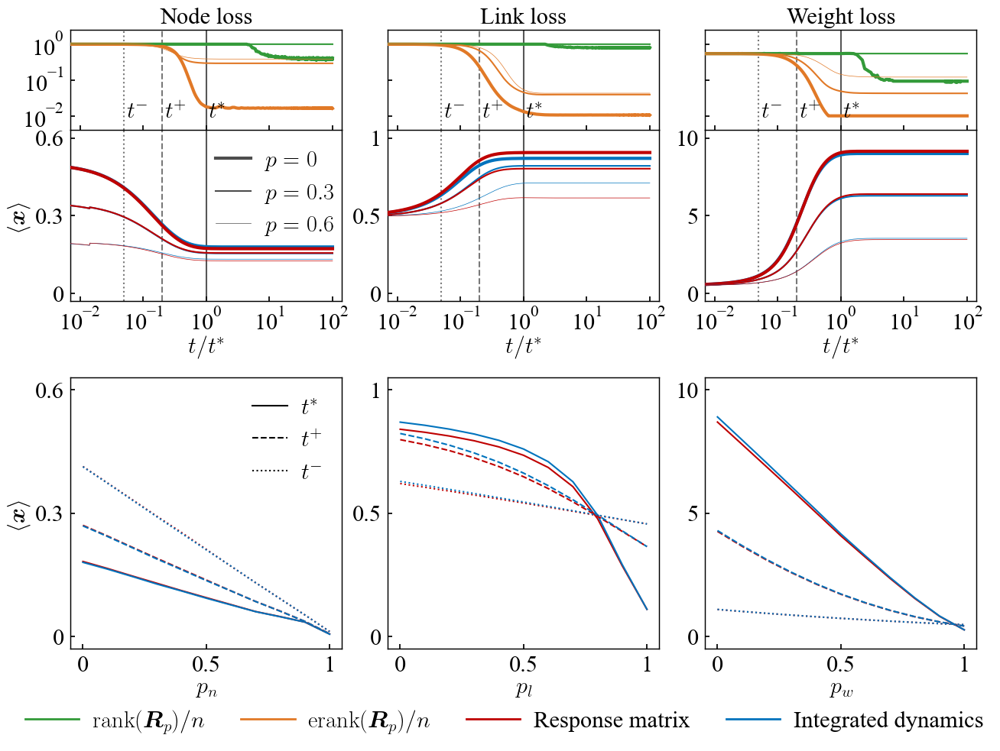

In [11]:
#Figure 2new 
r"""
FINAL REAL-DATA FIGURE
*=*=====================
This script combines Function A and Function B into the final 2 x 3 figure.
DATA
----
Function A:
    F:*\S*I*\F*unctionA*\c*ompute dataA
Function B:
    F:*\S*I*\F*unctionB*\c*ompute dataB
IMPORTANT
---------
1*\\\\.* This version uses REAL data. There are no mock/test curves.
2*\\\\.* Standard MATLAB MAT files and MATLAB v7.3 MAT files are both supported.
3*\\\\.* rank(R_p)/n and erank(R_p)/n are expensive to compute, so they are cached.
4*\\\\.* Only ONE SVD is used per response-matrix time slice to calculate BOTH
   ordinary rank and effective rank.
5*\\\\.* Set FORCE_RECOMPUTE_RANK = True only when R_p has changed and you really
   want to recompute rank/e-rank.
6*\\\\.* The final figure is exported with a fully TRANSPARENT background.
7*\\\\.* Only SVG output is generated; no PNG is saved.
8*\\\\.* The first-code Matplotlib style is preserved; real LaTeX is used only for *\\\\<*x>, rank(R_p)/n, and erank(R_p)/n.
9*\\\\.* The final figure keeps the currently confirmed layout:
   - 2 rows x 3 columns
   - no a-f labels
   - first-row upper/lower regions touch (NO internal gap)
   - symmetric internal x/y whitespace
   - No markers; quantity colors and perturbation line widths
   - Rank: green; effective rank: orange; response: red; integrated: blue
   - legends centered below the figure
   - notebook display is retained with plt.show()
"""
from __future__ import annotations
import hashlib
import os
import re
import time
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, whosmat
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
# ============================================================
# 1. PATHS
# ============================================================
BASE_A = Path(r"F:\SI\FunctionA\compute dataA")
BASE_B = Path(r"F:\SI\FunctionB\compute dataB")
# Cache is stored beside this script / notebook working directory.
CACHE_DIR = Path.cwd() / "response_matrix_rank_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
# Set True only when you need to force a fresh expensive calculation.
FORCE_RECOMPUTE_RANK = False
# Optional final output
SAVE_FIGURE = True
OUTPUT_SVG = Path.cwd() / "Figure 2.svg"
# ============================================================
# 2. FUNCTION-A PANEL DEFINITIONS
# ============================================================
PANELS_A = [
    {
        "title": "Node loss",
        "folders": [
            "4.noisy voter_Dolphin social network_perturbation_type1-0",
            "4.noisy voter_Dolphin social network_perturbation_type1-0.3",
            "4.noisy voter_Dolphin social network_perturbation_type1-0.6",
        ],
        "t_star": 5.5,
        "t_end": 550.0,
        "yticks": [0.0, 0.3, 0.6],
    },
    {
        "title": "Link loss",
        "folders": [
            "2.Epidemics (SIS)_MIT Reality Mining_perturbation_type2-0",
            "2.Epidemics (SIS)_MIT Reality Mining_perturbation_type2-0.3",
            "2.Epidemics (SIS)_MIT Reality Mining_perturbation_type2-0.6",
        ],
        "t_star": 0.3,
        "t_end": 30.0,
        "yticks": [0.0, 0.5, 1.0],
    },
    {
        "title": "Weight loss",
        "folders": [
            "6.Population_Little Rock Lake_perturbation_type3-0",
            "6.Population_Little Rock Lake_perturbation_type3-0.3",
            "6.Population_Little Rock Lake_perturbation_type3-0.6",
        ],
        "t_star": 1.4,
        "t_end": 140.0,
        "yticks": [0.0, 5.0, 10.0],
    },
]
# ============================================================
# 3. FUNCTION-B PANEL DEFINITIONS
# ============================================================
PANELS_B = [
    {
        "folder": "4.noisy voter_Dolphin social network_perturbation_type1",
        "xlabel": r"$p_n$",
        "yticks": [0.0, 0.3, 0.6],
    },
    {
        "folder": "2.Epidemics (SIS)_MIT Reality Mining_perturbation_type2",
        "xlabel": r"$p_l$",
        "yticks": [0.0, 0.5, 1.0],
    },
    {
        "folder": "6.Population_Little Rock Lake_perturbation_type3",
        "xlabel": r"$p_w$",
        "yticks": [0.0, 5.0, 10.0],
    },
]
# ============================================================
# 4. FONT CONFIGURATION
# ============================================================
# Normal Matplotlib rendering for the whole figure.
# IMPORTANT:
# Everything stays exactly in the first-code style.
# Real LaTeX is used ONLY for the following three formulas:
#   \\\\\\\<x>, rank(R_p)/n, erank(R_p)/n.
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "axes.linewidth": 1.10,
    "xtick.direction": "in",
    "ytick.direction": "in",
})
# MiKTeX is made available only so the three target formulas can use
# the exact LaTeX notation from the second code.
MIKTEX_BIN = Path(
    r"D:\Users\xuren\AppData\Local\Programs\MiKTeX\miktex\bin\x64"
)
LATEX_EXE = MIKTEX_BIN / "latex.exe"
if not LATEX_EXE.exists():
    raise FileNotFoundError(
        "MiKTeX latex.exe was not found at:\n"
        f"{LATEX_EXE}"
    )
os.environ["PATH"] = (
    str(MIKTEX_BIN)
    + os.pathsep
    + os.environ.get("PATH", "")
)
# This preamble is used only by Text objects whose usetex=True.
plt.rcParams["text.latex.preamble"] = r"\usepackage{bm}"
# EXACT formulas copied from the second code.
MEAN_STATE_LABEL = r"$\langle \bm{x}\rangle$"
TIME_AXIS_LABEL = r"$t/t^{\ast}$"
RANK_LABEL = r"$\mathrm{rank}(\bm{R}_{p})/n$"
ERANK_LABEL = r"$\mathrm{erank}(\bm{R}_{p})/n$"
# Transparent output
plt.rcParams["savefig.transparent"] = True
plt.rcParams["figure.facecolor"] = "none"
plt.rcParams["axes.facecolor"] = "none"
print("Rendering: first-code Matplotlib style; LaTeX only for *\\\\<*x>, rank(R_p)/n, erank(R_p)/n")
# ============================================================
# 5. FINAL LAYOUT PARAMETERS
# ============================================================
PANEL_SIDE = 3.55
COL_GAP = 0.60
ROW_GAP = 1.00
LEFT_MARGIN = 0.78
RIGHT_MARGIN = 0.28
TOP_MARGIN = 0.50
# Bottom area includes x labels + two legend rows.
BOTTOM_MARGIN = 1.98
# First-row combined panel:
# upper rank/e-rank + lower state curves, with NO internal gap.
TOP_FRACTION = 0.37
BOTTOM_FRACTION = 1.0 - TOP_FRACTION
# Symmetric INTERNAL axis whitespace.
LOG_X_MARGIN_DECADES = 0.15
LINEAR_X_MARGIN = 0.05
LINEAR_Y_MARGIN_RATIO = 0.05
LOG_Y_MARGIN_DECADES = 0.40
# ============================================================
# 6. FONT SIZES
# ============================================================
# Unified larger font size for titles, ticks, labels, legends, and time annotations.
TICK_FS = 22
AXIS_LABEL_FS = 22
TITLE_FS = 22
LEGEND_FS = 22
TIME_LABEL_FS = 22
# ============================================================
# 7. COLORS / MARKERS / LINE STYLES
# ============================================================
# Function A: color denotes quantity; line width decreases as p increases.
RANK_COLOR = "#339a39"
ERANK_COLOR = "#e17927"
RESPONSE_COLOR = (0.75, 0.00, 0.00)
INTEGRATED_COLOR = (0.00, 0.45, 0.74)
BASE_LINEWIDTH = 2.0
P_LINEWIDTHS = [3.0, 1.5, 0.5]
INNER_LEGEND_FS = 22
P_VALUES = [0.0, 0.3, 0.6]
P_LABELS = [r"$p=0$", r"$p=0.3$", r"$p=0.6$"]
# Function B: line style denotes time; color denotes prediction method.
T_LABELS = [r"$t^{\ast}$", r"$t^{+}$", r"$t^{-}$"]
T_LINE_STYLES = ["-", "--", ":"]
T_LINE_COLOR = "black"
# ============================================================
# 8. CLEAN NUMBER FORMATTER
# ============================================================
def clean_number(x, pos=None):
    """
    0.0 -> 0
    1.0 -> 1
    5.0 -> 5
    10.0 -> 10
    0.3 -> 0.3
    0.5 -> 0.5
    """
    if abs(x - round(x)) < 1e-10:
        return f"{int(round(x))}"
    return f"{x:g}"
clean_formatter = FuncFormatter(clean_number)
# ============================================================
# 9. MATLAB FILE HELPERS
# ============================================================
def is_mat_v73(path: Path) -> bool:
    """
    MATLAB v7.3 MAT files are HDF5 containers.
    """
    try:
        return h5py.is_hdf5(path)
    except Exception:
        return False
def _decode_hdf5_numeric_dataset(dataset):
    """
    Read a simple numeric HDF5 dataset, including compound complex arrays.
    """
    arr = np.asarray(dataset)
    if arr.dtype.fields is not None:
        names = arr.dtype.fields.keys()
        if "real" in names and "imag" in names:
            arr = arr["real"] + 1j * arr["imag"]
    return np.asarray(arr)
def load_mat_variable(path: Path, variable: str):
    """
    Load a numeric variable from:
      - MATLAB v7 and earlier
      - MATLAB v7.3
    """
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"File not found:\n{path}")
    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            if variable not in f:
                raise KeyError(
                    f"Variable '{variable}' not found in:\n{path}\n"
                    f"Available top-level variables: {list(f.keys())}"
                )
            obj = f[variable]
            if not isinstance(obj, h5py.Dataset):
                raise TypeError(
                    f"'{variable}' in {path} is not a simple numeric HDF5 dataset."
                )
            return _decode_hdf5_numeric_dataset(obj)
    data = loadmat(path)
    if variable not in data:
        available = [k for k in data if not k.startswith("__")]
        raise KeyError(
            f"Variable '{variable}' not found in:\n{path}\n"
            f"Available variables: {available}"
        )
    return np.asarray(data[variable])
def mat_keys(path: Path):
    """
    Return variable names without loading a whole large MAT file when possible.
    """
    path = Path(path)
    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            return list(f.keys())
    return [name for name, _, _ in whosmat(path)]
def find_variable_file(folder: Path, variable: str) -> Path:
    """
    Function B may store variables in one or several MAT files.
    Search recursively and return the MAT file containing *\\\\`*variable*\\\\`*.
    """
    folder = Path(folder)
    if not folder.exists():
        raise FileNotFoundError(f"Folder not found:\n{folder}")
    mat_files = sorted(folder.rglob("*.mat"))
    if not mat_files:
        raise FileNotFoundError(f"No .mat files found under:\n{folder}")
    checked = []
    for mat_file in mat_files:
        try:
            keys = mat_keys(mat_file)
            checked.append((mat_file.name, keys))
            if variable in keys:
                return mat_file
        except Exception:
            continue
    details = "\n".join(
        f"  {name}: {keys}"
        for name, keys in checked
    )
    raise KeyError(
        f"Could not find variable '{variable}' under:\n{folder}\n\n"
        f"Checked MAT files:\n{details}"
    )
def find_variable_in_folder(folder: Path, variable: str):
    path = find_variable_file(folder, variable)
    return load_mat_variable(path, variable)
# ============================================================
# 10. ARRAY / MEAN HELPERS
# ============================================================
def remove_first_entry_dim2(X):
    """
    MATLAB:
        X(:,1,:) = [];
    """
    X = np.asarray(X)
    if X.ndim != 3:
        raise ValueError(
            f"Expected a 3D array before deleting dim-2 entry; got {X.shape}"
        )
    return X[:, 1:, :]
def mean_dim1_dim3(X):
    """
    MATLAB equivalent:
        squeeze(mean(mean(X,3),1))
    For a v7.3 file read directly by h5py, the first and third MATLAB axes
    may be reversed, but both are averaged here, while the middle axis is
    retained. Therefore the resulting curve remains correct.
    """
    X = np.asarray(X)
    if X.ndim != 3:
        raise ValueError(
            f"Expected a 3D array for mean(mean(X,3),1); got {X.shape}"
        )
    return np.asarray(
        np.mean(X, axis=(0, 2))
    ).squeeze()
def ensure_1d_curve(curve, expected_len, label, source):
    curve = np.asarray(curve).squeeze()
    if curve.ndim != 1:
        raise ValueError(
            f"{label} is not 1D after averaging.\n"
            f"Source: {source}\n"
            f"Shape: {curve.shape}"
        )
    if curve.size != expected_len:
        raise ValueError(
            f"{label} length mismatch.\n"
            f"Source: {source}\n"
            f"Curve length: {curve.size}\n"
            f"Expected: {expected_len}"
        )
    return np.real_if_close(curve)
# ============================================================
# 11. FUNCTION-A TIME GRID
# ============================================================
def build_xvals(t_star, t_end):
    """
    Exact Python equivalent of:
        t2 = linspace(t_star, t_end, 500);
        tspan = [0, logspace(-5, log10(t_star), 1500), t2(2:end)];
        xVals = tspan/t_star;
    """
    t2 = np.linspace(t_star, t_end, 500)
    tspan = np.concatenate([
        np.array([0.0]),
        np.logspace(-5, np.log10(t_star), 1500),
        t2[1:],
    ])
    return tspan / t_star
# ============================================================
# 12. RESPONSE-MATRIX ORIENTATION
# ============================================================
def identify_R_orientation(shape, expected_time):
    """
    Identify which axis is time for an N x N x T response-matrix array.
    Returns:
        "NNT"  -> N x N x T
        "TNN"  -> T x N x N
        "NTN"  -> N x T x N
    """
    if len(shape) != 3:
        raise ValueError(f"R_p must be 3D; got shape {shape}")
    a, b, c = shape
    if a == b and c == expected_time:
        return "NNT"
    if a == expected_time and b == c:
        return "TNN"
    if b == expected_time and a == c:
        return "NTN"
    # Fallback if expected_time does not uniquely resolve it.
    if a == b:
        return "NNT"
    if b == c:
        return "TNN"
    if a == c:
        return "NTN"
    raise ValueError(
        f"Cannot identify square response matrices from shape {shape}"
    )
def normalize_R_array(R, expected_time):
    """
    Return standard N x N x T orientation.
    """
    R = np.asarray(R).squeeze()
    orientation = identify_R_orientation(R.shape, expected_time)
    if orientation == "NNT":
        out = R
    elif orientation == "TNN":
        out = np.transpose(R, (1, 2, 0))
    else:  # NTN
        out = np.transpose(R, (0, 2, 1))
    if out.shape[2] != expected_time:
        raise ValueError(
            f"R_p time dimension mismatch.\n"
            f"Normalized shape: {out.shape}\n"
            f"Expected time points: {expected_time}"
        )
    return out
# ============================================================
# 13. RANK / EFFECTIVE-RANK CACHE
# ============================================================
def file_fingerprint(path: Path):
    stat = Path(path).stat()
    return {
        "size": int(stat.st_size),
        "mtime_ns": int(stat.st_mtime_ns),
    }
def cache_path_for_R(path: Path):
    """
    Stable cache filename based on the full R_p path.
    """
    digest = hashlib.sha1(
        str(Path(path).resolve()).encode("utf-8")
    ).hexdigest()[:14]
    safe_parent = re.sub(
        r"[^A-Za-z0-9._-]+",
        "_",
        Path(path).parent.name,
    )[:65]
    return CACHE_DIR / f"{safe_parent}_{digest}_rank_erank.npz"
def load_rank_cache(R_path: Path, expected_time: int):
    cache_path = cache_path_for_R(R_path)
    if FORCE_RECOMPUTE_RANK or not cache_path.exists():
        return None
    fp = file_fingerprint(R_path)
    try:
        with np.load(cache_path, allow_pickle=False) as cached:
            if int(cached["file_size"]) != fp["size"]:
                return None
            if int(cached["file_mtime_ns"]) != fp["mtime_ns"]:
                return None
            if int(cached["expected_time"]) != expected_time:
                return None
            rank_vals = cached["rank_vals"]
            erank_vals = cached["erank_vals"]
        if rank_vals.size != expected_time:
            return None
        if erank_vals.size != expected_time:
            return None
        print(f"  Using cached rank/e-rank: {cache_path.name}")
        return rank_vals, erank_vals
    except Exception:
        return None
def save_rank_cache(
    R_path: Path,
    expected_time: int,
    rank_vals,
    erank_vals,
):
    cache_path = cache_path_for_R(R_path)
    fp = file_fingerprint(R_path)
    np.savez_compressed(
        cache_path,
        rank_vals=np.asarray(rank_vals, dtype=float),
        erank_vals=np.asarray(erank_vals, dtype=float),
        file_size=np.int64(fp["size"]),
        file_mtime_ns=np.int64(fp["mtime_ns"]),
        expected_time=np.int64(expected_time),
    )
    print(f"  Rank/e-rank cache saved: {cache_path.name}")
# ============================================================
# 14. ONE-SVD RANK / EFFECTIVE-RANK CALCULATION
# ============================================================
def rank_erank_from_singular_values(s, n):
    """
    Calculate BOTH ordinary rank and effective rank from ONE SVD.
    MATLAB-like rank tolerance:
        tol = max(size(A)) * eps(norm(A))
    Since norm(A) = largest singular value for the matrix 2-norm:
        tol = n * spacing(s_max)
    Effective rank:
        q_i = s_i / sum(s)
        H = -sum(q_i log q_i)
        erank = exp(H)
    """
    s = np.asarray(s, dtype=float)
    if s.size == 0 or not np.isfinite(s).any():
        return 0.0, 0.0
    s_max = float(np.max(s))
    if s_max <= 0:
        return 0.0, 0.0
    tol = n * abs(np.spacing(s_max))
    rank_normalized = np.count_nonzero(s > tol) / n
    s_sum = float(np.sum(s))
    if s_sum <= 0:
        erank_normalized = 0.0
    else:
        q = s / s_sum
        q = q[q > np.finfo(float).eps]
        if q.size == 0:
            erank_normalized = 0.0
        else:
            H = -np.sum(q * np.log(q))
            erank_normalized = np.exp(H) / n
    return float(rank_normalized), float(erank_normalized)
def _read_v73_R_slice(dataset, orientation, k):
    """
    Read one N x N response matrix from a MATLAB-v7.3 HDF5 dataset
    without loading the whole 3D R_p into memory.
    """
    if orientation == "NNT":
        arr = np.asarray(dataset[:, :, k])
    elif orientation == "TNN":
        arr = np.asarray(dataset[k, :, :])
    else:  # NTN
        arr = np.asarray(dataset[:, k, :])
    if arr.dtype.fields is not None:
        names = arr.dtype.fields.keys()
        if "real" in names and "imag" in names:
            arr = arr["real"] + 1j * arr["imag"]
    return np.asarray(arr)
def compute_rank_erank_from_R_file(
    R_path: Path,
    expected_time: int,
):
    """
    Expensive calculation.
    Uses:
      - cache if valid
      - one SVD per time slice
      - streaming HDF5 slices for MATLAB v7.3
    """
    cached = load_rank_cache(R_path, expected_time)
    if cached is not None:
        return cached
    print(f"\nComputing rank/e-rank from:\n  {R_path}")
    print("  This is the expensive step and will be cached.")
    start_time = time.time()
    rank_vals = np.zeros(expected_time, dtype=float)
    erank_vals = np.zeros(expected_time, dtype=float)
    if is_mat_v73(R_path):
        with h5py.File(R_path, "r") as f:
            if "R_p" not in f:
                raise KeyError(
                    f"Variable 'R_p' not found in:\n{R_path}"
                )
            dataset = f["R_p"]
            if not isinstance(dataset, h5py.Dataset):
                raise TypeError(
                    f"R_p in {R_path} is not a numeric HDF5 dataset."
                )
            orientation = identify_R_orientation(
                dataset.shape,
                expected_time,
            )
            if orientation == "NNT":
                n = dataset.shape[0]
                nt = dataset.shape[2]
            elif orientation == "TNN":
                n = dataset.shape[1]
                nt = dataset.shape[0]
            else:
                n = dataset.shape[0]
                nt = dataset.shape[1]
            if nt != expected_time:
                raise ValueError(
                    f"R_p time points = {nt}, expected {expected_time}\n"
                    f"Dataset shape: {dataset.shape}"
                )
            for k in range(expected_time):
                Rp = _read_v73_R_slice(
                    dataset,
                    orientation,
                    k,
                )
                s = np.linalg.svd(
                    Rp,
                    compute_uv=False,
                )
                (
                    rank_vals[k],
                    erank_vals[k],
                ) = rank_erank_from_singular_values(
                    s,
                    n,
                )
                if (
                    k == 0
                    or (k + 1) % 100 == 0
                    or k + 1 == expected_time
                ):
                    elapsed = time.time() - start_time
                    print(
                        f"  {k + 1:4d}/{expected_time} "
                        f"({100*(k+1)/expected_time:5.1f}%) "
                        f"elapsed {elapsed/60:.1f} min"
                    )
    else:
        R_raw = load_mat_variable(
            R_path,
            "R_p",
        )
        R = normalize_R_array(
            R_raw,
            expected_time,
        )
        n = R.shape[0]
        for k in range(expected_time):
            s = np.linalg.svd(
                R[:, :, k],
                compute_uv=False,
            )
            (
                rank_vals[k],
                erank_vals[k],
            ) = rank_erank_from_singular_values(
                s,
                n,
            )
            if (
                k == 0
                or (k + 1) % 100 == 0
                or k + 1 == expected_time
            ):
                elapsed = time.time() - start_time
                print(
                    f"  {k + 1:4d}/{expected_time} "
                    f"({100*(k+1)/expected_time:5.1f}%) "
                    f"elapsed {elapsed/60:.1f} min"
                )
    elapsed = time.time() - start_time
    print(
        f"  Finished rank/e-rank in {elapsed/60:.2f} min."
    )
    save_rank_cache(
        R_path,
        expected_time,
        rank_vals,
        erank_vals,
    )
    return rank_vals, erank_vals
# ============================================================
# 15. FUNCTION-A REAL DATA READER
# ============================================================
def read_function_a_panel(panel):
    x_vals = build_xvals(
        panel["t_star"],
        panel["t_end"],
    )
    expected_time = len(x_vals)
    datasets = []
    for p_value, folder_name in zip(
        P_VALUES,
        panel["folders"],
    ):
        folder = BASE_A / folder_name
        print(
            f"\nFunction A | {panel['title']} | p={p_value}"
        )
        print(f"  Folder: {folder}")
        if not folder.exists():
            raise FileNotFoundError(
                f"Function-A folder not found:\n{folder}"
            )
        X_p_path = folder / "X_p.mat"
        X_test_path = folder / "X_test.mat"
        R_path = folder / "R_p.mat"
        X_p = load_mat_variable(
            X_p_path,
            "X_p",
        )
        X_test = load_mat_variable(
            X_test_path,
            "X_test",
        )
        # MATLAB:
        # X_test(:,1,:) = [];
        X_test = remove_first_entry_dim2(
            X_test
        )
        xpre = mean_dim1_dim3(X_p)
        xobs = mean_dim1_dim3(X_test)
        xpre = ensure_1d_curve(
            xpre,
            expected_time,
            "Predicted mean state",
            X_p_path,
        )
        xobs = ensure_1d_curve(
            xobs,
            expected_time,
            "Observed mean state",
            X_test_path,
        )
        rank_vals, erank_vals = (
            compute_rank_erank_from_R_file(
                R_path,
                expected_time,
            )
        )
        datasets.append({
            "p": p_value,
            "xobs": xobs,
            "xpre": xpre,
            "rank": rank_vals,
            "erank": erank_vals,
        })
    return x_vals, datasets
# ============================================================
# 16. FUNCTION-B REAL DATA READER
# ============================================================
FUNCTION_B_VARIABLES = [
    "X_test_tstar",
    "X_test_tminus",
    "X_test_tplus",
    "X_p_tstar",
    "X_p_tminus",
    "X_p_tplus",
]
def read_function_b_panel(panel):
    folder = BASE_B / panel["folder"]
    print(
        f"\nFunction B | {panel['xlabel']}"
    )
    print(f"  Folder: {folder}")
    if not folder.exists():
        raise FileNotFoundError(
            f"Function-B folder not found:\n{folder}"
        )
    data = {}
    for variable in FUNCTION_B_VARIABLES:
        path = find_variable_file(
            folder,
            variable,
        )
        print(
            f"  {variable} <- {path.name}"
        )
        data[variable] = load_mat_variable(
            path,
            variable,
        )
    # MATLAB:
    # obs_tstar(:,1,:)  = [];
    # obs_tminus(:,1,:) = [];
    # obs_tplus(:,1,:)  = [];
    obs_tstar = remove_first_entry_dim2(
        data["X_test_tstar"]
    )
    obs_tminus = remove_first_entry_dim2(
        data["X_test_tminus"]
    )
    obs_tplus = remove_first_entry_dim2(
        data["X_test_tplus"]
    )
    pred_tstar = data["X_p_tstar"]
    pred_tminus = data["X_p_tminus"]
    pred_tplus = data["X_p_tplus"]
    curves = {
        "obs_tstar": mean_dim1_dim3(
            obs_tstar
        ),
        "obs_tminus": mean_dim1_dim3(
            obs_tminus
        ),
        "obs_tplus": mean_dim1_dim3(
            obs_tplus
        ),
        "pred_tstar": mean_dim1_dim3(
            pred_tstar
        ),
        "pred_tminus": mean_dim1_dim3(
            pred_tminus
        ),
        "pred_tplus": mean_dim1_dim3(
            pred_tplus
        ),
    }
    lengths = {
        key: np.asarray(value).size
        for key, value in curves.items()
    }
    if len(set(lengths.values())) != 1:
        raise ValueError(
            f"Function-B observed/predicted lengths differ.\n"
            f"Folder: {folder}\n"
            f"Lengths: {lengths}"
        )
    n_perturb = next(iter(lengths.values()))
    for key in curves:
        curves[key] = np.real_if_close(
            np.asarray(curves[key]).reshape(-1)
        )
    curves["x"] = np.linspace(
        0.0,
        1.0,
        n_perturb,
    )
    return curves
# ============================================================
# 17. READ ALL REAL DATA FIRST
# ============================================================
if not BASE_A.exists():
    raise FileNotFoundError(
        f"Function-A root folder not found:\n{BASE_A}"
    )
if not BASE_B.exists():
    raise FileNotFoundError(
        f"Function-B root folder not found:\n{BASE_B}"
    )
print("\n" + "=" * 72)
print("READING FUNCTION A")
print("=" * 72)
FUNCTION_A_DATA = []
for panel in PANELS_A:
    FUNCTION_A_DATA.append(
        read_function_a_panel(panel)
    )
print("\n" + "=" * 72)
print("READING FUNCTION B")
print("=" * 72)
FUNCTION_B_DATA = []
for panel in PANELS_B:
    FUNCTION_B_DATA.append(
        read_function_b_panel(panel)
    )
# ============================================================
# 18. FIGURE GEOMETRY
# ============================================================
FIG_W = (
    LEFT_MARGIN
    + 3 * PANEL_SIDE
    + 2 * COL_GAP
    + RIGHT_MARGIN
)
FIG_H = (
    BOTTOM_MARGIN
    + PANEL_SIDE
    + ROW_GAP
    + PANEL_SIDE
    + TOP_MARGIN
)
fig = plt.figure(
    figsize=(FIG_W, FIG_H),
    facecolor="none",
)
# Transparent figure canvas
fig.patch.set_alpha(0.0)
bottom_row_y = BOTTOM_MARGIN
top_row_y = (
    BOTTOM_MARGIN
    + PANEL_SIDE
    + ROW_GAP
)
top_inner_h = PANEL_SIDE * TOP_FRACTION
bottom_inner_h = PANEL_SIDE * BOTTOM_FRACTION
def inch_box(
    left_in,
    bottom_in,
    width_in,
    height_in,
):
    return [
        left_in / FIG_W,
        bottom_in / FIG_H,
        width_in / FIG_W,
        height_in / FIG_H,
    ]
axes_upper = []
axes_lower = []
axes_bottom = []
for col in range(3):
    left = (
        LEFT_MARGIN
        + col * (PANEL_SIDE + COL_GAP)
    )
    # First row lower state region.
    ax_l = fig.add_axes(
        inch_box(
            left,
            top_row_y,
            PANEL_SIDE,
            bottom_inner_h,
        )
    )
    # First row upper rank/e-rank region.
    # NO GAP: directly touches lower region.
    ax_u = fig.add_axes(
        inch_box(
            left,
            top_row_y + bottom_inner_h,
            PANEL_SIDE,
            top_inner_h,
        )
    )
    # Second row.
    ax_b = fig.add_axes(
        inch_box(
            left,
            bottom_row_y,
            PANEL_SIDE,
            PANEL_SIDE,
        )
    )
    axes_upper.append(ax_u)
    axes_lower.append(ax_l)
    axes_bottom.append(ax_b)
# ============================================================
# 19. COMMON AXIS STYLE
# ============================================================
def style_axis(ax):
    # Fully transparent axes background
    ax.set_facecolor("none")
    ax.patch.set_alpha(0.0)
    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=4.5,
        width=1.25,
        labelsize=TICK_FS,
        pad=6.0,
    )
    # No minor ticks anywhere.
    ax.minorticks_off()
    ax.tick_params(
        which="minor",
        bottom=False,
        top=False,
        left=False,
        right=False,
    )
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontname("Times New Roman")
        label.set_fontsize(TICK_FS)
    for spine in ax.spines.values():
        spine.set_linewidth(1.05)
def set_manual_log_x_ticks(ax):
    """
    Fixed log-x tick values and labels.
    """
    ticks = [1e-2, 1e-1, 1, 1e1, 1e2]
    labels = [
        r"$10^{-2}$",
        r"$10^{-1}$",
        r"$10^{0}$",
        r"$10^{1}$",
        r"$10^{2}$",
    ]
    ax.set_xticks(ticks)
    ax.set_xticklabels(
        labels,
        fontsize=TICK_FS,
    )
def set_manual_log_y_ticks(ax):
    """
    Fixed log-y tick values and labels.
    """
    ticks = [1e-2, 1e-1, 1]
    labels = [
        r"$10^{-2}$",
        r"$10^{-1}$",
        r"$10^{0}$",
    ]
    ax.set_yticks(ticks)
    ax.set_yticklabels(
        labels,
        fontsize=TICK_FS,
    )
# ============================================================
# 20. FIRST ROW: FUNCTION A
# ============================================================
for col, (
    panel,
    panel_data,
) in enumerate(
    zip(
        PANELS_A,
        FUNCTION_A_DATA,
    )
):
    ax_u = axes_upper[col]
    ax_l = axes_lower[col]
    x_vals, datasets = panel_data
    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------
    for ax in (ax_u, ax_l):
        ax.set_xscale("log")
        # Symmetric left/right whitespace in log10 space.
        ax.set_xlim(
            10**(
                -2
                - LOG_X_MARGIN_DECADES
            ),
            10**(
                2
                + LOG_X_MARGIN_DECADES
            ),
        )
        set_manual_log_x_ticks(ax)
        style_axis(ax)
    # Upper y-axis
    ax_u.set_yscale("log")
    ax_u.set_ylim(
        10**(
            -2
            - LOG_Y_MARGIN_DECADES
        ),
        10**(
            0
            + LOG_Y_MARGIN_DECADES
        ),
    )
    set_manual_log_y_ticks(ax)
    # Only the left upper panel displays the repeated y values.
    if col > 0:
        ax_u.tick_params(
            axis="y",
            labelleft=False,
        )
    # Upper x values are not duplicated.
    ax_u.tick_params(
        axis="x",
        labelbottom=False,
    )
    # Lower y-axis with symmetric internal whitespace.
    y_tick_min = min(panel["yticks"])
    y_tick_max = max(panel["yticks"])
    y_pad = (
        y_tick_max
        - y_tick_min
    ) * LINEAR_Y_MARGIN_RATIO
    ax_l.set_ylim(
        y_tick_min - y_pad,
        y_tick_max + y_pad,
    )
    ax_l.set_yticks(
        panel["yticks"]
    )
    ax_l.yaxis.set_major_formatter(
        clean_formatter
    )
    # One clean internal horizontal boundary.
    ax_u.spines["bottom"].set_visible(False)
    ax_l.spines["top"].set_linewidth(1.05)
    # --------------------------------------------------------
    # t-, t+, t*
    # --------------------------------------------------------
    t_minus = 0.05
    t_plus = 0.20
    t_star = 1.00
    for ax in (ax_u, ax_l):
        ax.axvline(
            t_minus,
            color="black",
            linestyle=":",
            linewidth=1.5,
            alpha=0.52,
            zorder=1,
        )
        ax.axvline(
            t_plus,
            color="black",
            linestyle="--",
            linewidth=1.5,
            alpha=0.52,
            zorder=1,
        )
        ax.axvline(
            t_star,
            color="black",
            linestyle="-",
            linewidth=1.5,
            alpha=0.66,
            zorder=1,
        )
    # Keep all three labels at exactly the same height
    # and just to the right of their own vertical lines.
    time_y = 10**(
        -2
        - LOG_Y_MARGIN_DECADES
    ) * 1.72
    ax_u.text(
        t_minus * 1.10,
        time_y,
        r"$t^{-}$",
        fontsize=TIME_LABEL_FS,
        ha="left",
        va="bottom",
        usetex=True,
        zorder=20,
        clip_on=False,
    )
    ax_u.text(
        t_plus * 1.10,
        time_y,
        r"$t^{+}$",
        fontsize=TIME_LABEL_FS,
        ha="left",
        va="bottom",
        usetex=True,
        zorder=20,
        clip_on=False,
    )
    ax_u.text(
        t_star * 1.10,
        time_y,
        r"$t^{\ast}$",
        fontsize=TIME_LABEL_FS,
        ha="left",
        va="bottom",
        usetex=True,
        zorder=20,
        clip_on=False,
    )
    # --------------------------------------------------------
    # Real curves for p=0, 0.3, 0.6
    # --------------------------------------------------------
    for i, dataset in enumerate(datasets):
        rank_plot = np.maximum(
            dataset["rank"],
            1e-2,
        )
        erank_plot = np.maximum(
            dataset["erank"],
            1e-2,
        )
        ax_u.plot(
            x_vals, rank_plot, color=RANK_COLOR, linewidth=P_LINEWIDTHS[i], linestyle="-",
            zorder=3,
        )
        ax_u.plot(
            x_vals, erank_plot, color=ERANK_COLOR, linewidth=P_LINEWIDTHS[i], linestyle="-",
            zorder=3,
        )
        ax_l.plot(
            x_vals, dataset["xobs"], color=INTEGRATED_COLOR, linewidth=P_LINEWIDTHS[i], linestyle="-",
            zorder=3,
        )
        ax_l.plot(
            x_vals, dataset["xpre"], color=RESPONSE_COLOR, linewidth=P_LINEWIDTHS[i], linestyle="-",
            zorder=3,
        )
    # --------------------------------------------------------
    # Titles / labels
    # --------------------------------------------------------
    ax_u.set_title(
        panel["title"],
        fontsize=TITLE_FS,
        pad=6.0,
        fontname="Times New Roman",
    )
    ax_l.set_xlabel(
        TIME_AXIS_LABEL,
        fontsize=AXIS_LABEL_FS,
        labelpad=1.0,
        usetex=True,
    )
    if col == 0:
        ax_l.set_ylabel(
            MEAN_STATE_LABEL,
            fontsize=AXIS_LABEL_FS,
            labelpad=4.0,
            usetex=True,
        )
# ============================================================
# 21. SECOND ROW: FUNCTION B
# ============================================================
for col, (
    panel,
    data,
) in enumerate(
    zip(
        PANELS_B,
        FUNCTION_B_DATA,
    )
):
    ax = axes_bottom[col]
    x = data["x"]
    # --------------------------------------------------------
    # Axis with symmetric internal whitespace
    # --------------------------------------------------------
    ax.set_xlim(
        -LINEAR_X_MARGIN,
        1 + LINEAR_X_MARGIN,
    )
    ax.set_xticks([
        0,
        0.5,
        1,
    ])
    ax.xaxis.set_major_formatter(
        clean_formatter
    )
    y_tick_min = min(
        panel["yticks"]
    )
    y_tick_max = max(
        panel["yticks"]
    )
    y_pad = (
        y_tick_max
        - y_tick_min
    ) * LINEAR_Y_MARGIN_RATIO
    ax.set_ylim(
        y_tick_min - y_pad,
        y_tick_max + y_pad,
    )
    ax.set_yticks(
        panel["yticks"]
    )
    ax.yaxis.set_major_formatter(
        clean_formatter
    )
    style_axis(ax)
    time_series = [
        (data["pred_tstar"], data["obs_tstar"], "-"),
        (data["pred_tplus"], data["obs_tplus"], "--"),
        (data["pred_tminus"], data["obs_tminus"], ":"),
    ]
    for response_curve, integrated_curve, linestyle in time_series:
        ax.plot(
            x, response_curve,
            color=RESPONSE_COLOR,
            linestyle=linestyle,
            linewidth=1.5,
            zorder=3,
        )
        ax.plot(
            x, integrated_curve,
            color=INTEGRATED_COLOR,
            linestyle=linestyle,
            linewidth=1.5,
            zorder=3,
        )
    ax.set_xlabel(
        panel["xlabel"],
        fontsize=AXIS_LABEL_FS,
        labelpad=1.0,
        usetex=True,
    )
    if col == 0:
        ax.set_ylabel(
            MEAN_STATE_LABEL,
            fontsize=AXIS_LABEL_FS,
            labelpad=4.0,
            usetex=True,
        )
# ============================================================
# 22. BOTTOM LEGEND ROW 1: QUANTITY COLORS
# ============================================================
quantity_handles = [
    Line2D([0], [0], color=color, linestyle="-", linewidth=BASE_LINEWIDTH)
    for color in (RANK_COLOR, ERANK_COLOR, RESPONSE_COLOR, INTEGRATED_COLOR)
]
quantity_labels = [
    RANK_LABEL,
    ERANK_LABEL,
    "Response matrix",
    "Integrated dynamics",
]
legend1 = fig.legend(
    quantity_handles,
    quantity_labels,
    loc="lower center",
    bbox_to_anchor=(0.50, 0.070),
    ncol=4,
    frameon=False,
    fontsize=LEGEND_FS,
    handlelength=2.30,
    columnspacing=1.55,
    handletextpad=0.58,
    borderaxespad=0.0,
)
legend1_texts = legend1.get_texts()
for idx in (0, 1):
    legend1_texts[idx].set_usetex(True)
# ============================================================
# 23. BOTTOM LEGEND ROW 2: p LINE WIDTHS + t LINE STYLES
# ============================================================
p_handles = [
    Line2D([0], [0], color="0.30", linestyle="-", linewidth=P_LINEWIDTHS[i])
    for i in range(3)
]
time_handles = [
    Line2D([0], [0], color="black",
           linestyle=T_LINE_STYLES[i], linewidth=1.5)
    for i in range(3)
]
p_legend = axes_lower[0].legend(
    p_handles, P_LABELS,
    loc="upper right", bbox_to_anchor=(1.04, 1.0),
    ncol=1, frameon=False,
    fontsize=INNER_LEGEND_FS, handlelength=1.5,
    handletextpad=0.58, borderaxespad=0.45,
)
time_legend = axes_bottom[0].legend(
    time_handles, T_LABELS,
    loc="upper right", ncol=1, frameon=False,
    fontsize=INNER_LEGEND_FS, handlelength=1.5,
    handletextpad=0.58, borderaxespad=0.45,
)
for legend in (p_legend, time_legend):
    for txt in legend.get_texts():
        txt.set_usetex(True)
# ============================================================
# ============================================================
for legend in (
    legend1,
    p_legend,
    time_legend,
):
    for txt in legend.get_texts():
        txt.set_fontname("Times New Roman")
        txt.set_fontsize(LEGEND_FS if legend is legend1 else INNER_LEGEND_FS)
# ============================================================
# 25. SAVE / SHOW
# ============================================================
if SAVE_FIGURE:
    fig.savefig(
        OUTPUT_SVG,
        format="svg",
        bbox_inches="tight",
        transparent=True,
        facecolor="none",
        edgecolor="none",
    )
    print(
        f"\nSVG saved to:\n  {OUTPUT_SVG}"
    )
plt.show()



Computing rank/e-rank from:
  F:\SI\FunctionA\compute dataA\1.Mutualistic_Coral Reefs_delete\R_p.mat
     1/2000 (  0.1%) elapsed 0.0 min
   100/2000 (  5.0%) elapsed 0.0 min
   200/2000 ( 10.0%) elapsed 0.0 min
   300/2000 ( 15.0%) elapsed 0.0 min
   400/2000 ( 20.0%) elapsed 0.0 min
   500/2000 ( 25.0%) elapsed 0.0 min
   600/2000 ( 30.0%) elapsed 0.0 min
   700/2000 ( 35.0%) elapsed 0.0 min
   800/2000 ( 40.0%) elapsed 0.0 min
   900/2000 ( 45.0%) elapsed 0.0 min
  1000/2000 ( 50.0%) elapsed 0.0 min
  1100/2000 ( 55.0%) elapsed 0.0 min
  1200/2000 ( 60.0%) elapsed 0.0 min
  1300/2000 ( 65.0%) elapsed 0.0 min
  1400/2000 ( 70.0%) elapsed 0.0 min
  1500/2000 ( 75.0%) elapsed 0.0 min
  1600/2000 ( 80.0%) elapsed 0.0 min
  1700/2000 ( 85.0%) elapsed 0.0 min
  1800/2000 ( 90.0%) elapsed 0.0 min
  1900/2000 ( 95.0%) elapsed 0.0 min
  2000/2000 (100.0%) elapsed 0.0 min
  Finished rank/e-rank in 0.00 min.


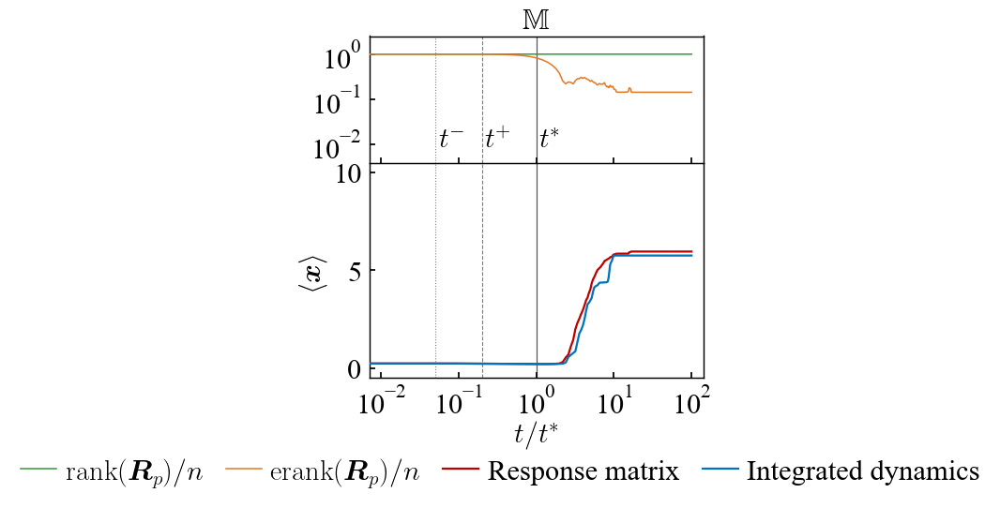

In [10]:
# Figure SI8
r"""
M dynamics  ; 1.Mutualistic_Coral Reefs_delete
To obtain both high- and low-abundance outcomes across different initial
conditions, we removed nodes 1, 3, and 7.
The initial state of each remaining node was sampled as:
    x_i(0) = x_0 + sigma * u_i,
where u_i is uniformly distributed on [0, 1), with x_0 = 0.2 and sigma = 0.1.
"""
from __future__ import annotations
import os
import time
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
# ============================================================
# 1. PATH / DATA
# ============================================================
BASE_PATH = Path(r"F:\SI\FunctionA\compute dataA")
DATA_FOLDER = "1.Mutualistic_Coral Reefs_delete"
T_STAR_RAW = 3.0
T_END_RAW = 300.0
Y_TICKS = [0.0, 5.0, 10.0]
# ============================================================
# 2. FONT CONFIGURATION
# ============================================================
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "axes.linewidth": 1.10,
    "xtick.direction": "in",
    "ytick.direction": "in",
})
MIKTEX_BIN = Path(
    r"D:\Users\xuren\AppData\Local\Programs\MiKTeX\miktex\bin\x64"
)
LATEX_EXE = MIKTEX_BIN / "latex.exe"
if not LATEX_EXE.exists():
    raise FileNotFoundError(
        "MiKTeX latex.exe was not found at:\n"
        f"{LATEX_EXE}"
    )
os.environ["PATH"] = str(MIKTEX_BIN) + os.pathsep + os.environ.get("PATH", "")
plt.rcParams["text.latex.preamble"] = r"\usepackage{bm,amssymb}"
MEAN_STATE_LABEL = r"$\langle\bm{x}\rangle$"
TIME_AXIS_LABEL = r"$t/t^{\ast}$"
RANK_LABEL = r"$\mathrm{rank}(\bm{R}_{p})/n$"
ERANK_LABEL = r"$\mathrm{erank}(\bm{R}_{p})/n$"
plt.rcParams["figure.facecolor"] = "none"
plt.rcParams["axes.facecolor"] = "none"
# ============================================================
# 3. LAYOUT / STYLE
# ============================================================
FIG_W = 4.65
FIG_H = 5.25
LEFT = 0.20
RIGHT = 0.965
BOTTOM = 0.245
TOP = 0.94
TOP_FRACTION = 0.37
BOTTOM_FRACTION = 1.0 - TOP_FRACTION
LOG_X_MARGIN_DECADES = 0.15
LOG_Y_MARGIN_DECADES = 0.40
LINEAR_Y_MARGIN_RATIO = 0.05
TICK_FS = 22
AXIS_LABEL_FS = 22
TITLE_FS = 22
LEGEND_FS = 22
TIME_LABEL_FS = 22
RANK_COLOR = "#339a39"
ERANK_COLOR = "#e17927"
RESPONSE_COLOR = (0.75, 0.00, 0.00)
INTEGRATED_COLOR = (0.00, 0.45, 0.74)
# ============================================================
# 4. HELPERS
# ============================================================
def clean_number(x, pos=None):
    if abs(x - round(x)) < 1e-10:
        return f"{int(round(x))}"
    return f"{x:g}"
clean_formatter = FuncFormatter(clean_number)
def is_mat_v73(path: Path) -> bool:
    try:
        return h5py.is_hdf5(path)
    except Exception:
        return False
def decode_hdf5_numeric_dataset(dataset):
    arr = np.asarray(dataset)
    if arr.dtype.fields is not None:
        names = arr.dtype.fields.keys()
        if "real" in names and "imag" in names:
            arr = arr["real"] + 1j * arr["imag"]
    return np.asarray(arr)
def load_mat_variable(path: Path, variable: str):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"File not found:\n{path}")
    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            if variable not in f:
                raise KeyError(
                    f"Variable '{variable}' not found in:\n{path}\n"
                    f"Available variables: {list(f.keys())}"
                )
            obj = f[variable]
            if not isinstance(obj, h5py.Dataset):
                raise TypeError(
                    f"'{variable}' in {path} is not a numeric HDF5 dataset."
                )
            return decode_hdf5_numeric_dataset(obj)
    data = loadmat(path)
    if variable not in data:
        available = [k for k in data if not k.startswith("__")]
        raise KeyError(
            f"Variable '{variable}' not found in:\n{path}\n"
            f"Available variables: {available}"
        )
    return np.asarray(data[variable])
def remove_first_entry_dim2(X):
    X = np.asarray(X)
    if X.ndim != 3:
        raise ValueError(
            f"Expected a 3D array before deleting dim-2 entry; got {X.shape}"
        )
    return X[:, 1:, :]
def mean_dim1_dim3(X):
    X = np.asarray(X)
    if X.ndim != 3:
        raise ValueError(
            f"Expected a 3D array for mean(mean(X,3),1); got {X.shape}"
        )
    return np.asarray(np.mean(X, axis=(0, 2))).squeeze()
def ensure_1d_curve(curve, expected_len, label, source):
    curve = np.asarray(curve).squeeze()
    if curve.ndim != 1:
        raise ValueError(
            f"{label} is not 1D after averaging.\n"
            f"Source: {source}\n"
            f"Shape: {curve.shape}"
        )
    if curve.size != expected_len:
        raise ValueError(
            f"{label} length mismatch.\n"
            f"Source: {source}\n"
            f"Curve length: {curve.size}\n"
            f"Expected: {expected_len}"
        )
    return np.real_if_close(curve)
def build_xvals(t_star, t_end):
    t2 = np.linspace(t_star, t_end, 500)
    tspan = np.concatenate([
        np.array([0.0]),
        np.logspace(-5, np.log10(t_star), 1500),
        t2[1:],
    ])
    return tspan / t_star
def identify_R_orientation(shape, expected_time):
    if len(shape) != 3:
        raise ValueError(f"R_p must be 3D; got shape {shape}")
    a, b, c = shape
    if a == b and c == expected_time:
        return "NNT"
    if a == expected_time and b == c:
        return "TNN"
    if b == expected_time and a == c:
        return "NTN"
    if a == b:
        return "NNT"
    if b == c:
        return "TNN"
    if a == c:
        return "NTN"
    raise ValueError(
        f"Cannot identify square response matrices from shape {shape}"
    )
def normalize_R_array(R, expected_time):
    R = np.asarray(R).squeeze()
    orientation = identify_R_orientation(R.shape, expected_time)
    if orientation == "NNT":
        out = R
    elif orientation == "TNN":
        out = np.transpose(R, (1, 2, 0))
    else:
        out = np.transpose(R, (0, 2, 1))
    if out.shape[2] != expected_time:
        raise ValueError(
            f"R_p time dimension mismatch.\n"
            f"Normalized shape: {out.shape}\n"
            f"Expected time points: {expected_time}"
        )
    return out
def rank_erank_from_singular_values(s, n):
    s = np.asarray(s, dtype=float)
    if s.size == 0 or not np.isfinite(s).any():
        return 0.0, 0.0
    s_max = float(np.max(s))
    if s_max <= 0:
        return 0.0, 0.0
    tol = n * abs(np.spacing(s_max))
    rank_normalized = np.count_nonzero(s > tol) / n
    s_sum = float(np.sum(s))
    if s_sum <= 0:
        erank_normalized = 0.0
    else:
        q = s / s_sum
        q = q[q > np.finfo(float).eps]
        if q.size == 0:
            erank_normalized = 0.0
        else:
            H = -np.sum(q * np.log(q))
            erank_normalized = np.exp(H) / n
    return float(rank_normalized), float(erank_normalized)
def read_v73_R_slice(dataset, orientation, k):
    if orientation == "NNT":
        arr = np.asarray(dataset[:, :, k])
    elif orientation == "TNN":
        arr = np.asarray(dataset[k, :, :])
    else:
        arr = np.asarray(dataset[:, k, :])
    if arr.dtype.fields is not None:
        names = arr.dtype.fields.keys()
        if "real" in names and "imag" in names:
            arr = arr["real"] + 1j * arr["imag"]
    return np.asarray(arr)
def compute_rank_erank_from_R_file(R_path: Path, expected_time: int):
    print(f"\nComputing rank/e-rank from:\n  {R_path}")
    start_time = time.time()
    rank_vals = np.zeros(expected_time, dtype=float)
    erank_vals = np.zeros(expected_time, dtype=float)
    if is_mat_v73(R_path):
        with h5py.File(R_path, "r") as f:
            if "R_p" not in f:
                raise KeyError(
                    f"Variable 'R_p' not found in:\n{R_path}"
                )
            dataset = f["R_p"]
            orientation = identify_R_orientation(
                dataset.shape,
                expected_time,
            )
            if orientation == "NNT":
                n = dataset.shape[0]
                nt = dataset.shape[2]
            elif orientation == "TNN":
                n = dataset.shape[1]
                nt = dataset.shape[0]
            else:
                n = dataset.shape[0]
                nt = dataset.shape[1]
            if nt != expected_time:
                raise ValueError(
                    f"R_p time points = {nt}, expected {expected_time}\n"
                    f"Dataset shape: {dataset.shape}"
                )
            for k in range(expected_time):
                Rp = read_v73_R_slice(
                    dataset,
                    orientation,
                    k,
                )
                s = np.linalg.svd(
                    Rp,
                    compute_uv=False,
                )
                rank_vals[k], erank_vals[k] = (
                    rank_erank_from_singular_values(
                        s,
                        n,
                    )
                )
                if (
                    k == 0
                    or (k + 1) % 100 == 0
                    or k + 1 == expected_time
                ):
                    elapsed = time.time() - start_time
                    print(
                        f"  {k + 1:4d}/{expected_time} "
                        f"({100*(k+1)/expected_time:5.1f}%) "
                        f"elapsed {elapsed/60:.1f} min"
                    )
    else:
        R = normalize_R_array(
            load_mat_variable(
                R_path,
                "R_p",
            ),
            expected_time,
        )
        n = R.shape[0]
        for k in range(expected_time):
            s = np.linalg.svd(
                R[:, :, k],
                compute_uv=False,
            )
            rank_vals[k], erank_vals[k] = (
                rank_erank_from_singular_values(
                    s,
                    n,
                )
            )
            if (
                k == 0
                or (k + 1) % 100 == 0
                or k + 1 == expected_time
            ):
                elapsed = time.time() - start_time
                print(
                    f"  {k + 1:4d}/{expected_time} "
                    f"({100*(k+1)/expected_time:5.1f}%) "
                    f"elapsed {elapsed/60:.1f} min"
                )
    print(
        f"  Finished rank/e-rank in "
        f"{(time.time()-start_time)/60:.2f} min."
    )
    return rank_vals, erank_vals
def style_axis(ax):
    ax.set_facecolor("none")
    ax.patch.set_alpha(0.0)
    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=4.5,
        width=1.25,
        labelsize=TICK_FS,
        pad=6.0,
    )
    ax.minorticks_off()
    ax.tick_params(
        which="minor",
        bottom=False,
        top=False,
        left=False,
        right=False,
    )
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontname("Times New Roman")
        label.set_fontsize(TICK_FS)
    for spine in ax.spines.values():
        spine.set_linewidth(1.05)
def set_manual_log_x_ticks(ax):
    ax.set_xticks([
        1e-2,
        1e-1,
        1,
        1e1,
        1e2,
    ])
    ax.set_xticklabels([
        r"$10^{-2}$",
        r"$10^{-1}$",
        r"$10^{0}$",
        r"$10^{1}$",
        r"$10^{2}$",
    ], fontsize=TICK_FS)
def set_manual_log_y_ticks(ax):
    ax.set_yticks([
        1e-2,
        1e-1,
        1,
    ])
    ax.set_yticklabels([
        r"$10^{-2}$",
        r"$10^{-1}$",
        r"$10^{0}$",
    ], fontsize=TICK_FS)
# ============================================================
# 5. REAL-TIME DATA LOADING / CALCULATION
# ============================================================
folder = BASE_PATH / DATA_FOLDER
if not folder.exists():
    raise FileNotFoundError(
        f"Folder not found:\n{folder}"
    )
X_p_path = folder / "X_p.mat"
X_test_path = folder / "X_test.mat"
R_path = folder / "R_p.mat"
x_vals = build_xvals(
    T_STAR_RAW,
    T_END_RAW,
)
expected_time = len(x_vals)
X_p = load_mat_variable(
    X_p_path,
    "X_p",
)
X_test = load_mat_variable(
    X_test_path,
    "X_test",
)
X_test = remove_first_entry_dim2(
    X_test
)
xpre = ensure_1d_curve(
    mean_dim1_dim3(
        X_p
    ),
    expected_time,
    "Predicted mean state",
    X_p_path,
)
xobs = ensure_1d_curve(
    mean_dim1_dim3(
        X_test
    ),
    expected_time,
    "Observed mean state",
    X_test_path,
)
rank_vals, erank_vals = (
    compute_rank_erank_from_R_file(
        R_path,
        expected_time,
    )
)
rank_plot = np.maximum(
    rank_vals,
    1e-2,
)
erank_plot = np.maximum(
    erank_vals,
    1e-2,
)
# ============================================================
# 6. FIGURE GEOMETRY
# ============================================================
fig = plt.figure(
    figsize=(FIG_W, FIG_H),
    facecolor="none",
)
fig.patch.set_alpha(0.0)
total_height = TOP - BOTTOM
upper_h = total_height * TOP_FRACTION
lower_h = total_height * BOTTOM_FRACTION
ax_l = fig.add_axes([
    LEFT,
    BOTTOM,
    RIGHT - LEFT,
    lower_h,
])
ax_u = fig.add_axes([
    LEFT,
    BOTTOM + lower_h,
    RIGHT - LEFT,
    upper_h,
])
# ============================================================
# 7. AXIS SETTINGS
# ============================================================
for ax in (
    ax_u,
    ax_l,
):
    ax.set_xscale(
        "log"
    )
    ax.set_xlim(
        10**(
            -2
            - LOG_X_MARGIN_DECADES
        ),
        10**(
            2
            + LOG_X_MARGIN_DECADES
        ),
    )
    set_manual_log_x_ticks(
        ax
    )
    style_axis(
        ax
    )
ax_u.set_yscale(
    "log"
)
ax_u.set_ylim(
    10**(
        -2
        - LOG_Y_MARGIN_DECADES
    ),
    10**(
        0
        + LOG_Y_MARGIN_DECADES
    ),
)
set_manual_log_y_ticks(
    ax_u
)
ax_u.tick_params(
    axis="x",
    labelbottom=False,
)
y_tick_min = min(
    Y_TICKS
)
y_tick_max = max(
    Y_TICKS
)
y_pad = (
    y_tick_max
    - y_tick_min
) * LINEAR_Y_MARGIN_RATIO
ax_l.set_ylim(
    y_tick_min - y_pad,
    y_tick_max + y_pad,
)
ax_l.set_yticks(
    Y_TICKS
)
ax_l.yaxis.set_major_formatter(
    clean_formatter
)
ax_u.spines[
    "bottom"
].set_visible(
    False
)
ax_l.spines[
    "top"
].set_linewidth(
    1.05
)
# ============================================================
# 8. t-, t+, t*
# ============================================================
t_minus = 0.05
t_plus = 0.20
t_star = 1.00
for ax in (
    ax_u,
    ax_l,
):
    ax.axvline(
        t_minus,
        color="black",
        linestyle=":",
        linewidth=0.78,
        alpha=0.52,
        zorder=1,
    )
    ax.axvline(
        t_plus,
        color="black",
        linestyle="--",
        linewidth=0.78,
        alpha=0.52,
        zorder=1,
    )
    ax.axvline(
        t_star,
        color="black",
        linestyle="-",
        linewidth=0.90,
        alpha=0.66,
        zorder=1,
    )
time_y = (
    10**(
        -2
        - LOG_Y_MARGIN_DECADES
    )
    * 1.72
)
ax_u.text(
    t_minus * 1.10,
    time_y,
    r"$t^{-}$",
    fontsize=TIME_LABEL_FS,
    ha="left",
    va="bottom",
    usetex=True,
    zorder=20,
    clip_on=False,
)
ax_u.text(
    t_plus * 1.10,
    time_y,
    r"$t^{+}$",
    fontsize=TIME_LABEL_FS,
    ha="left",
    va="bottom",
    usetex=True,
    zorder=20,
    clip_on=False,
)
ax_u.text(
    t_star * 1.10,
    time_y,
    r"$t^{\ast}$",
    fontsize=TIME_LABEL_FS,
    ha="left",
    va="bottom",
    usetex=True,
    zorder=20,
    clip_on=False,
)
# ============================================================
# 9. MARKER POSITIONS
# ============================================================
state_marker_targets = [
    1e-2,
    1e-1,
    1,
    1e1,
    1e2,
]
marker_bottom = [
    int(
        np.argmin(
            np.abs(
                x_vals
                - target
            )
        )
    )
    for target
    in state_marker_targets
]
marker_top = [
    int(
        np.argmin(
            np.abs(
                x_vals
                - target
            )
        )
    )
    for target
    in np.logspace(
        -2,
        2,
        20,
    )
]
# ============================================================
# 10. PLOT
# ============================================================
ax_u.plot(
    x_vals,
    rank_plot,
    color=RANK_COLOR,
    linewidth=1.10,
    linestyle="-",
    zorder=3,
)
ax_u.plot(
    x_vals,
    erank_plot,
    color=ERANK_COLOR,
    linewidth=1.10,
    linestyle="-",
    zorder=3,
)
ax_l.plot(
    x_vals,
    xpre,
    color=RESPONSE_COLOR,
    linewidth=1.62,
    linestyle="-",
    zorder=3,
)
ax_l.plot(
    x_vals,
    xobs,
    color=INTEGRATED_COLOR,
    linewidth=1.62,
    linestyle="-",
    zorder=3,
)
ax_u.set_title(
    r"$\mathbb{M}$",
    fontsize=TITLE_FS,
    pad=6.0,
    usetex=True,
)
ax_l.set_xlabel(
    TIME_AXIS_LABEL,
    fontsize=AXIS_LABEL_FS,
    labelpad=1.0,
    usetex=True,
)
ax_l.set_ylabel(
    MEAN_STATE_LABEL,
    fontsize=AXIS_LABEL_FS,
    labelpad=4.0,
    usetex=True,
)
# ============================================================
# 11. LEGEND
# ============================================================
legend_handles = [
    Line2D([0], [0], color=RANK_COLOR, linestyle="-", linewidth=1.10),
    Line2D([0], [0], color=ERANK_COLOR, linestyle="-", linewidth=1.10),
    Line2D([0], [0], color=RESPONSE_COLOR, linestyle="-", linewidth=1.62),
    Line2D([0], [0], color=INTEGRATED_COLOR, linestyle="-", linewidth=1.62),
]
legend_labels = [
    RANK_LABEL,
    ERANK_LABEL,
    "Response matrix",
    "Integrated dynamics",
]
legend1 = fig.legend(
    legend_handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(
        0.50,
        -0.0,
    ),
    ncol=4,
    frameon=False,
    fontsize=LEGEND_FS,
    handlelength=1.25,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0.0,
)
for idx in (
    0,
    1,
):
    legend1.get_texts()[
        idx
    ].set_usetex(
        True
    )
for txt in legend1.get_texts():
    txt.set_fontname(
        "Times New Roman"
    )
    txt.set_fontsize(
        LEGEND_FS
    )
OUTPUT_SVG = Path("Figure SI8.svg")
fig.savefig(
    OUTPUT_SVG,
    format="svg",
    transparent=True,
    bbox_inches="tight",
)
# ============================================================
# 12. SHOW ONLY
# ============================================================
plt.show()



Noisy voter | Node loss
Folder: F:\NP-real\1Coding\1Main function\compute data\4.noisy voter_Dolphin social network_perturbation_type1
Found 100 training files.
Number of perturbations P = 62
Number of nodes N = 62
R_p.mat has been saved.
X_p.mat has been saved.

Noisy voter | Link loss
Folder: F:\NP-real\1Coding\1Main function\compute data\4.noisy voter_Dolphin social network_perturbation_type2
Found 100 training files.
Number of perturbations P = 41
Number of nodes N = 62
R_p.mat has been saved.
X_p.mat has been saved.

Noisy voter | Weight loss
Folder: F:\NP-real\1Coding\1Main function\compute data\4.noisy voter_Dolphin social network_perturbation_type3
Found 100 training files.
Number of perturbations P = 21
Number of nodes N = 62
R_p.mat has been saved.
X_p.mat has been saved.

Epidemics | Node loss
Folder: F:\NP-real\1Coding\1Main function\compute data\2.Epidemics (SIS)_MIT Reality Mining_perturbation_type1
Found 100 training files.
Number of perturbations P = 48
Number of nodes

C:\Users\xuren\AppData\Local\Temp\ipykernel_8376\3997027770.py:307: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 183. Using truncated SVD pseudoinverse. tau = 4.648e-09
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Population | Link loss
Folder: F:\NP-real\1Coding\1Main function\compute data\6.Population_Little Rock Lake_perturbation_type2
Found 100 training files.
Number of perturbations P = 51
Number of nodes N = 183


C:\Users\xuren\AppData\Local\Temp\ipykernel_8376\3997027770.py:307: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 183. Using truncated SVD pseudoinverse. tau = 4.576e-09
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Population | Weight loss
Folder: F:\NP-real\1Coding\1Main function\compute data\6.Population_Little Rock Lake_perturbation_type3
Found 100 training files.
Number of perturbations P = 21
Number of nodes N = 183


C:\Users\xuren\AppData\Local\Temp\ipykernel_8376\3997027770.py:307: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 183. Using truncated SVD pseudoinverse. tau = 4.585e-09
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.
Noisy voter y-axis: -0.03 to 0.63; ticks = [0.0, 0.3, 0.6]
Epidemics y-axis: -0.07 to 1.47; ticks = [0.0, 0.7, 1.4]
Population y-axis: -0.55 to 11.55; ticks = [0.0, 5.5, 11.0]

Figure 3 SVG saved to:
  f:\NP-real\Figure 3.svg


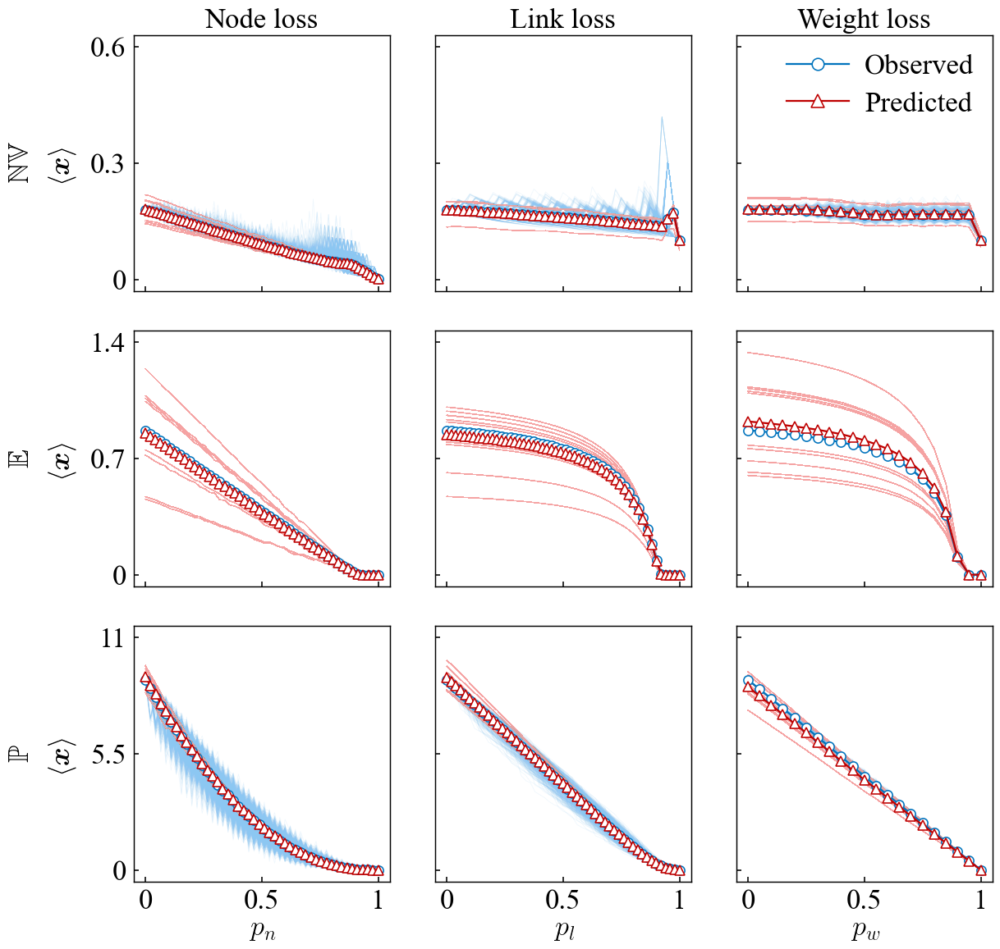

In [12]:
#Figure 3 
"""
3 x 3 response-matrix figure:
all independent realizations + mean curves
Rows (dynamics)
---------------
1. Noisy voter  ->  NV
2. Epidemics    ->  E
3. Population   ->  P
Columns (perturbations)
-----------------------
1. Node loss
2. Link loss
3. Weight loss
For every panel
---------------
- Light blue curves  : each realization of Observed states
- Light red curves   : each realization of Predicted states
- Blue circles/line  : mean Observed states
- Red triangles/line : mean Predicted states
Important
---------
- NO SEM band in this version.
- All realizations are displayed, but with low opacity.
- The three panels in the SAME ROW use exactly the SAME y-axis limits/ticks.
- Only the first column shows y tick labels.
- NV / E / P are strictly aligned in one fixed vertical column.
- All <x> labels are strictly aligned in a second fixed vertical column.
- Legend is inside the last panel (bottom-right), upper right.
- No relative-error calculation.
- Figure is saved as "Figure 3.svg".
- Dense realization curves are rasterized inside the SVG to reduce file size.
- Mean curves, markers, axes, labels, and legend remain vector.
- R_p.mat and X_p.mat are still calculated and saved.
- Final figure is shown only in the notebook with plt.show().
"""
from __future__ import annotations
import os
import time
import warnings
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from matplotlib.ticker import FuncFormatter

# ============================================================
# 1. PATH

# ============================================================
BASE_PATH = Path(r"F:\NP-real\1Coding\1Main function\compute data")
OUTPUT_SVG = Path.cwd() / "Figure 3.svg"

# ============================================================
# 2. DYNAMICS / PERTURBATIONS

# ============================================================
DYNAMICS = [
    {
        "name": "Noisy voter",
        "symbol": r"$\mathbb{NV}$",
        "folder_prefix": "4.noisy voter_Dolphin social network",
        "yticks": [0.0, 0.30, 0.60],
    },
    {
        "name": "Epidemics",
        "symbol": r"$\mathbb{E}$",
        "folder_prefix": "2.Epidemics (SIS)_MIT Reality Mining",
        "yticks": [0.0, 0.70, 1.40],
    },
    {
        "name": "Population",
        "symbol": r"$\mathbb{P}$",
        "folder_prefix": "6.Population_Little Rock Lake",
        "yticks": [0.0, 5.5, 11.0],
    },
]
PERTURBATIONS = [
    {
        "suffix": "_perturbation_type1",
        "title": "Node loss",
        "xlabel": r"$p_n$",
    },
    {
        "suffix": "_perturbation_type2",
        "title": "Link loss",
        "xlabel": r"$p_l$",
    },
    {
        "suffix": "_perturbation_type3",
        "title": "Weight loss",
        "xlabel": r"$p_w$",
    },
]

# ============================================================
# 3. FONT / STYLE
#    Matches the confirmed Figure 2 settings

# ============================================================
TICK_FS = 25
AXIS_LABEL_FS = 25
TITLE_FS = 25
LEGEND_FS = 25
ROW_SYMBOL_FS = 25
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "axes.linewidth": 1.10,
    "xtick.direction": "in",
    "ytick.direction": "in",
})
# Keep ordinary text as text in SVG where possible.
plt.rcParams["svg.fonttype"] = "none"
# Same MiKTeX path as the confirmed Figure 2 script.
MIKTEX_BIN = Path(
    r"D:\Users\xuren\AppData\Local\Programs\MiKTeX\miktex\bin\x64"
)
LATEX_EXE = MIKTEX_BIN / "latex.exe"
USE_REAL_LATEX = LATEX_EXE.exists()
if USE_REAL_LATEX:
    os.environ["PATH"] = (
        str(MIKTEX_BIN)
        + os.pathsep
        + os.environ.get("PATH", "")
    )
    plt.rcParams["text.latex.preamble"] = (
        r"\usepackage{amsmath,amssymb,bm}"
    )
    MEAN_STATE_LABEL = r"$\langle \bm{x}\rangle$"
else:
    warnings.warn(
        "MiKTeX latex.exe was not found. "
        "Matplotlib mathtext will be used for mathematical labels."
    )
    MEAN_STATE_LABEL = r"$\langle \mathbf{x}\rangle$"

# ============================================================
# 4. COLORS / LINES / MARKERS

# ============================================================
BLUE = (0.00, 0.45, 0.74)
RED = (0.75, 0.00, 0.00)
# Very light realization colors
BLUE_LIGHT = (0.55, 0.78, 0.95)
RED_LIGHT = (0.96, 0.64, 0.64)
REALIZATION_LINEWIDTH = 0.55
REALIZATION_ALPHA = 0.14
MEAN_LINEWIDTH = 1.62
MARKER_SIZE = 8.1
N_VISIBLE_MARKERS = 5

# ============================================================
# 5. FIGURE GEOMETRY
#    More left margin so row symbols and <x> do not overlap.

# ============================================================
PANEL_SIDE = 3.12
COL_GAP = 0.55
ROW_GAP = 0.48
LEFT_MARGIN = 1.70
RIGHT_MARGIN = 0.32
TOP_MARGIN = 0.58
BOTTOM_MARGIN = 0.95
FIG_W = (
    LEFT_MARGIN
    + 3 * PANEL_SIDE
    + 2 * COL_GAP
    + RIGHT_MARGIN
)
FIG_H = (
    BOTTOM_MARGIN
    + 3 * PANEL_SIDE
    + 2 * ROW_GAP
    + TOP_MARGIN
)
LINEAR_X_MARGIN = 0.05
Y_TICK_MARGIN_RATIO = 0.05

# ============================================================
# 6. FORMATTER

# ============================================================

def clean_number(x, pos=None):
    if abs(x - round(x)) < 1e-10:
        return f"{int(round(x))}"
    return f"{x:g}"
CLEAN_FORMATTER = FuncFormatter(clean_number)

# ============================================================
# 7. MATLAB FILE HELPERS

# ============================================================

def is_mat_v73(path: Path) -> bool:
    try:
        return h5py.is_hdf5(path)
    except Exception:
        return False

def _decode_hdf5_numeric_dataset(dataset):
    """
    Read a numeric MATLAB-v7.3 HDF5 dataset.
    MATLAB arrays are commonly exposed by h5py with reversed dimension
    order, so all axes are reversed here to recover MATLAB-like order.
    """
    arr = np.asarray(dataset)
    if arr.dtype.fields is not None:
        fields = arr.dtype.fields.keys()
        if "real" in fields and "imag" in fields:
            arr = arr["real"] + 1j * arr["imag"]
    if arr.ndim >= 2:
        arr = np.transpose(
            arr,
            axes=tuple(range(arr.ndim - 1, -1, -1)),
        )
    return np.asarray(arr)

def load_mat_variable(path: Path, variable: str):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"File not found:\n{path}")
    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            if variable not in f:
                raise KeyError(
                    f"Variable '{variable}' not found in:\n{path}\n"
                    f"Available variables: {list(f.keys())}"
                )
            obj = f[variable]
            if not isinstance(obj, h5py.Dataset):
                raise TypeError(
                    f"Variable '{variable}' in {path} "
                    "is not a simple numeric HDF5 dataset."
                )
            return _decode_hdf5_numeric_dataset(obj)
    data = loadmat(path)
    if variable not in data:
        available = [
            k for k in data.keys()
            if not k.startswith("__")
        ]
        raise KeyError(
            f"Variable '{variable}' not found in:\n{path}\n"
            f"Available variables: {available}"
        )
    return np.asarray(data[variable])

def load_first_data_variable(path: Path):
    path = Path(path)
    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            keys = [
                k for k in f.keys()
                if not k.startswith("#")
            ]
            if not keys:
                raise ValueError(
                    f"No usable variables found in:\n{path}"
                )
            return _decode_hdf5_numeric_dataset(
                f[keys[0]]
            )
    data = loadmat(path)
    keys = [
        k for k in data.keys()
        if not k.startswith("__")
    ]
    if not keys:
        raise ValueError(
            f"No usable variables found in:\n{path}"
        )
    return np.asarray(
        data[keys[0]]
    )

# ============================================================
# 8. TRUNCATED-SVD PSEUDOINVERSE

# ============================================================

def pinv_trunc(A, rel_tol=1e-10):
    A = np.asarray(A, dtype=float)
    U, s, Vh = np.linalg.svd(
        A,
        full_matrices=False,
    )
    if s.size == 0:
        return np.zeros_like(A.T)
    tau = rel_tol * (
        float(np.max(s))
        + np.finfo(float).eps
    )
    keep = s > tau
    rank_num = int(np.sum(keep))
    n = min(A.shape)
    if rank_num < n:
        warnings.warn(
            "Matrix is near-singular: "
            f"numerical rank = {rank_num} < {n}. "
            "Using truncated SVD pseudoinverse. "
            f"tau = {tau:.3e}",
            RuntimeWarning,
        )
        time.sleep(2)
    s_inv = np.zeros_like(s)
    s_inv[keep] = 1.0 / s[keep]
    # MATLAB:
    # V * diag(s_inv) * U.'
    return (
        Vh.T
        * s_inv
    ) @ U.T

# ============================================================
# 9. PROCESS ONE CASE

# ============================================================

def process_one_case(folder: Path, case_name: str):
    folder = Path(folder)
    print("\n" + "=" * 76)
    print(case_name)
    print(f"Folder: {folder}")
    print("=" * 76)
    if not folder.exists():
        raise FileNotFoundError(
            f"Folder not found:\n{folder}"
        )
    # --------------------------------------------------------
    # 9.1 Training files
    # --------------------------------------------------------
    files = sorted(
        folder.glob("x0*.mat"),
        key=lambda p: p.name,
    )
    M = len(files)
    print(f"Found {M} training files.")
    if M == 0:
        raise FileNotFoundError(
            f"No x0*.mat training files found in:\n{folder}"
        )
    first_outputs = load_mat_variable(
        files[0],
        "outputs",
    )
    if first_outputs.ndim != 3:
        raise ValueError(
            "'outputs' must be a 3D array.\n"
            f"File: {files[0]}\n"
            f"Shape: {first_outputs.shape}"
        )
    _, P, N = first_outputs.shape
    print(f"Number of perturbations P = {P}")
    print(f"Number of nodes N = {N}")
    X0 = np.zeros(
        (M, N),
        dtype=float,
    )
    Xbar = np.zeros(
        (M, P, N),
        dtype=float,
    )
    for i, mat_file in enumerate(files):
        outputs = load_mat_variable(
            mat_file,
            "outputs",
        )
        x0 = load_mat_variable(
            mat_file,
            "x0",
        )
        if outputs.ndim != 3:
            raise ValueError(
                f"'outputs' in {mat_file.name} "
                f"must be 3D; got {outputs.shape}"
            )
        if outputs.shape[1:] != (P, N):
            raise ValueError(
                f"Unexpected outputs shape in {mat_file.name}: "
                f"{outputs.shape}; expected (*, {P}, {N})"
            )
        x0_flat = np.asarray(
            x0
        ).reshape(-1)
        if x0_flat.size != N:
            raise ValueError(
                f"Unexpected x0 size in {mat_file.name}: "
                f"{x0_flat.size}; expected {N}"
            )
        X0[i, :] = x0_flat
        # MATLAB:
        # Xbar(i,:,:) = mean(outputs, 1)
        Xbar[i, :, :] = np.mean(
            outputs,
            axis=0,
        )
    # --------------------------------------------------------
    # 9.2 Response matrices
    # --------------------------------------------------------
    C00 = (
        X0.T @ X0
    ) / M
    C00_inv = pinv_trunc(
        C00
    )
    R_p = np.zeros(
        (N, N, P),
        dtype=float,
    )
    for p in range(P):
        Xp = Xbar[:, p, :]
        Cp0 = (Xp.T @ X0) / M
        R_p[:, :, p] = (
            Cp0 @ C00_inv
        )
    savemat(
        folder / "R_p.mat",
        {"R_p": R_p},
        do_compression=True,
    )
    print("R_p.mat has been saved.")
    # --------------------------------------------------------
    # 9.3 Testing data
    # --------------------------------------------------------
    test_file = (
        folder
        / "X_test.mat"
    )
    if not test_file.exists():
        raise FileNotFoundError(
            f"X_test.mat was not found in:\n{folder}"
        )
    try:
        data3D = load_mat_variable(
            test_file,
            "X_test",
        )
    except KeyError:
        data3D = load_first_data_variable(
            test_file
        )
        warnings.warn(
            'Variable "X_test" was not found. '
            "Using the first available variable instead."
        )
    data3D = np.asarray(
        data3D
    )
    if data3D.ndim != 3:
        raise ValueError(
            f"X_test must be 3D. Shape: {data3D.shape}"
        )
    # --------------------------------------------------------
    # 9.4 Data for response-matrix prediction
    #
    # Original MATLAB design:
    # data3D(:,1,:) = initial state
    # data3D(:,2,:) = unperturbed steady state
    # data3D(:,3:end,:) = perturbed steady states
    #
    # Remove second entry before prediction.
    # --------------------------------------------------------
    data_for_prediction = np.delete(
        data3D,
        1,
        axis=1,
    )
    num_exps, num_perturb, num_nodes = (
        data_for_prediction.shape
    )
    if num_nodes != N:
        raise ValueError(
            "Node number mismatch:\n"
            f"training N = {N}\n"
            f"testing N = {num_nodes}"
        )
    if num_perturb != P:
        raise ValueError(
            "Perturbation-number mismatch:\n"
            f"R_p has P = {P}\n"
            f"testing data after deletion has P = {num_perturb}"
        )
    X0_test = (
        data_for_prediction[:, 0, :]
    )
    # --------------------------------------------------------
    # 9.5 Response-matrix prediction
    # --------------------------------------------------------
    X_p = np.zeros(
        (
            num_exps,
            num_perturb,
            num_nodes,
        ),
        dtype=float,
    )
    for p in range(num_perturb):
        Rp_current = R_p[:, :, p]
        Xp_current = (
            Rp_current
            @ X0_test.T
        )
        X_p[:, p, :] = (
            Xp_current.T
        )
    savemat(
        folder / "X_p.mat",
        {"X_p": X_p},
        do_compression=True,
    )
    print("X_p.mat has been saved.")
    # --------------------------------------------------------
    # 9.6 Integrated dynamics vs Response matrix
    #
    # Observed data: remove initial state from original X_test.
    # --------------------------------------------------------
    integrated_data = np.delete(
        data3D,
        0,
        axis=1,
    )
    response_data = X_p
    if (
        integrated_data.shape
        != response_data.shape
    ):
        raise ValueError(
            f"Size mismatch in {case_name}:\n"
            f"Integrated dynamics = {integrated_data.shape}\n"
            f"Response matrix     = {response_data.shape}"
        )
    # --------------------------------------------------------
    # 9.7 One curve per independent realization
    #
    # Average over nodes only.
    # Keep the realization dimension.
    # Shape:
    #     num_experiments x num_perturbations
    # --------------------------------------------------------
    integrated_by_exp = np.mean(
        integrated_data,
        axis=2,
    )
    response_by_exp = np.mean(
        response_data,
        axis=2,
    )
    # Mean over independent realizations.
    integrated_mean = np.mean(
        integrated_by_exp,
        axis=0,
    )
    response_mean = np.mean(
        response_by_exp,
        axis=0,
    )
    x = np.linspace(
        0.0,
        1.0,
        integrated_mean.size,
    )
    return {
        "x": x,
        "integrated_by_exp": np.real_if_close(
            integrated_by_exp
        ),
        "response_by_exp": np.real_if_close(
            response_by_exp
        ),
        "integrated_mean": np.real_if_close(
            integrated_mean
        ),
        "response_mean": np.real_if_close(
            response_mean
        ),
    }

# ============================================================
# 10. COMPUTE ALL 9 CASES

# ============================================================
ALL_DATA = []
for dynamics in DYNAMICS:
    row_data = []
    for perturbation in PERTURBATIONS:
        folder = (
            BASE_PATH
            / (
                dynamics["folder_prefix"]
                + perturbation["suffix"]
            )
        )
        case_name = (
            f"{dynamics['name']} | "
            f"{perturbation['title']}"
        )
        row_data.append(
            process_one_case(
                folder,
                case_name,
            )
        )
    ALL_DATA.append(
        row_data
    )

# ============================================================
# 11. UNIFIED Y LIMITS FOR EACH ROW
#
# Exactly three displayed y ticks are used in each dynamics row.
#
# IMPORTANT:
#   distance(lowest y tick, bottom frame)
#       ==
#   distance(highest y tick, top frame)
#
# The same y-limits and y-ticks are used for all three panels
# in a given row.

# ============================================================
ROW_Y_SETTINGS = []
for row, dynamics in enumerate(DYNAMICS):
    ticks = np.asarray(
        dynamics["yticks"],
        dtype=float,
    )
    tick_min = float(np.min(ticks))
    tick_max = float(np.max(ticks))
    tick_span = tick_max - tick_min
    if tick_span <= 0:
        raise ValueError(
            f"Invalid y ticks for {dynamics['name']}: "
            f"{dynamics['yticks']}"
        )
    # Equal padding above and below the extreme labeled ticks.
    y_pad = Y_TICK_MARGIN_RATIO * tick_span
    common_ymin = tick_min - y_pad
    common_ymax = tick_max + y_pad
    # Check whether any realization would be clipped.
    all_values = []
    for col in range(3):
        data = ALL_DATA[row][col]
        all_values.append(
            np.asarray(
                data["integrated_by_exp"]
            ).reshape(-1)
        )
        all_values.append(
            np.asarray(
                data["response_by_exp"]
            ).reshape(-1)
        )
    all_values = np.concatenate(all_values)
    all_values = all_values[np.isfinite(all_values)]
    if all_values.size > 0:
        data_min = float(np.min(all_values))
        data_max = float(np.max(all_values))
        if data_min < common_ymin or data_max > common_ymax:
            warnings.warn(
                f"{dynamics['name']}: some realization values lie outside "
                f"the fixed symmetric y-range [{common_ymin:g}, {common_ymax:g}]. "
                f"Data range is [{data_min:g}, {data_max:g}]. "
                "If needed, increase the highest y tick for this row."
            )
    ROW_Y_SETTINGS.append({
        "ylim": (
            common_ymin,
            common_ymax,
        ),
        "yticks": ticks,
    })
    print(
        f"{dynamics['name']} y-axis: "
        f"{common_ymin:g} to {common_ymax:g}; "
        f"ticks = {ticks.tolist()}"
    )

# ============================================================
# 12. FIGURE / AXES

# ============================================================
fig = plt.figure(
    figsize=(
        FIG_W,
        FIG_H,
    ),
    facecolor="white",
)

def inch_box(
    left_in,
    bottom_in,
    width_in,
    height_in,
):
    return [
        left_in / FIG_W,
        bottom_in / FIG_H,
        width_in / FIG_W,
        height_in / FIG_H,
    ]
axes = [
    [None for _ in range(3)]
    for _ in range(3)
]
for row in range(3):
    # row=0 is the visual top row
    bottom = (
        BOTTOM_MARGIN
        + (2 - row)
        * (
            PANEL_SIDE
            + ROW_GAP
        )
    )
    for col in range(3):
        left = (
            LEFT_MARGIN
            + col
            * (
                PANEL_SIDE
                + COL_GAP
            )
        )
        axes[row][col] = fig.add_axes(
            inch_box(
                left,
                bottom,
                PANEL_SIDE,
                PANEL_SIDE,
            )
        )

# ============================================================
# 13. COMMON AXIS STYLE

# ============================================================

def style_axis(ax):
    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=4.5,
        width=1.15,
        labelsize=TICK_FS,
        pad=6.5,
    )
    ax.minorticks_off()
    for label in (
        ax.get_xticklabels()
        + ax.get_yticklabels()
    ):
        label.set_fontname(
            "Times New Roman"
        )
        label.set_fontsize(
            TICK_FS
        )
    for spine in ax.spines.values():
        spine.set_linewidth(
            1.05
        )
    ax.set_box_aspect(1)

# ============================================================
# 14. PLOT ALL 3 x 3 PANELS

# ============================================================
for row, dynamics in enumerate(DYNAMICS):
    common_ylim = (
        ROW_Y_SETTINGS[row]["ylim"]
    )
    common_yticks = (
        ROW_Y_SETTINGS[row]["yticks"]
    )
    for col, perturbation in enumerate(PERTURBATIONS):
        ax = axes[row][col]
        data = ALL_DATA[row][col]
        x = np.asarray(
            data["x"]
        )
        integrated_by_exp = np.asarray(
            data["integrated_by_exp"]
        )
        response_by_exp = np.asarray(
            data["response_by_exp"]
        )
        integrated_mean = np.asarray(
            data["integrated_mean"]
        )
        response_mean = np.asarray(
            data["response_mean"]
        )
        # ----------------------------------------------------
        # ALL independent realizations
        #
        # IMPORTANT FOR SMALL SVG FILE SIZE:
        # Draw all realization curves with LineCollection and rasterize
        # ONLY these dense background curves.
        #
        # The mean curves, markers, axes, labels, and legend remain VECTOR.
        # ----------------------------------------------------
        integrated_segments = [
            np.column_stack((x, y))
            for y in integrated_by_exp
        ]
        response_segments = [
            np.column_stack((x, y))
            for y in response_by_exp
        ]
        integrated_collection = LineCollection(
            integrated_segments,
            colors=[BLUE_LIGHT],
            linewidths=REALIZATION_LINEWIDTH,
            alpha=REALIZATION_ALPHA,
            zorder=1,
            rasterized=True,
        )
        response_collection = LineCollection(
            response_segments,
            colors=[RED_LIGHT],
            linewidths=REALIZATION_LINEWIDTH,
            alpha=REALIZATION_ALPHA,
            zorder=1,
            rasterized=True,
        )
        ax.add_collection(
            integrated_collection
        )
        ax.add_collection(
            response_collection
        )
        # ----------------------------------------------------
        # Five visible markers for mean curves
        # ----------------------------------------------------
        marker_idx = sorted(
            set(
                int(
                    np.argmin(
                        np.abs(
                            x - target
                        )
                    )
                )
                for target
                in np.linspace(
                    0.0,
                    1.0,
                    N_VISIBLE_MARKERS,
                )
            )
        )
        # ----------------------------------------------------
        # Mean: Integrated dynamics
        # ----------------------------------------------------
        ax.plot(
            x,
            integrated_mean,
            color=BLUE,
            linestyle="-",
            linewidth=MEAN_LINEWIDTH,
            marker="o",
            markevery=1,
            markersize=MARKER_SIZE,
            markerfacecolor="white",
            markeredgecolor=BLUE,
            markeredgewidth=1.15,
            zorder=4,
        )
        # ----------------------------------------------------
        # Mean: Response matrix
        # ----------------------------------------------------
        ax.plot(
            x,
            response_mean,
            color=RED,
            linestyle="-",
            linewidth=MEAN_LINEWIDTH,
            marker="^",
            markevery=1,
            markersize=MARKER_SIZE,
            markerfacecolor="white",
            markeredgecolor=RED,
            markeredgewidth=1.15,
            zorder=5,
        )
        # ----------------------------------------------------
        # x-axis
        # ----------------------------------------------------
        ax.set_xlim(
            -LINEAR_X_MARGIN,
            1.0 + LINEAR_X_MARGIN,
        )
        ax.set_xticks([
            0.0,
            0.5,
            1.0,
        ])
        ax.xaxis.set_major_formatter(
            CLEAN_FORMATTER
        )
        # x tick labels only on bottom row
        if row < 2:
            ax.tick_params(
                axis="x",
                labelbottom=False,
            )
        # perturbation labels only on bottom row
        if row == 2:
            ax.set_xlabel(
                perturbation["xlabel"],
                fontsize=AXIS_LABEL_FS,
                labelpad=1.0,
                usetex=USE_REAL_LATEX,
            )
        # ----------------------------------------------------
        # SAME y-axis for all three panels in this row
        # ----------------------------------------------------
        ax.set_ylim(
            common_ylim
        )
        ax.set_yticks(
            common_yticks
        )
        ax.yaxis.set_major_formatter(
            CLEAN_FORMATTER
        )
        style_axis(ax)
        # Only first column shows the y-axis values.
        if col > 0:
            ax.tick_params(
                axis="y",
                labelleft=False,
            )
        # ----------------------------------------------------
        # Column titles only on top row
        # ----------------------------------------------------
        if row == 0:
            ax.set_title(
                perturbation["title"],
                fontsize=TITLE_FS,
                pad=6.5,
                fontname="Times New Roman",
            )

# ============================================================
# 15. ALIGNED LEFT-SIDE LABEL COLUMNS
#
# The y tick labels have different widths in different rows
# (for example 0.25, 0.7, 10). Therefore, rather than using a
# manually guessed fixed x-position, first draw the figure and
# measure the LEFTMOST edge of all visible y tick labels in the
# first column.
#
# Then:
#   1. all <x> labels use ONE common x-coordinate placed to the
#      left of the widest / farthest y tick label;
#   2. all NV / E / P symbols use ONE common x-coordinate further
#      to the left.
#
# This guarantees exact vertical alignment across all three rows.

# ============================================================
# Draw once so Matplotlib knows the final text extents.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
tick_left_edges = []
for row in range(3):
    ax_left = axes[row][0]
    for tick_label in ax_left.get_yticklabels():
        if not tick_label.get_visible():
            continue
        text_value = tick_label.get_text()
        if text_value == "":
            continue
        bbox_display = tick_label.get_window_extent(
            renderer=renderer
        )
        # Convert display coordinates to figure coordinates.
        bbox_figure = bbox_display.transformed(
            fig.transFigure.inverted()
        )
        tick_left_edges.append(
            bbox_figure.x0
        )
if not tick_left_edges:
    raise RuntimeError(
        "Could not determine the y-tick-label positions."
    )
# The farthest-left y tick label across NV / E / P.
LEFTMOST_YTICK_X = min(
    tick_left_edges
)
# Fixed horizontal gaps in FIGURE coordinates.
# Increase these if you want the labels farther apart.
MEAN_LABEL_GAP = 0.028
DYNAMICS_LABEL_GAP = 0.040
# <x> is aligned according to the farthest/widest y tick label.
MEAN_STATE_LABEL_X = (
    LEFTMOST_YTICK_X
    - MEAN_LABEL_GAP
)
# NV / E / P form a second aligned column farther left.
DYNAMICS_LABEL_X = (
    MEAN_STATE_LABEL_X
    - DYNAMICS_LABEL_GAP
)
for row, dynamics in enumerate(DYNAMICS):
    pos = axes[row][0].get_position()
    center_y = (
        pos.y0
        + pos.height / 2.0
    )
    # Dynamics symbols: NV / E / P
    fig.text(
        DYNAMICS_LABEL_X,
        center_y,
        dynamics["symbol"],
        fontsize=ROW_SYMBOL_FS,
        ha="center",
        va="center",
        rotation=90,
        usetex=USE_REAL_LATEX,
        fontname="Times New Roman",
    )
    # Mean-state label: <x>
    fig.text(
        MEAN_STATE_LABEL_X,
        center_y,
        MEAN_STATE_LABEL,
        fontsize=AXIS_LABEL_FS,
        ha="center",
        va="center",
        rotation=90,
        usetex=USE_REAL_LATEX,
        fontname="Times New Roman",
    )

# ============================================================
# 16. LEGEND
#    Place legend in the FIRST ROW, THIRD COLUMN: Weight loss panel, upper right.

# ============================================================
legend_ax = axes[0][2]
legend_handles = [
    Line2D(
        [0],
        [0],
        color=BLUE,
        linestyle="-",
        linewidth=MEAN_LINEWIDTH,
        marker="o",
        markerfacecolor="white",
        markeredgecolor=BLUE,
        markeredgewidth=1.15,
        markersize=10.5,
    ),
    Line2D(
        [0],
        [0],
        color=RED,
        linestyle="-",
        linewidth=MEAN_LINEWIDTH,
        marker="^",
        markerfacecolor="white",
        markeredgecolor=RED,
        markeredgewidth=1.15,
        markersize=10.9,
    ),
]
legend = legend_ax.legend(
    legend_handles,
    [
        "Observed",
        "Predicted",
    ],
    loc="upper right",
    frameon=False,
    fontsize=LEGEND_FS,
    handlelength=2.20,
    handletextpad=0.55,
    labelspacing=0.42,
    borderpad=0.15,
)
for txt in legend.get_texts():
    txt.set_fontname(
        "Times New Roman"
    )
    txt.set_fontsize(
        LEGEND_FS
    )

# ============================================================
# 17. SAVE AS SVG + NOTEBOOK DISPLAY

# ============================================================
fig.savefig(
    OUTPUT_SVG,
    format="svg",
    dpi=300,                 # resolution used ONLY for rasterized realization layers
    bbox_inches="tight",
    transparent=True,
    facecolor="none",
    edgecolor="none",
)
print(
    f"\nFigure 3 SVG saved to:\n  {OUTPUT_SVG}"
)
plt.show()



Flight network
Total dates                    : 515
First 50%                      : 257
Last 50%                       : 258
Last 50% treated as unseen     : 258
Unseen p (interpolated)        : 258
Unseen p (extrapolated)        : 0
Unseen p (nearest R)           : 0
Unseen p not predicted         : 0
Projection cache hits          : 134
Projection cache new/recomputed: 0
Test-period R_p slices used    : 0
Cache folder                   : F:\NP-real\response_matrix_rank_cache

Trade network
Total dates                    : 17
First 50%                      : 8
Last 50%                       : 9
Last 50% treated as unseen     : 9
Unseen p (interpolated)        : 9
Unseen p (extrapolated)        : 0
Unseen p (nearest R)           : 0
Unseen p not predicted         : 0
Projection cache hits          : 6
Projection cache new/recomputed: 0
Test-period R_p slices used    : 0
Cache folder                   : F:\NP-real\response_matrix_rank_cache

Foodweb
Total dates                    : 12

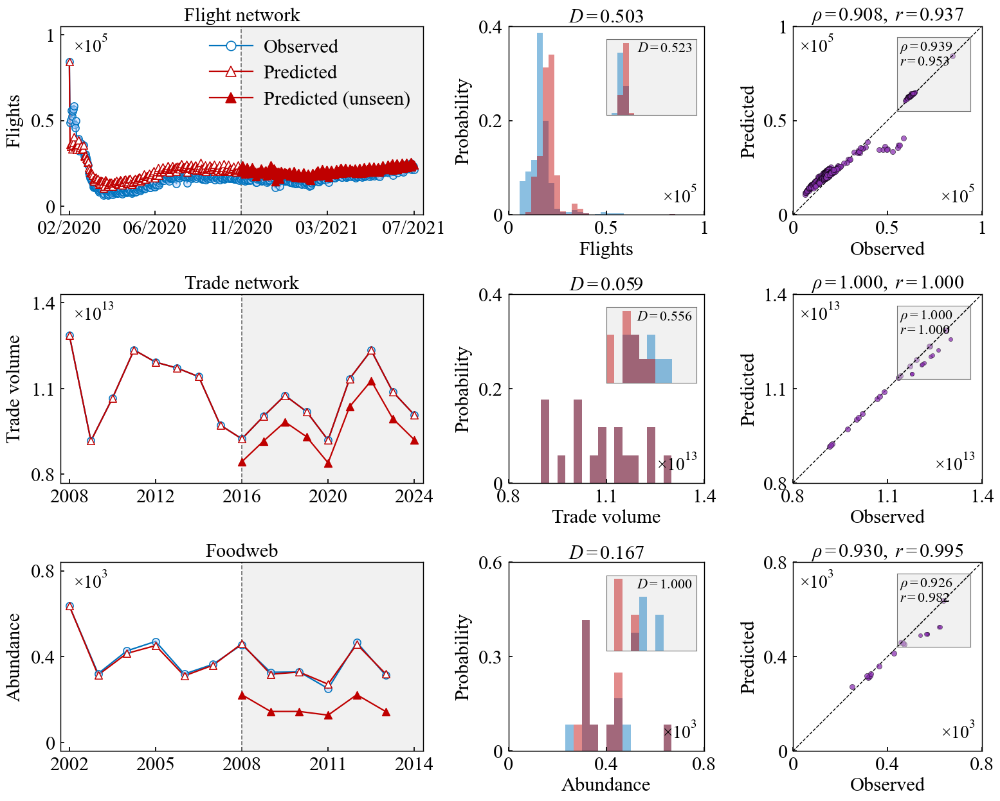

In [ ]:
## Figure 4 
"""
Figure 4: three real-world systems with a chronological 50/50 test.

Each row:
    left  : observed vs predicted time series
            - Observed and original Predicted are shown over ALL dates
            - gray shading marks the held-out last 50%
            - Predicted (unseen) is an ADDITIONAL curve shown only in
              the last 50%, generated without using that half's own R_p
            - open red triangles = original Predicted
            - filled red triangles = Predicted (unseen)
    middle: probability distributions using ALL dates
            + inset showing ONLY the last 50%
            + inset has no tick labels / scientific multiplier; only D
    right : observed vs predicted scatter using ALL dates
            + all main-panel points use the same scatter style
            + inset showing ONLY the last 50%
            + inset has no tick labels / scientific multiplier; only rho,r
            + inset uses the same y=x reference-line style as the main panel

For the last 50%:
    - ALL perturbation levels are treated as unseen test levels;
    - even if a test p numerically coincides with a perturbation level in
      the first 50%, the response matrix at that identical level is excluded;
    - if p lies inside the remaining training p range, linearly interpolate
      between the two neighboring seen response matrices;
    - if p lies outside the remaining training p range, linear extrapolation
      is used by default so that all test dates can still be predicted.

IMPORTANT:
    Test-period R_p_slice files are NEVER used to predict the last 50%.
    Only R_p_slice files associated with the first 50% are allowed.

CACHE:
    Expensive products X0 @ R_p.T are cached in
        F:\\NP-real\\response_matrix_rank_cache
    so repeated runs are much faster. The cache stores projection vectors,
    not full response matrices.
"""

from __future__ import annotations

import re
import warnings
import hashlib
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.io import loadmat
from scipy.stats import spearmanr, pearsonr, ks_2samp
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter


# ============================================================
# 1. PATHS
# ============================================================

ROOT_CODING = Path(r"F:\NP-real\1Coding")

FLIGHT_WORK_DIR = ROOT_CODING / "3Flight network"
TRADE_WORK_DIR = ROOT_CODING / "4Trade network"
FISH_WORK_DIR = ROOT_CODING / "5foodweb"

FLIGHT_DATA_DIR = Path(r"F:\NP-real\0Data\9.Passenger_flight")
TRADE_DATA_DIR = Path(r"F:\NP-real\0Data\10.Economy_trade")
FISH_DATA_DIR = Path(r"F:\NP-real\0Data\11.Ecosystem_fish")

OUTPUT_SVG = Path.cwd() / "Figure 4.svg"

CACHE_DIR = Path(r"F:\NP-real\response_matrix_rank_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. 50 / 50 SETTINGS
# ============================================================

TRAIN_FRACTION = 0.50
MATCH_TOL = 1e-10

# For a test p outside the first-50% p range:
#   "linear_extrapolate" -> use the two nearest training p levels
#   "nearest"            -> use the nearest training R only
#   "nan"                -> do not predict that test point
OUTSIDE_MODE = "linear_extrapolate"


# ============================================================
# 3. FONT / GLOBAL STYLE
# ============================================================

TICK_FS = 22
AXIS_LABEL_FS = 22
LEGEND_FS = 22
STAT_FS = 22
TITLE_FS = 22

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "axes.linewidth": 1.10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "savefig.transparent": True,
    "svg.fonttype": "none",
})


# ============================================================
# 4. COLORS / MARKERS
# ============================================================

BLUE = (0.00, 0.45, 0.74)
RED = (0.75, 0.00, 0.00)
PURPLE = (0.55, 0.20, 0.70)

BLUE_LIGHT_RGBA = (0.70, 0.82, 1.00, 0.48)
RED_LIGHT_RGBA = (1.00, 0.78, 0.78, 0.48)

TEST_SHADE = "0.88"
TEST_SHADE_ALPHA = 0.45
SPLIT_LINE_COLOR = "0.42"
SPLIT_LINEWIDTH = 1.20
SPLIT_LINESTYLE = "--"

TIME_LINEWIDTH = 1.62
MARKER_SIZE = 8.1
MARKER_EDGEWIDTH = 1.10

SCATTER_SIZE = 34
SCATTER_ALPHA = 0.75
HIST_ALPHA = 0.45
IDENTITY_LINEWIDTH = 1.0

# ============================================================
# INSET STATISTICS STYLE
# ============================================================
# Larger font for the statistics associated with inset panels.
INSET_STAT_FS = 16

# Small horizontal gap between the statistic text and the inset frame.
INSET_STAT_GAP = 0.012


# ============================================================
# 5. FIGURE GEOMETRY
# ============================================================

FIG_W = 15.8
FIG_H = 12.2

LEFT = 0.075
RIGHT = 0.985
BOTTOM = 0.060
TOP = 0.985

ROW_HSPACE = 0.42
COL_WSPACE = 0.34
WIDTH_RATIOS = [1.85, 1.00, 1.00]

INTERNAL_MARGIN_RATIO = 0.05
TIME_MARGIN_RATIO = 0.025


# ============================================================
# 6. COMMON AXIS STYLE
# ============================================================

def style_axis(ax, tick_fs=TICK_FS):
    ax.grid(False)
    ax.minorticks_off()

    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=4.5,
        width=1.25,
        labelsize=tick_fs,
        pad=6.0,
    )

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontname("Times New Roman")
        label.set_fontsize(tick_fs)

    for spine in ax.spines.values():
        spine.set_linewidth(1.05)


def clean_number(x, pos=None):
    if abs(x - round(x)) < 1e-10:
        return f"{int(round(x))}"
    return f"{x:g}"


CLEAN_FORMATTER = FuncFormatter(clean_number)


def padded_limits_from_ticks(ticks, ratio=INTERNAL_MARGIN_RATIO):
    ticks = np.asarray(ticks, dtype=float)
    lo = float(np.min(ticks))
    hi = float(np.max(ticks))
    span = hi - lo

    if span <= 0:
        span = max(abs(lo), 1.0)

    pad = ratio * span
    return lo - pad, hi + pad


def add_time_margin(ax, left, right, ratio=TIME_MARGIN_RATIO):
    if isinstance(left, (pd.Timestamp, np.datetime64)) or hasattr(left, "to_pydatetime"):
        left = pd.Timestamp(left)
        right = pd.Timestamp(right)
        span = right - left
        pad = span * ratio
        ax.set_xlim(left - pad, right + pad)
    else:
        left = float(left)
        right = float(right)
        span = right - left
        pad = ratio * span if span > 0 else 1.0
        ax.set_xlim(left - pad, right + pad)


# ============================================================
# 7. MAT FILE HELPERS
# ============================================================

def is_mat_v73(path: Path) -> bool:
    try:
        return h5py.is_hdf5(path)
    except Exception:
        return False


def _decode_hdf5_numeric_dataset(dataset):
    arr = np.asarray(dataset)

    if arr.dtype.fields is not None:
        names = arr.dtype.fields.keys()
        if "real" in names and "imag" in names:
            arr = arr["real"] + 1j * arr["imag"]

    # MATLAB v7.3 stores array dimensions in reverse order.
    if arr.ndim >= 2:
        arr = np.transpose(
            arr,
            axes=tuple(range(arr.ndim - 1, -1, -1)),
        )

    return np.asarray(arr)


def load_mat_variable(path: Path, variable: str):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"File not found:\n{path}")

    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            if variable not in f:
                raise KeyError(
                    f"Variable '{variable}' not found in:\n{path}\n"
                    f"Available variables: {list(f.keys())}"
                )

            obj = f[variable]
            if not isinstance(obj, h5py.Dataset):
                raise TypeError(
                    f"'{variable}' in {path} is not a numeric HDF5 dataset."
                )

            return _decode_hdf5_numeric_dataset(obj)

    data = loadmat(path)

    if variable not in data:
        available = [k for k in data if not k.startswith("__")]
        raise KeyError(
            f"Variable '{variable}' not found in:\n{path}\n"
            f"Available variables: {available}"
        )

    return np.asarray(data[variable])


def squeeze_to_2d(X, label):
    X = np.asarray(X).squeeze()

    if X.ndim == 1:
        X = X[:, None]

    if X.ndim != 2:
        raise ValueError(
            f"{label} must become a 2D snapshot x node array after squeeze; "
            f"got shape {X.shape}"
        )

    return np.asarray(np.real_if_close(X), dtype=float)


def orient_snapshots_by_expected(X, expected_snapshots, label):
    X = squeeze_to_2d(X, label)

    if X.shape[0] == expected_snapshots:
        return X

    if X.shape[1] == expected_snapshots:
        return X.T

    raise ValueError(
        f"{label}: neither dimension matches the number of ratios/dates "
        f"({expected_snapshots}). Shape is {X.shape}."
    )


def load_ratio_vector(work_dir: Path):
    ratios = np.asarray(
        load_mat_variable(work_dir / "ratios.mat", "ratios"),
        dtype=float,
    ).squeeze().reshape(-1)

    if not np.all(np.isfinite(ratios)):
        raise ValueError(f"ratios.mat contains NaN/Inf:\n{work_dir}")

    return ratios


# ============================================================
# 8. RESPONSE-SLICE HELPERS
# ============================================================

def find_slice_dir(work_dir: Path):
    direct = work_dir / "R_p_slices"
    if direct.exists():
        return direct

    candidates = [
        p for p in work_dir.rglob("R_p_slices")
        if p.is_dir()
    ]

    if not candidates:
        raise FileNotFoundError(
            f"R_p_slices folder not found under:\n{work_dir}"
        )

    return candidates[0]


def build_slice_map(slice_dir: Path):
    """
    Return:
        {slice_number: file_path}

    Example:
        R_p_slice_002.mat -> key 2

    Mapping to ratios:
        ratios[1] <-> R_p_slice_002.mat
        ratios[2] <-> R_p_slice_003.mat
        ...
    """
    result = {}

    for path in sorted(slice_dir.glob("R_p_slice_*.mat")):
        m = re.search(r"R_p_slice_(\d+)\.mat$", path.name, flags=re.I)
        if m:
            result[int(m.group(1))] = path

    if not result:
        raise FileNotFoundError(
            f"No R_p_slice_*.mat files found in:\n{slice_dir}"
        )

    return result


def load_response_matrix(path: Path):
    R = np.asarray(
        load_mat_variable(path, "R_p_slice"),
        dtype=float,
    ).squeeze()

    if R.ndim != 2 or R.shape[0] != R.shape[1]:
        raise ValueError(
            f"R_p_slice must be square; got {R.shape} in:\n{path}"
        )

    return R


def ratio_index_to_slice_number(ratio_index_zero_based):
    """
    MATLAB mapping:
        ratio index 0 = baseline, no R slice
        ratio index 1 -> R_p_slice_002
        ratio index 2 -> R_p_slice_003
    """
    return ratio_index_zero_based + 1



# ============================================================
# 9. DISK CACHE FOR X0 @ R_p.T
# ============================================================

def _safe_cache_name(name: str) -> str:
    return re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_")


def _x0_fingerprint(x0) -> str:
    arr = np.ascontiguousarray(np.asarray(x0, dtype=np.float64).reshape(-1))
    return hashlib.sha1(arr.tobytes()).hexdigest()[:20]


def _projection_cache_path(network_name: str, slice_no: int) -> Path:
    safe = _safe_cache_name(network_name)
    return CACHE_DIR / f"Figure4_{safe}_Rslice_{slice_no:04d}_X0_projection.npz"


def load_or_compute_projection(network_name, entry, X0):
    """
    Return X0 @ R_p.T for one training response slice.

    A compact .npz cache is used.  Cache validity is checked against:
      - response-slice file size
      - response-slice modification time
      - baseline-state fingerprint
      - number of nodes

    Therefore an old cache is automatically ignored when the underlying
    R_p slice or baseline state has changed.
    """
    slice_no = int(entry["slice_no"])
    r_path = Path(entry["path"])
    cache_path = _projection_cache_path(network_name, slice_no)

    stat = r_path.stat()
    x0_hash = _x0_fingerprint(X0)
    n_nodes = int(np.asarray(X0).size)

    if cache_path.exists():
        try:
            with np.load(cache_path, allow_pickle=False) as z:
                valid = (
                    int(z["r_size"]) == int(stat.st_size)
                    and int(z["r_mtime_ns"]) == int(stat.st_mtime_ns)
                    and str(z["x0_sha1"].item()) == x0_hash
                    and int(z["n_nodes"]) == n_nodes
                )
                if valid:
                    state = np.asarray(z["state"], dtype=float).reshape(-1)
                    if state.size == n_nodes:
                        return state, True
        except Exception:
            # Corrupt/incompatible cache -> simply recompute.
            pass

    R = load_response_matrix(r_path)

    if R.shape[0] != n_nodes:
        raise ValueError(
            f"{network_name}: R_p_slice_{slice_no:03d} has shape {R.shape}, "
            f"but baseline has {n_nodes} nodes."
        )

    state = np.asarray(np.asarray(X0, dtype=float) @ R.T, dtype=float).reshape(-1)

    np.savez_compressed(
        cache_path,
        state=state,
        r_size=np.int64(stat.st_size),
        r_mtime_ns=np.int64(stat.st_mtime_ns),
        x0_sha1=np.asarray(x0_hash),
        n_nodes=np.int64(n_nodes),
    )

    return state, False


# ============================================================
# 10. DATE / YEAR READERS
# ============================================================

def read_flight_dates(data_dir: Path):
    files = sorted(data_dir.rglob("flight_*.csv"))

    dates = []
    for path in files:
        match = re.search(
            r"^flight_(\d{4}-\d{2}-\d{2})\.csv$",
            path.name,
            flags=re.IGNORECASE,
        )
        if match:
            dates.append(
                pd.to_datetime(match.group(1), format="%Y-%m-%d")
            )

    if not dates:
        raise FileNotFoundError(
            f"No valid flight_yyyy-MM-dd.csv files found under:\n{data_dir}"
        )

    return pd.DatetimeIndex(sorted(dates))


def read_trade_years(data_dir: Path, target_length=None):
    files = sorted(data_dir.glob("trade_*TOTAL_new.csv"))

    years = []
    for path in files:
        match = re.search(r"(\d{4})", path.name)
        if match:
            years.append(int(match.group(1)))

    years = sorted(set(years))

    # Preserve the original MATLAB workflow.
    if years and min(years) >= 2009:
        years = [2008] + years

    if target_length is not None:
        if len(years) == 0:
            years = list(range(2008, 2008 + target_length))
        elif len(years) < target_length:
            last = years[-1]
            years += list(
                range(last + 1, last + 1 + (target_length - len(years)))
            )

    return np.asarray(years, dtype=int)


def read_fish_dates(data_dir: Path):
    state_file = data_dir / "network state.csv"

    if not state_file.exists():
        raise FileNotFoundError(
            f"Foodweb network state file not found:\n{state_file}"
        )

    table = pd.read_csv(state_file)

    if "Date" not in table.columns:
        raise KeyError(
            f"Column 'Date' not found in:\n{state_file}"
        )

    return pd.DatetimeIndex(
        pd.to_datetime(table["Date"], format="%Y/%m/%d")
    )


# ============================================================
# 10. PREDICTION FROM FIRST 50% ONLY
# ============================================================

def prepare_training_support(ratios, n_train, slice_map):
    """
    Create training support points from ratio indices 1 ... n_train-1.
    Only slice files from the chronological first 50% are allowed.
    """
    entries = []

    for idx in range(1, n_train):
        slice_no = ratio_index_to_slice_number(idx)

        if slice_no not in slice_map:
            warnings.warn(
                f"Missing training response slice for ratio index {idx}: "
                f"expected R_p_slice_{slice_no:03d}.mat"
            )
            continue

        entries.append({
            "idx": idx,
            "p": float(ratios[idx]),
            "slice_no": slice_no,
            "path": slice_map[slice_no],
        })

    if len(entries) < 2:
        raise ValueError(
            "Fewer than two usable response matrices are available "
            "in the first 50%; interpolation is impossible."
        )

    return entries


def select_unseen_support(p_test, training_entries, tol=MATCH_TOL):
    """
    Select response support using ONLY first-50% entries while treating
    EVERY perturbation level in the latter 50% as unseen.

    Crucially, if p_test numerically coincides with a perturbation level
    present in the first 50%, all training entries at that identical p are
    excluded before constructing the estimate. Therefore, no test point
    directly reuses the response matrix at its own perturbation level.

    Returns:
        mode, entry_a, entry_b, weight

    interpolation/extrapolation:
        prediction = (1-w)*entry_a + w*entry_b

    nearest:
        prediction = entry_a
    """
    p_test = float(p_test)

    # ----- sort by p and collapse duplicate training p values -----
    sorted_entries = sorted(training_entries, key=lambda e: e["p"])

    unique_entries = []
    for e in sorted_entries:
        if (
            not unique_entries
            or abs(e["p"] - unique_entries[-1]["p"]) > tol
        ):
            unique_entries.append(e)

    # ----- strict unseen rule -----
    # Remove the response matrix at the identical perturbation level,
    # if that level appeared in the first 50%.  The test point is still
    # treated as unseen and must be inferred from OTHER seen levels.
    support_entries = [
        e for e in unique_entries
        if abs(e["p"] - p_test) > tol
    ]

    if len(support_entries) < 2:
        raise ValueError(
            "Fewer than two distinct seen perturbation levels remain after "
            "excluding the test perturbation level; interpolation/extrapolation "
            "is impossible."
        )

    p_values = np.asarray(
        [e["p"] for e in support_entries],
        dtype=float,
    )

    # ----- inside remaining seen range: interpolation -----
    if p_values[0] < p_test < p_values[-1]:
        upper = int(np.searchsorted(p_values, p_test, side="right"))
        lower = upper - 1

        a = support_entries[lower]
        b = support_entries[upper]

        denom = b["p"] - a["p"]
        if abs(denom) <= tol:
            raise ValueError(
                "Neighboring seen perturbation levels are numerically identical."
            )

        w = (p_test - a["p"]) / denom
        return "interpolation", a, b, float(w)

    # ----- outside remaining seen range -----
    if OUTSIDE_MODE == "nan":
        return "outside_nan", None, None, np.nan

    if OUTSIDE_MODE == "nearest":
        if p_test <= p_values[0]:
            return "nearest", support_entries[0], None, 0.0
        return "nearest", support_entries[-1], None, 0.0

    if OUTSIDE_MODE == "linear_extrapolate":
        if p_test <= p_values[0]:
            a = support_entries[0]
            b = support_entries[1]
        else:
            a = support_entries[-2]
            b = support_entries[-1]

        denom = b["p"] - a["p"]
        if abs(denom) <= tol:
            return "nearest", a, None, 0.0

        w = (p_test - a["p"]) / denom
        return "extrapolation", a, b, float(w)

    raise ValueError(
        "OUTSIDE_MODE must be 'linear_extrapolate', 'nearest', or 'nan'."
    )


def build_out_of_sample_prediction(
    network_name,
    work_dir,
    X_obs_raw,
    X_pred_original,
    ratios,
    baseline_transform=None,
):
    """
    First 50%:
        keep the already-computed direct predictions from X_p.mat.

    Last 50%:
        treat EVERY perturbation level as unseen;
        do NOT use their own R_p_slice files;
        do NOT directly reuse a first-50% R_p at an identical p;
        predict only from OTHER response matrices associated with the first 50%.

    For interpolation/extrapolation,
        R_hat = (1-w) R_a + w R_b
    and therefore
        X0 R_hat^T = (1-w) X0 R_a^T + w X0 R_b^T.

    We cache the expensive projection vectors X0 R_p^T on disk.  This is
    mathematically identical to interpolating the matrices first, while
    avoiding repeated loading/multiplication of very large R_p matrices.
    """
    n_total = len(ratios)

    X_obs_raw = orient_snapshots_by_expected(
        X_obs_raw,
        n_total,
        f"{network_name} X_obs",
    )

    X_pred_original = orient_snapshots_by_expected(
        X_pred_original,
        n_total,
        f"{network_name} X_p",
    )

    n_train = int(np.floor(TRAIN_FRACTION * n_total))
    n_test = n_total - n_train

    X0 = np.asarray(X_obs_raw[0, :], dtype=float)

    if baseline_transform is not None:
        if X0.size != baseline_transform.shape[0]:
            raise ValueError(
                f"{network_name}: baseline state has {X0.size} nodes, "
                f"but T is {baseline_transform.shape}."
            )
        X0 = X0 @ baseline_transform

    # First 50% keeps the original direct prediction.
    X_pred_new = np.array(X_pred_original, dtype=float, copy=True)

    slice_dir = find_slice_dir(work_dir)
    slice_map = build_slice_map(slice_dir)

    training_entries = prepare_training_support(
        ratios,
        n_train,
        slice_map,
    )

    memory_cache = {}
    cache_hits = 0
    cache_misses = 0

    def predicted_state_from_entry(entry):
        nonlocal cache_hits, cache_misses

        key = int(entry["slice_no"])

        if key in memory_cache:
            return memory_cache[key]

        state, hit = load_or_compute_projection(
            network_name,
            entry,
            X0,
        )

        if hit:
            cache_hits += 1
        else:
            cache_misses += 1

        memory_cache[key] = state
        return state

    counts = {
        "interpolation": 0,
        "extrapolation": 0,
        "nearest": 0,
        "outside_nan": 0,
    }

    test_mask = np.zeros(n_total, dtype=bool)
    test_mask[n_train:] = True

    # By design, EVERY point in the latter 50% is treated as unseen.
    unseen_mask = test_mask.copy()

    for idx in range(n_train, n_total):
        p_test = ratios[idx]

        mode, a, b, w = select_unseen_support(
            p_test,
            training_entries,
            tol=MATCH_TOL,
        )

        counts[mode] += 1

        if mode == "outside_nan":
            X_pred_new[idx, :] = np.nan
            continue

        state_a = predicted_state_from_entry(a)

        if b is None:
            state_pred = state_a
        else:
            state_b = predicted_state_from_entry(b)
            state_pred = (1.0 - w) * state_a + w * state_b

        X_pred_new[idx, :] = state_pred

    print("\n" + "=" * 66)
    print(network_name)
    print("=" * 66)
    print(f"Total dates                    : {n_total}")
    print(f"First 50%                      : {n_train}")
    print(f"Last 50%                       : {n_test}")
    print(f"Last 50% treated as unseen     : {n_test}")
    print(f"Unseen p (interpolated)        : {counts['interpolation']}")
    print(f"Unseen p (extrapolated)        : {counts['extrapolation']}")
    print(f"Unseen p (nearest R)           : {counts['nearest']}")
    print(f"Unseen p not predicted         : {counts['outside_nan']}")
    print(f"Projection cache hits          : {cache_hits}")
    print(f"Projection cache new/recomputed: {cache_misses}")
    print("Test-period R_p slices used    : 0")
    print(f"Cache folder                   : {CACHE_DIR}")

    return (
        X_obs_raw,
        X_pred_original,
        X_pred_new,
        n_train,
        counts,
        test_mask,
        unseen_mask,
    )


# ============================================================
# 11. STATISTICS
# ============================================================

def compute_statistics(y_obs, y_pred):
    y_obs = np.asarray(y_obs, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    idx = (
        np.isfinite(y_obs)
        & np.isfinite(y_pred)
        & (y_obs > 0)
        & (y_pred > 0)
    )

    x = y_obs[idx]
    y = y_pred[idx]

    if x.size < 2:
        raise ValueError("Too few positive finite pairs for statistics.")

    rho = float(spearmanr(x, y).statistic)
    r = float(pearsonr(x, y).statistic)
    D = float(ks_2samp(x, y, method="auto").statistic)

    return x, y, D, rho, r


# ============================================================
# 12. LOAD + PREDICT FLIGHT NETWORK
# ============================================================

flight_ratios = load_ratio_vector(FLIGHT_WORK_DIR)
n_flight_expected = len(flight_ratios)

flight_dates = read_flight_dates(FLIGHT_DATA_DIR)
if len(flight_dates) != n_flight_expected:
    raise ValueError(
        f"Flight: {len(flight_dates)} dates but "
        f"{n_flight_expected} ratios."
    )

flight_X_obs = load_mat_variable(
    FLIGHT_WORK_DIR / "X_obs.mat",
    "X_obs",
)
flight_X_p_old = load_mat_variable(
    FLIGHT_WORK_DIR / "X_p.mat",
    "X_p",
)

flight_T = np.asarray(
    load_mat_variable(
        FLIGHT_WORK_DIR / "T.mat",
        "T",
    ),
    dtype=float,
).squeeze()

if flight_T.ndim != 2 or flight_T.shape[0] != flight_T.shape[1]:
    raise ValueError(f"Flight T must be square; got {flight_T.shape}.")

A_flight, B_flight_original, B_flight_unseen, flight_split, _, flight_test_mask, flight_unseen_mask = build_out_of_sample_prediction(
    "Flight network",
    FLIGHT_WORK_DIR,
    flight_X_obs,
    flight_X_p_old,
    flight_ratios,
    baseline_transform=flight_T,
)

flight_obs = np.sum(A_flight, axis=1)

# Original full-period prediction from the existing X_p.mat.
flight_pred = np.sum(B_flight_original, axis=1)

# New held-out prediction: ALL points in the last 50% are treated as
# unseen and generated only from other first-50% response support.
flight_pred_unseen = np.sum(B_flight_unseen, axis=1)


# ============================================================
# 13. LOAD + PREDICT TRADE NETWORK
# ============================================================

trade_ratios = load_ratio_vector(TRADE_WORK_DIR)
n_trade_expected = len(trade_ratios)

trade_X_obs = load_mat_variable(
    TRADE_WORK_DIR / "X_obs.mat",
    "X_obs",
)
trade_X_p_old = load_mat_variable(
    TRADE_WORK_DIR / "X_p.mat",
    "X_p",
)

A_trade, B_trade_original, B_trade_unseen, trade_split, _, trade_test_mask, trade_unseen_mask = build_out_of_sample_prediction(
    "Trade network",
    TRADE_WORK_DIR,
    trade_X_obs,
    trade_X_p_old,
    trade_ratios,
    baseline_transform=None,
)

trade_obs = np.sum(A_trade, axis=1)

# Original full-period prediction.
trade_pred = np.sum(B_trade_original, axis=1)

# New held-out prediction: all last-50% points are treated as unseen.
trade_pred_unseen = np.sum(B_trade_unseen, axis=1)

trade_years = read_trade_years(
    TRADE_DATA_DIR,
    target_length=n_trade_expected,
)

if len(trade_years) != n_trade_expected:
    raise ValueError(
        f"Trade: {len(trade_years)} years but "
        f"{n_trade_expected} ratios."
    )


# ============================================================
# 14. LOAD + PREDICT FOODWEB
# ============================================================

fish_ratios = load_ratio_vector(FISH_WORK_DIR)
n_fish_expected = len(fish_ratios)

fish_dates = read_fish_dates(FISH_DATA_DIR)
if len(fish_dates) != n_fish_expected:
    raise ValueError(
        f"Foodweb: {len(fish_dates)} dates but "
        f"{n_fish_expected} ratios."
    )

fish_X_obs = load_mat_variable(
    FISH_WORK_DIR / "X_obs.mat",
    "X_obs",
)
fish_X_p_old = load_mat_variable(
    FISH_WORK_DIR / "X_p.mat",
    "X_p",
)

A_fish, B_fish_original, B_fish_unseen, fish_split, _, fish_test_mask, fish_unseen_mask = build_out_of_sample_prediction(
    "Foodweb",
    FISH_WORK_DIR,
    fish_X_obs,
    fish_X_p_old,
    fish_ratios,
    baseline_transform=None,
)

# Foodweb x coordinate uses integer years exactly:
# 2002/06/10 -> 2002, not 2002.44...
fish_years = fish_dates.year.to_numpy(dtype=float)

# CUMULATIVE abundance, not mean abundance.
fish_obs = np.sum(A_fish, axis=1)

# Original full-period prediction.
fish_pred = np.sum(B_fish_original, axis=1)

# New held-out prediction: all last-50% points are treated as unseen.
fish_pred_unseen = np.sum(B_fish_unseen, axis=1)


# ============================================================
# 15. SYSTEM SETTINGS
# ============================================================

FISH_AXIS_MAX = 800.0
FISH_TICKS = [0.0, 400.0, 800.0]

SYSTEMS = [
    {
        "name": "Flight network",
        "time": flight_dates,
        "obs": flight_obs,
        "pred": flight_pred,
        "pred_unseen": flight_pred_unseen,
        "test_start": flight_split,
        "test_mask": flight_test_mask,
        "unseen_mask": flight_unseen_mask,
        "time_kind": "datetime",
        "top_ylabel": "Flights",
        "bottom_xlabel": "Flights",
        "time_yticks": [0.0, 5.0e4, 1.0e5],
        "hist_yticks": [0.0, 0.2, 0.4],
        "scatter_ticks": [0.0, 5.0e4, 1.0e5],
        "hist_bins": 35,
        "n_time_ticks": 5,
        "date_format": "%m/%Y",
        "scientific_power": 5,
    },
    {
        "name": "Trade network",
        "time": trade_years,
        "obs": trade_obs,
        "pred": trade_pred,
        "pred_unseen": trade_pred_unseen,
        "test_start": trade_split,
        "test_mask": trade_test_mask,
        "unseen_mask": trade_unseen_mask,
        "time_kind": "year",
        "top_ylabel": "Trade volume",
        "bottom_xlabel": "Trade volume",
        "time_yticks": [0.8e13, 1.1e13, 1.4e13],
        "hist_yticks": [0.0, 0.2, 0.4],
        "scatter_ticks": [0.8e13, 1.1e13, 1.4e13],
        "hist_bins": 25,
        "n_time_ticks": 5,
        "date_format": None,
        "scientific_power": 13,
    },
    {
        "name": "Foodweb",
        "time": fish_years,
        "obs": fish_obs,
        "pred": fish_pred,
        "pred_unseen": fish_pred_unseen,
        "test_start": fish_split,
        "test_mask": fish_test_mask,
        "unseen_mask": fish_unseen_mask,
        "time_kind": "year",
        "top_ylabel": "Abundance",
        "bottom_xlabel": "Abundance",
        "time_yticks": FISH_TICKS,
        "hist_yticks": [0.0, 0.3, 0.6],
        "scatter_ticks": FISH_TICKS,
        "hist_bins": 25,
        "n_time_ticks": 5,
        "date_format": "%Y",
        "scientific_power": 3,
    },
]


# ============================================================
# 16. FIGURE / 3 x 3 GRID
# ============================================================

fig = plt.figure(
    figsize=(FIG_W, FIG_H),
    facecolor="none",
)
fig.patch.set_alpha(0.0)

grid = fig.add_gridspec(
    nrows=3,
    ncols=3,
    left=LEFT,
    right=RIGHT,
    bottom=BOTTOM,
    top=TOP,
    hspace=ROW_HSPACE,
    wspace=COL_WSPACE,
    width_ratios=WIDTH_RATIOS,
)

TIME_AXES = []
HIST_AXES = []
SCATTER_AXES = []

for row in range(3):
    TIME_AXES.append(fig.add_subplot(grid[row, 0]))
    HIST_AXES.append(fig.add_subplot(grid[row, 1]))
    SCATTER_AXES.append(fig.add_subplot(grid[row, 2]))


# ============================================================
# 17. PLOTTING HELPERS
# ============================================================

def set_even_datetime_ticks(ax, dates, n_ticks, fmt):
    dates = pd.DatetimeIndex(dates)

    idx = np.unique(
        np.round(
            np.linspace(0, len(dates) - 1, n_ticks)
        ).astype(int)
    )

    ax.set_xticks(dates[idx])
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))


def set_even_year_ticks(ax, years, n_ticks):
    years = np.asarray(years, dtype=int)

    idx = np.unique(
        np.round(
            np.linspace(0, years.size - 1, n_ticks)
        ).astype(int)
    )

    ax.set_xticks(years[idx])


def use_inside_scientific(
    ax,
    axis="y",
    power=4,
    position="upper left",
):
    scale = 10.0 ** power

    formatter = FuncFormatter(
        lambda value, pos: clean_number(value / scale)
    )

    if axis == "x":
        ax.xaxis.set_major_formatter(formatter)
    elif axis == "y":
        ax.yaxis.set_major_formatter(formatter)
    else:
        raise ValueError("axis must be 'x' or 'y'")

    positions = {
        # Unified mirrored scientific-notation placement:
        # y-axis multiplier -> upper left
        # x-axis multiplier -> lower right
        #
        # The two positions use equal visual margins from the
        # corresponding axes borders.
        "upper left":  (0.035, 0.955, "left",  "top"),
        "upper right": (0.965, 0.955, "right", "top"),
        "lower left":  (0.035, 0.045, "left",  "bottom"),
        "lower right": (0.965, 0.045, "right", "bottom"),
    }

    x_text, y_text, ha, va = positions[position]

    ax.text(
        x_text,
        y_text,
        rf"$\times 10^{{{power}}}$",
        transform=ax.transAxes,
        ha=ha,
        va=va,
        fontsize=TICK_FS - 2,
        fontname="Times New Roman",
        zorder=20,
    )


def split_boundary(time, test_start, time_kind):
    """
    Put the divider exactly at the FIRST actual point of the held-out
    second half, rather than halfway between the last training point
    and the first test point.

    Examples:
        Trade   -> divider can align exactly with 2016
        Foodweb -> divider can align exactly with 2008
        Flight  -> divider aligns with the first held-out calendar date
    """
    if test_start <= 0 or test_start >= len(time):
        raise ValueError("Invalid 50/50 split index.")

    if time_kind == "datetime":
        return pd.Timestamp(time[test_start])

    return float(time[test_start])


def shade_test_period(ax, system):
    boundary = split_boundary(
        system["time"],
        system["test_start"],
        system["time_kind"],
    )

    # At this point x limits have already been set.
    x_right = ax.get_xlim()[1]

    if system["time_kind"] == "datetime":
        boundary_plot = mdates.date2num(pd.Timestamp(boundary))
    else:
        boundary_plot = float(boundary)

    ax.axvspan(
        boundary_plot,
        x_right,
        facecolor=TEST_SHADE,
        alpha=TEST_SHADE_ALPHA,
        edgecolor="none",
        zorder=0,
    )

    ax.axvline(
        boundary_plot,
        color=SPLIT_LINE_COLOR,
        linestyle=SPLIT_LINESTYLE,
        linewidth=SPLIT_LINEWIDTH,
        zorder=2,
    )


def _as_plot_time(time):
    if isinstance(time, pd.DatetimeIndex):
        return np.asarray(time.to_pydatetime(), dtype=object)
    return np.asarray(time)


def draw_time_series(ax, system, show_legend=False):
    time = system["time"]
    obs = np.asarray(system["obs"], dtype=float)

    # Original Predicted curve: keep it for the COMPLETE period.
    pred = np.asarray(system["pred"], dtype=float)

    # Additional held-out prediction generated using only first-50%
    # response support.  It is displayed ONLY in the last 50%.
    pred_unseen = np.asarray(system["pred_unseen"], dtype=float)

    test_start = int(system["test_start"])

    # Set x limits before shading.
    if system["time_kind"] == "datetime":
        add_time_margin(ax, time[0], time[-1])
        set_even_datetime_ticks(
            ax,
            time,
            system["n_time_ticks"],
            system["date_format"],
        )
    else:
        if system["name"] == "Foodweb":
            ax.set_xlim(2001.7, 2014.3)
            ax.set_xticks([2002, 2005, 2008, 2011, 2014])
            ax.xaxis.set_major_formatter(CLEAN_FORMATTER)
        else:
            add_time_margin(ax, time[0], time[-1])
            set_even_year_ticks(ax, time, system["n_time_ticks"])

    # Last 50% = gray held-out region.
    shade_test_period(ax, system)

    # --------------------------------------------------------
    # Observed: original full blue curve.
    # --------------------------------------------------------
    ax.plot(
        time,
        obs,
        color=BLUE,
        linewidth=TIME_LINEWIDTH,
        zorder=3,
    )

    ax.scatter(
        time,
        obs,
        s=MARKER_SIZE ** 2,
        marker="o",
        facecolors=[BLUE_LIGHT_RGBA],
        edgecolors=[BLUE],
        linewidths=MARKER_EDGEWIDTH,
        zorder=5,
    )

    # --------------------------------------------------------
    # Predicted: original full red curve.
    # Nothing is removed or split.
    # --------------------------------------------------------
    finite_pred = np.isfinite(pred)

    ax.plot(
        time,
        pred,
        color=RED,
        linewidth=TIME_LINEWIDTH,
        zorder=4,
    )

    tplot = _as_plot_time(time)

    ax.scatter(
        tplot[finite_pred],
        pred[finite_pred],
        s=(MARKER_SIZE * 1.02) ** 2,
        marker="^",
        facecolors="white",
        edgecolors=[RED],
        linewidths=MARKER_EDGEWIDTH,
        zorder=6,
    )

    # --------------------------------------------------------
    # Predicted (unseen): ADD one extra curve in the LAST 50%.
    #
    # This is the prediction generated without using the held-out
    # half's own R_p slices.  It is not a replacement for Predicted.
    # --------------------------------------------------------
    extra_mask = np.zeros(len(pred_unseen), dtype=bool)
    extra_mask[test_start:] = np.isfinite(pred_unseen[test_start:])

    extra_line = np.full(len(pred_unseen), np.nan, dtype=float)
    extra_line[extra_mask] = pred_unseen[extra_mask]

    ax.plot(
        time,
        extra_line,
        color=RED,
        linewidth=TIME_LINEWIDTH,
        zorder=7,
    )

    ax.scatter(
        tplot[extra_mask],
        pred_unseen[extra_mask],
        s=(MARKER_SIZE * 1.05) ** 2,
        marker="^",
        facecolors=[RED],
        edgecolors=[RED],
        linewidths=MARKER_EDGEWIDTH,
        zorder=8,
    )

    ax.set_ylabel(
        system["top_ylabel"],
        fontsize=AXIS_LABEL_FS,
        labelpad=8.0,
        fontname="Times New Roman",
    )

    ax.set_ylim(
        padded_limits_from_ticks(
            system["time_yticks"]
        )
    )
    ax.set_yticks(
        system["time_yticks"]
    )

    ax.set_title(
        system["name"],
        fontsize=TITLE_FS,
        pad=6.0,
        fontname="Times New Roman",
        fontweight="normal",
    )

    style_axis(ax)

    if show_legend:
        handles = [
            Line2D(
                [0], [0],
                color=BLUE,
                linestyle="-",
                linewidth=TIME_LINEWIDTH,
                marker="o",
                markerfacecolor="white",
                markeredgecolor=BLUE,
                markeredgewidth=1.15,
                markersize=10.5,
            ),
            Line2D(
                [0], [0],
                color=RED,
                linestyle="-",
                linewidth=TIME_LINEWIDTH,
                marker="^",
                markerfacecolor="white",
                markeredgecolor=RED,
                markeredgewidth=1.15,
                markersize=10.9,
            ),
            Line2D(
                [0], [0],
                color=RED,
                linestyle="-",
                linewidth=TIME_LINEWIDTH,
                marker="^",
                markerfacecolor=RED,
                markeredgecolor=RED,
                markeredgewidth=1.15,
                markersize=10.9,
            ),
        ]

        legend = ax.legend(
            handles,
            [
                "Observed",
                "Predicted",
                "Predicted (unseen)",
            ],
            loc="upper right",
            frameon=False,
            fontsize=LEGEND_FS,
            handlelength=2.20,
            handletextpad=0.55,
            labelspacing=0.42,
            borderpad=0.15,
        )

        for txt in legend.get_texts():
            txt.set_fontname("Times New Roman")
            txt.set_fontsize(LEGEND_FS)


def _inset_style(ax):
    """
    Minimal inset style:
      - gray background for the last-50% out-of-sample subset
      - no tick marks
      - no tick values
      - no axis labels
      - no scientific-notation multipliers
      - keep only the frame and the requested statistics
    """
    # Match the gray shading used for the last 50% in Panel 1.
    # IMPORTANT:
    # savefig(..., transparent=True) may force the Axes patch itself
    # to become transparent in the exported SVG. Therefore, instead
    # of relying on ax.patch, draw a real Rectangle artist covering
    # the entire inset. This remains visible in transparent SVG output.
    ax.set_facecolor("none")
    ax.patch.set_alpha(0.0)

    gray_background = Rectangle(
        (0.0, 0.0),
        1.0,
        1.0,
        transform=ax.transAxes,
        facecolor=TEST_SHADE,
        edgecolor="none",
        alpha=TEST_SHADE_ALPHA,
        linewidth=0.0,
        zorder=0,
        clip_on=True,
    )
    ax.add_patch(gray_background)

    ax.grid(False)
    ax.minorticks_off()

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(
        axis="both",
        which="both",
        bottom=False,
        top=False,
        left=False,
        right=False,
        labelbottom=False,
        labelleft=False,
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)
        spine.set_edgecolor("0.45")


def _small_scientific(ax, axis, power, position):
    scale = 10.0 ** power
    formatter = FuncFormatter(lambda value, pos: clean_number(value / scale))
    if axis == "x":
        ax.xaxis.set_major_formatter(formatter)
    else:
        ax.yaxis.set_major_formatter(formatter)

    pos = {
        "upper left":  (0.04, 0.96, "left", "top"),
        "upper right": (0.96, 0.96, "right", "top"),
        "lower right": (0.96, 0.05, "right", "bottom"),
        "lower left":  (0.04, 0.05, "left", "bottom"),
    }[position]

    ax.text(
        pos[0], pos[1],
        rf"$\times 10^{{{power}}}$",
        transform=ax.transAxes,
        ha=pos[2], va=pos[3],
        fontsize=9.5,
        fontname="Times New Roman",
        zorder=20,
    )


def draw_histogram(ax, x_all, y_all, D_all, x_test, y_test, D_test, system):
    lo = float(system["scatter_ticks"][0])
    hi = float(system["scatter_ticks"][-1])
    edges = np.linspace(lo, hi, system["hist_bins"])

    ax.hist(
        x_all,
        bins=edges,
        weights=np.ones_like(x_all) / len(x_all),
        color=BLUE,
        alpha=HIST_ALPHA,
        edgecolor="none",
    )
    ax.hist(
        y_all,
        bins=edges,
        weights=np.ones_like(y_all) / len(y_all),
        color=RED,
        alpha=HIST_ALPHA,
        edgecolor="none",
    )

    ax.set_ylabel(
        "Probability",
        fontsize=AXIS_LABEL_FS,
        labelpad=7.0,
        fontname="Times New Roman",
    )
    ax.set_xlabel(
        system["bottom_xlabel"],
        fontsize=AXIS_LABEL_FS,
        labelpad=4.0,
        fontname="Times New Roman",
    )

    ax.set_xlim(lo, hi)
    ax.set_xticks(system["scatter_ticks"])
    ax.set_ylim(
        float(system["hist_yticks"][0]),
        float(system["hist_yticks"][-1]),
    )
    ax.set_yticks(system["hist_yticks"])

    # Clean probability tick labels: 0.0 -> 0, while keeping
    # values such as 0.2 and 0.4 unchanged.
    ax.yaxis.set_major_formatter(CLEAN_FORMATTER)

    ax.set_title(
        rf"$D={D_all:.3f}$",
        fontsize=STAT_FS,
        pad=4.0,
        fontname="Times New Roman",
    )
    style_axis(ax)

    # Inset = last 50% only.  Gray background matches panel-1 test region.
    hist_inset_bounds = [0.50, 0.53, 0.46, 0.40]
    ins = ax.inset_axes(hist_inset_bounds)
    inset_bins = max(8, int(system["hist_bins"] // 2))
    inset_edges = np.linspace(lo, hi, inset_bins)

    ins.hist(
        x_test,
        bins=inset_edges,
        weights=np.ones_like(x_test) / len(x_test),
        color=BLUE,
        alpha=HIST_ALPHA,
        edgecolor="none",
        zorder=2,
    )
    ins.hist(
        y_test,
        bins=inset_edges,
        weights=np.ones_like(y_test) / len(y_test),
        color=RED,
        alpha=HIST_ALPHA,
        edgecolor="none",
        zorder=2,
    )
    ins.set_xlim(lo, hi)
    ins.set_ylim(bottom=0.0)
    _inset_style(ins)

    # D is placed INSIDE the inset at the upper-right corner.
    ins.text(
        0.96,
        0.96,
        rf"$D={D_test:.3f}$",
        transform=ins.transAxes,
        ha="right",
        va="top",
        fontsize=INSET_STAT_FS,
        fontname="Times New Roman",
        clip_on=False,
        zorder=30,
    )


def draw_scatter(
    ax,
    x_all,
    y_all,
    rho_all,
    r_all,
    x_test,
    y_test,
    rho_test,
    r_test,
    system,
    valid_all_mask,
):
    lo = float(system["scatter_ticks"][0])
    hi = float(system["scatter_ticks"][-1])

    # --------------------------------------------------------
    # MAIN PANEL = ALL DATA.
    # Do not separately mark unseen/test points here.
    # --------------------------------------------------------
    ax.scatter(
        x_all,
        y_all,
        s=SCATTER_SIZE,
        color=PURPLE,
        edgecolors="black",
        linewidths=0.45,
        alpha=SCATTER_ALPHA,
        zorder=3,
    )

    # Ideal agreement line y = x.
    ax.plot(
        [lo, hi],
        [lo, hi],
        "k--",
        linewidth=IDENTITY_LINEWIDTH,
        zorder=2,
    )

    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xticks(system["scatter_ticks"])
    ax.set_yticks(system["scatter_ticks"])

    # One data unit on x has exactly the same visual length as
    # one data unit on y.  Therefore y=x has the same visual angle
    # in the main scatter and in its inset.
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel(
        "Observed",
        fontsize=AXIS_LABEL_FS,
        labelpad=4.0,
        fontname="Times New Roman",
    )
    ax.set_ylabel(
        "Predicted",
        fontsize=AXIS_LABEL_FS,
        labelpad=6.0,
        fontname="Times New Roman",
    )
    ax.set_title(
        rf"$\rho={rho_all:.3f},\ r={r_all:.3f}$",
        fontsize=STAT_FS,
        pad=4.0,
        fontname="Times New Roman",
    )
    style_axis(ax)

    # --------------------------------------------------------
    # INSET = LAST 50% ONLY.
    # No unseen-specific marker in this panel.
    # No tick values, no labels, no x10^n.
    # Keep the SAME y=x reference-line style as the main panel.
    # --------------------------------------------------------
    scatter_inset_bounds = [0.55, 0.55, 0.39, 0.39]
    ins = ax.inset_axes(scatter_inset_bounds)

    ins.scatter(
        x_test,
        y_test,
        s=20,
        color=PURPLE,
        edgecolors="black",
        linewidths=0.35,
        alpha=SCATTER_ALPHA,
        zorder=3,
    )

    # Same black dashed y=x line as the main scatter.
    ins.plot(
        [lo, hi],
        [lo, hi],
        "k--",
        linewidth=IDENTITY_LINEWIDTH,
        zorder=2,
    )

    ins.set_xlim(lo, hi)
    ins.set_ylim(lo, hi)

    # Match the main panel's one-to-one data aspect so that the
    # y=x dashed line has exactly the same visual orientation.
    ins.set_aspect("equal", adjustable="box")
    _inset_style(ins)

    # rho and r are placed INSIDE the inset at the upper-left corner.
    # They are written on TWO lines to save horizontal space.
    ins.text(
        0.04,
        0.96,
        rf"$\rho={rho_test:.3f}$" + "\n" + rf"$r={r_test:.3f}$",
        transform=ins.transAxes,
        ha="left",
        va="top",
        fontsize=INSET_STAT_FS,
        fontname="Times New Roman",
        linespacing=1.08,
        clip_on=False,
        zorder=30,
    )


# ============================================================
# 18. DRAW ALL PANELS
# ============================================================

for row, system in enumerate(SYSTEMS):
    test_mask = np.asarray(system["test_mask"], dtype=bool)

    # Column 1: complete time series; last 50% shaded gray.
    draw_time_series(
        TIME_AXES[row],
        system,
        show_legend=(row == 0),
    )

    obs_all = np.asarray(system["obs"], dtype=float)

    # Main panels use the ORIGINAL full-period prediction.
    pred_all = np.asarray(system["pred"], dtype=float)

    # Insets use the NEW held-out prediction.
    pred_unseen_all = np.asarray(system["pred_unseen"], dtype=float)

    # Statistics + plots for ALL dates in the main panels.
    valid_all = (
        np.isfinite(obs_all)
        & np.isfinite(pred_all)
        & (obs_all > 0)
        & (pred_all > 0)
    )

    x_all, y_all, D_all, rho_all, r_all = compute_statistics(
        obs_all,
        pred_all,
    )

    # Insets: ONLY the last 50%, using Predicted (unseen).
    x_test, y_test, D_test, rho_test, r_test = compute_statistics(
        obs_all[test_mask],
        pred_unseen_all[test_mask],
    )

    # Column 2: all-data probability + last-50% inset.
    draw_histogram(
        HIST_AXES[row],
        x_all,
        y_all,
        D_all,
        x_test,
        y_test,
        D_test,
        system,
    )

    # Column 3: all-data scatter + last-50% inset.
    draw_scatter(
        SCATTER_AXES[row],
        x_all,
        y_all,
        rho_all,
        r_all,
        x_test,
        y_test,
        rho_test,
        r_test,
        system,
        valid_all,
    )

    power = int(system["scientific_power"])

    use_inside_scientific(
        TIME_AXES[row],
        axis="y",
        power=power,
        position="upper left",
    )
    use_inside_scientific(
        HIST_AXES[row],
        axis="x",
        power=power,
        position="lower right",
    )
    use_inside_scientific(
        SCATTER_AXES[row],
        axis="x",
        power=power,
        position="lower right",
    )
    use_inside_scientific(
        SCATTER_AXES[row],
        axis="y",
        power=power,
        position="upper left",
    )


# ============================================================
# 19. SAVE
# ============================================================

fig.savefig(
    OUTPUT_SVG,
    format="svg",
    transparent=True,
    bbox_inches="tight",
    pad_inches=0.02,
)

print(f"\nSaved figure:\n{OUTPUT_SVG}")

plt.show()



Biochemical | Node loss
Folder: F:\NP-real\1Coding\1Main function\compute data\8.Biochemical_Mycoplasma genitalium_perturbation_type1
Found 100 training files.
Number of perturbations P = 52
Number of nodes N = 358


C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\512213464.py:408: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 358. Using truncated SVD pseudoinverse. tau = 8.933e-09
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Biochemical | Link loss
Folder: F:\NP-real\1Coding\1Main function\compute data\8.Biochemical_Mycoplasma genitalium_perturbation_type2
Found 100 training files.
Number of perturbations P = 43
Number of nodes N = 358


C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\512213464.py:408: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 358. Using truncated SVD pseudoinverse. tau = 8.997e-09
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Biochemical | Weight loss
Folder: F:\NP-real\1Coding\1Main function\compute data\8.Biochemical_Mycoplasma genitalium_perturbation_type3
Found 100 training files.
Number of perturbations P = 21
Number of nodes N = 358


C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\512213464.py:408: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 358. Using truncated SVD pseudoinverse. tau = 8.920e-09
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Neuronal | Node loss
Folder: F:\NP-real\1Coding\1Main function\compute data\7.Neuronal_C elegansCJ_perturbation_type1
Found 100 training files.
Number of perturbations P = 47
Number of nodes N = 279


C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\512213464.py:408: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 279. Using truncated SVD pseudoinverse. tau = 7.036e-09
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Neuronal | Link loss
Folder: F:\NP-real\1Coding\1Main function\compute data\7.Neuronal_C elegansCJ_perturbation_type2
Found 100 training files.
Number of perturbations P = 56
Number of nodes N = 279


C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\512213464.py:408: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 279. Using truncated SVD pseudoinverse. tau = 6.979e-09
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Neuronal | Weight loss
Folder: F:\NP-real\1Coding\1Main function\compute data\7.Neuronal_C elegansCJ_perturbation_type3
Found 100 training files.
Number of perturbations P = 21
Number of nodes N = 279


C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\512213464.py:408: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 279. Using truncated SVD pseudoinverse. tau = 7.057e-09
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Regulatory | Node loss
Folder: F:\NP-real\1Coding\1Main function\compute data\5.Regulatory_ Escherichia coli25_perturbation_type1
Found 100 training files.
Number of perturbations P = 52
Number of nodes N = 1549


C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\512213464.py:408: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 1549. Using truncated SVD pseudoinverse. tau = 3.898e-08
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Regulatory | Link loss
Folder: F:\NP-real\1Coding\1Main function\compute data\5.Regulatory_ Escherichia coli25_perturbation_type2
Found 100 training files.
Number of perturbations P = 56
Number of nodes N = 1549


C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\512213464.py:408: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 1549. Using truncated SVD pseudoinverse. tau = 3.904e-08
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Regulatory | Weight loss
Folder: F:\NP-real\1Coding\1Main function\compute data\5.Regulatory_ Escherichia coli25_perturbation_type3
Found 100 training files.
Number of perturbations P = 21
Number of nodes N = 1549


C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\512213464.py:408: RuntimeWarning: Matrix is near-singular: numerical rank = 100 < 1549. Using truncated SVD pseudoinverse. tau = 3.884e-08
  warnings.warn(


R_p.mat has been saved.
X_p.mat has been saved.

Mutualistic | Node loss
Folder: F:\NP-real\1Coding\1Main function\compute data\1.Mutualistic_Coral Reefs_perturbation_type1
Found 100 training files.
Number of perturbations P = 10
Number of nodes N = 10
R_p.mat has been saved.
X_p.mat has been saved.

Mutualistic | Link loss
Folder: F:\NP-real\1Coding\1Main function\compute data\1.Mutualistic_Coral Reefs_perturbation_type2
Found 100 training files.
Number of perturbations P = 46
Number of nodes N = 10
R_p.mat has been saved.
X_p.mat has been saved.

Mutualistic | Weight loss
Folder: F:\NP-real\1Coding\1Main function\compute data\1.Mutualistic_Coral Reefs_perturbation_type3
Found 100 training files.
Number of perturbations P = 21
Number of nodes N = 10
R_p.mat has been saved.
X_p.mat has been saved.
Biochemical y-axis: -0.3 to 6.3; ticks = [0.0, 3.0, 6.0]; sci_exp = 0
Neuronal y-axis: -0.4 to 8.4; ticks = [0.0, 4.0, 8.0]; sci_exp = 0
Regulatory y-axis: -0.0008 to 0.0168; ticks = [0.0, 0.

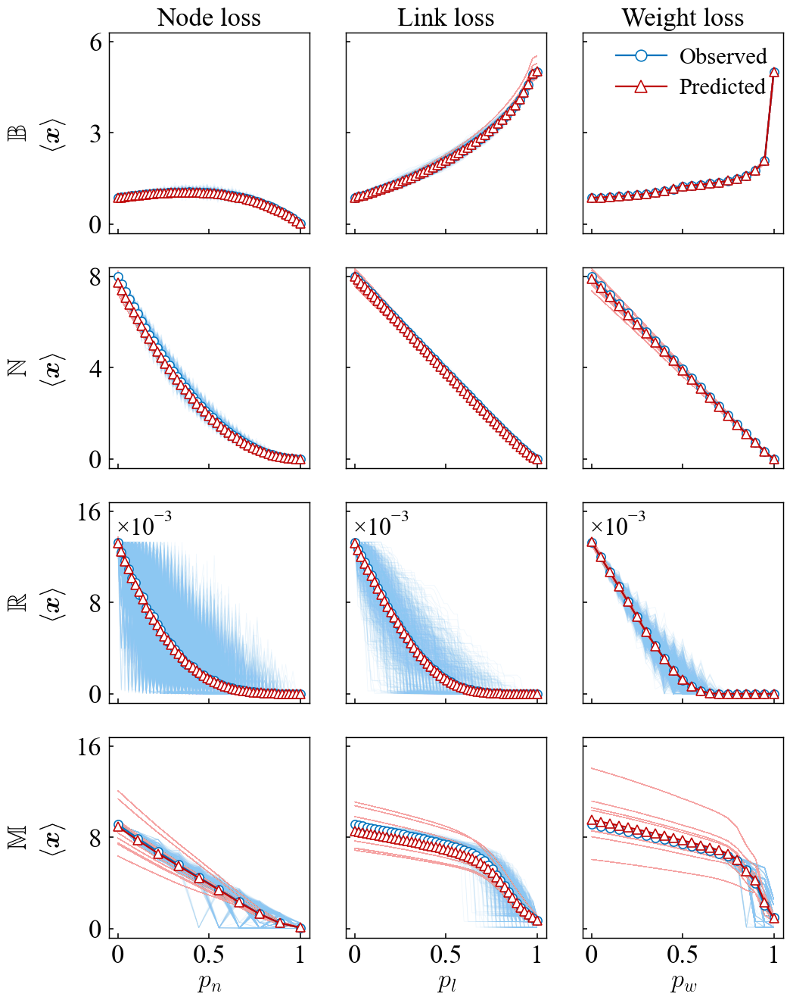

In [12]:
# Figure SI1
"""
Figure SI1
==========
Response-matrix results for the remaining four dynamics:
    B -> Biochemical
    N -> Neuronal
    R -> Regulatory
    M -> Mutualistic

Layout
------
4 rows x 3 columns
    columns: Node loss / Link loss / Weight loss

Style
-----
- Same plotting style as the confirmed Figure 3 code.
- All independent realizations are shown as light curves.
- Mean observed states: blue line with hollow circles.
- Mean predicted states: red line with hollow triangles.
- A single legend is placed in the first row, third column; legend text is 22 pt.
- The figure is saved ONLY as an SVG file: "Figure SI1.svg".
- Dense realization curves are rasterized inside the SVG to reduce file size,
  while mean curves, markers, axes, labels, and legend remain vector.
- Scientific notation follows exactly the Figure 4 implementation:
  Matplotlib mathtext with Times New Roman, multiplier at (0.035, 0.955),
  and fontsize TICK_FS - 2.
"""

from __future__ import annotations

import os
import time
import warnings
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

from scipy.io import loadmat, savemat
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from matplotlib.ticker import FuncFormatter


# ============================================================
# 1. PATH
# ============================================================

BASE_PATH = Path(r"F:\NP-real\1Coding\1Main function\compute data")
OUTPUT_SVG = Path.cwd() / "Figure SI1.svg"


# ============================================================
# 2. DYNAMICS / PERTURBATIONS
#    Order confirmed by the user: B -> N -> R -> M
# ============================================================

DYNAMICS = [
    {
        "name": "Biochemical",
        "symbol": r"$\mathbb{B}$",
        "folder_prefix": "8.Biochemical_Mycoplasma genitalium",
    },
    {
        "name": "Neuronal",
        "symbol": r"$\mathbb{N}$",
        "folder_prefix": "7.Neuronal_C elegansCJ",
    },
    {
        "name": "Regulatory",
        "symbol": r"$\mathbb{R}$",
        "folder_prefix": "5.Regulatory_ Escherichia coli25",
    },
    {
        "name": "Mutualistic",
        "symbol": r"$\mathbb{M}$",
        "folder_prefix": "1.Mutualistic_Coral Reefs",
    },
]

PERTURBATIONS = [
    {
        "suffix": "_perturbation_type1",
        "title": "Node loss",
        "xlabel": r"$p_n$",
    },
    {
        "suffix": "_perturbation_type2",
        "title": "Link loss",
        "xlabel": r"$p_l$",
    },
    {
        "suffix": "_perturbation_type3",
        "title": "Weight loss",
        "xlabel": r"$p_w$",
    },
]


# ============================================================
# 3. FONT / STYLE
# ============================================================

TICK_FS = 25
AXIS_LABEL_FS = 25
TITLE_FS = 25
LEGEND_FS = 22
ROW_SYMBOL_FS = 25

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "axes.linewidth": 1.10,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

plt.rcParams["svg.fonttype"] = "none"

MIKTEX_BIN = Path(
    r"D:\Users\xuren\AppData\Local\Programs\MiKTeX\miktex\bin\x64"
)
LATEX_EXE = MIKTEX_BIN / "latex.exe"
USE_REAL_LATEX = LATEX_EXE.exists()

if USE_REAL_LATEX:
    os.environ["PATH"] = str(MIKTEX_BIN) + os.pathsep + os.environ.get("PATH", "")
    plt.rcParams["text.latex.preamble"] = r"\usepackage{amsmath,amssymb,bm}"
    MEAN_STATE_LABEL = r"$\langle \bm{x}\rangle$"
else:
    warnings.warn(
        "MiKTeX latex.exe was not found. Matplotlib mathtext will be used."
    )
    MEAN_STATE_LABEL = r"$\langle \mathbf{x}\rangle$"


# ============================================================
# 4. COLORS / LINES / MARKERS
# ============================================================

BLUE = (0.00, 0.45, 0.74)
RED = (0.75, 0.00, 0.00)
BLUE_LIGHT = (0.55, 0.78, 0.95)
RED_LIGHT = (0.96, 0.64, 0.64)

REALIZATION_LINEWIDTH = 0.55
REALIZATION_ALPHA = 0.14
MEAN_LINEWIDTH = 1.62
MARKER_SIZE = 8.1
N_VISIBLE_MARKERS = 5


# ============================================================
# 5. FIGURE GEOMETRY
# ============================================================

N_ROWS = len(DYNAMICS)
N_COLS = len(PERTURBATIONS)

PANEL_SIDE = 2.65
COL_GAP = 0.48
ROW_GAP = 0.45

LEFT_MARGIN = 1.75
RIGHT_MARGIN = 0.30
TOP_MARGIN = 0.55
BOTTOM_MARGIN = 1.00

FIG_W = LEFT_MARGIN + N_COLS * PANEL_SIDE + (N_COLS - 1) * COL_GAP + RIGHT_MARGIN
FIG_H = BOTTOM_MARGIN + N_ROWS * PANEL_SIDE + (N_ROWS - 1) * ROW_GAP + TOP_MARGIN

LINEAR_X_MARGIN = 0.05
Y_TICK_MARGIN_RATIO = 0.05


# ============================================================
# 6. FORMATTERS / NICE NUMBERS
# ============================================================

def clean_number(x, pos=None):
    if abs(x - round(x)) < 1e-10:
        return f"{int(round(x))}"
    return f"{x:g}"


CLEAN_FORMATTER = FuncFormatter(clean_number)


def nice_number(x, round_=False):
    if x <= 0:
        return 1.0

    expv = np.floor(np.log10(x))
    f = x / 10 ** expv

    if round_:
        if f < 1.5:
            nf = 1.0
        elif f < 3.0:
            nf = 2.0
        elif f < 7.0:
            nf = 5.0
        else:
            nf = 10.0
    else:
        if f <= 1.0:
            nf = 1.0
        elif f <= 2.0:
            nf = 2.0
        elif f <= 5.0:
            nf = 5.0
        else:
            nf = 10.0

    return nf * 10 ** expv


def choose_three_ticks(data_min, data_max):
    data_min = float(data_min)
    data_max = float(data_max)

    if not np.isfinite(data_min) or not np.isfinite(data_max):
        return np.array([0.0, 0.5, 1.0])

    if abs(data_max - data_min) < 1e-14:
        if abs(data_max) < 1e-14:
            return np.array([0.0, 0.5, 1.0])
        span = abs(data_max)
        data_min -= 0.1 * span
        data_max += 0.1 * span

    span = data_max - data_min

    if data_min >= 0 and data_min <= 0.18 * max(abs(data_max), 1e-12):
        tick_min = 0.0
        tick_max = nice_number(data_max, round_=False)
        if tick_max <= 0:
            tick_max = max(1.0, data_max)
        return np.array([tick_min, 0.5 * tick_max, tick_max])

    if data_max <= 0 and abs(data_max) <= 0.18 * max(abs(data_min), 1e-12):
        tick_max = 0.0
        tick_min = -nice_number(abs(data_min), round_=False)
        return np.array([tick_min, 0.5 * tick_min, tick_max])

    raw_step = span / 2.0
    step = nice_number(raw_step, round_=True)
    tick_min = np.floor(data_min / step) * step
    tick_max = np.ceil(data_max / step) * step

    mid = 0.5 * (tick_min + tick_max)
    return np.array([tick_min, mid, tick_max])


def choose_sci_exponent(values):
    vals = np.asarray(values, dtype=float)
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return 0

    vmax = np.max(np.abs(vals))
    if vmax <= 0:
        return 0

    expv = int(np.floor(np.log10(vmax)))
    if abs(expv) >= 2:
        return expv
    return 0


def use_inside_scientific(
    ax,
    axis="y",
    power=4,
    position="upper left",
):
    """Scientific-notation formatting copied from Figure 4."""
    scale = 10.0 ** power

    formatter = FuncFormatter(
        lambda value, pos: clean_number(value / scale)
    )

    if axis == "x":
        ax.xaxis.set_major_formatter(formatter)
    elif axis == "y":
        ax.yaxis.set_major_formatter(formatter)
    else:
        raise ValueError("axis must be 'x' or 'y'")

    positions = {
        "upper left":  (0.035, 0.955, "left",  "top"),
        "upper right": (0.965, 0.955, "right", "top"),
        "lower left":  (0.035, 0.045, "left",  "bottom"),
        "lower right": (0.965, 0.045, "right", "bottom"),
    }

    x_text, y_text, ha, va = positions[position]

    ax.text(
        x_text,
        y_text,
        rf"$\times 10^{{{power}}}$",
        transform=ax.transAxes,
        ha=ha,
        va=va,
        fontsize=TICK_FS - 2,
        fontname="Times New Roman",
        zorder=20,
    )


# ============================================================
# 7. MATLAB FILE HELPERS
# ============================================================

def is_mat_v73(path: Path) -> bool:
    try:
        return h5py.is_hdf5(path)
    except Exception:
        return False


def _decode_hdf5_numeric_dataset(dataset):
    arr = np.asarray(dataset)

    if arr.dtype.fields is not None:
        fields = arr.dtype.fields.keys()
        if "real" in fields and "imag" in fields:
            arr = arr["real"] + 1j * arr["imag"]

    if arr.ndim >= 2:
        arr = np.transpose(arr, axes=tuple(range(arr.ndim - 1, -1, -1)))

    return np.asarray(arr)


def load_mat_variable(path: Path, variable: str):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"File not found:\n{path}")

    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            if variable not in f:
                raise KeyError(
                    f"Variable '{variable}' not found in:\n{path}\nAvailable variables: {list(f.keys())}"
                )
            obj = f[variable]
            if not isinstance(obj, h5py.Dataset):
                raise TypeError(
                    f"Variable '{variable}' in {path} is not a simple numeric HDF5 dataset."
                )
            return _decode_hdf5_numeric_dataset(obj)

    data = loadmat(path)
    if variable not in data:
        available = [k for k in data.keys() if not k.startswith("__")]
        raise KeyError(
            f"Variable '{variable}' not found in:\n{path}\nAvailable variables: {available}"
        )
    return np.asarray(data[variable])


def load_first_data_variable(path: Path):
    path = Path(path)

    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            keys = [k for k in f.keys() if not k.startswith("#")]
            if not keys:
                raise ValueError(f"No usable variables found in:\n{path}")
            return _decode_hdf5_numeric_dataset(f[keys[0]])

    data = loadmat(path)
    keys = [k for k in data.keys() if not k.startswith("__")]
    if not keys:
        raise ValueError(f"No usable variables found in:\n{path}")
    return np.asarray(data[keys[0]])


# ============================================================
# 8. TRUNCATED-SVD PSEUDOINVERSE
# ============================================================

def pinv_trunc(A, rel_tol=1e-10):
    A = np.asarray(A, dtype=float)
    U, s, Vh = np.linalg.svd(A, full_matrices=False)

    if s.size == 0:
        return np.zeros_like(A.T)

    tau = rel_tol * (float(np.max(s)) + np.finfo(float).eps)
    keep = s > tau

    rank_num = int(np.sum(keep))
    n = min(A.shape)

    if rank_num < n:
        warnings.warn(
            "Matrix is near-singular: "
            f"numerical rank = {rank_num} < {n}. "
            "Using truncated SVD pseudoinverse. "
            f"tau = {tau:.3e}",
            RuntimeWarning,
        )
        time.sleep(2)

    s_inv = np.zeros_like(s)
    s_inv[keep] = 1.0 / s[keep]
    return (Vh.T * s_inv) @ U.T


# ============================================================
# 9. PROCESS ONE CASE
# ============================================================

def process_one_case(folder: Path, case_name: str):
    folder = Path(folder)

    print("\n" + "=" * 76)
    print(case_name)
    print(f"Folder: {folder}")
    print("=" * 76)

    if not folder.exists():
        raise FileNotFoundError(f"Folder not found:\n{folder}")

    files = sorted(folder.glob("x0*.mat"), key=lambda p: p.name)
    M = len(files)
    print(f"Found {M} training files.")

    if M == 0:
        raise FileNotFoundError(f"No x0*.mat training files found in:\n{folder}")

    first_outputs = load_mat_variable(files[0], "outputs")
    if first_outputs.ndim != 3:
        raise ValueError(
            "'outputs' must be a 3D array.\n"
            f"File: {files[0]}\nShape: {first_outputs.shape}"
        )

    _, P, N = first_outputs.shape
    print(f"Number of perturbations P = {P}")
    print(f"Number of nodes N = {N}")

    X0 = np.zeros((M, N), dtype=float)
    Xbar = np.zeros((M, P, N), dtype=float)

    for i, mat_file in enumerate(files):
        outputs = load_mat_variable(mat_file, "outputs")
        x0 = load_mat_variable(mat_file, "x0")

        if outputs.ndim != 3:
            raise ValueError(
                f"'outputs' in {mat_file.name} must be 3D; got {outputs.shape}"
            )

        if outputs.shape[1:] != (P, N):
            raise ValueError(
                f"Unexpected outputs shape in {mat_file.name}: {outputs.shape}; expected (*, {P}, {N})"
            )

        x0_flat = np.asarray(x0).reshape(-1)
        if x0_flat.size != N:
            raise ValueError(
                f"Unexpected x0 size in {mat_file.name}: {x0_flat.size}; expected {N}"
            )

        X0[i, :] = x0_flat
        Xbar[i, :, :] = np.mean(outputs, axis=0)

    C00 = (X0.T @ X0) / M
    C00_inv = pinv_trunc(C00)

    R_p = np.zeros((N, N, P), dtype=float)
    for p in range(P):
        Xp = Xbar[:, p, :]
        Cp0 = (Xp.T @ X0) / M
        R_p[:, :, p] = Cp0 @ C00_inv

    savemat(folder / "R_p.mat", {"R_p": R_p}, do_compression=True)
    print("R_p.mat has been saved.")

    test_file = folder / "X_test.mat"
    if not test_file.exists():
        raise FileNotFoundError(f"X_test.mat was not found in:\n{folder}")

    try:
        data3D = load_mat_variable(test_file, "X_test")
    except KeyError:
        data3D = load_first_data_variable(test_file)
        warnings.warn(
            'Variable "X_test" was not found. Using the first available variable instead.'
        )

    data3D = np.asarray(data3D)
    if data3D.ndim != 3:
        raise ValueError(f"X_test must be 3D. Shape: {data3D.shape}")

    data_for_prediction = np.delete(data3D, 1, axis=1)
    num_exps, num_perturb, num_nodes = data_for_prediction.shape

    if num_nodes != N:
        raise ValueError(
            "Node number mismatch:\n"
            f"training N = {N}\n"
            f"testing N = {num_nodes}"
        )

    if num_perturb != P:
        raise ValueError(
            "Perturbation-number mismatch:\n"
            f"R_p has P = {P}\n"
            f"testing data after deletion has P = {num_perturb}"
        )

    X0_test = data_for_prediction[:, 0, :]
    X_p = np.zeros((num_exps, num_perturb, num_nodes), dtype=float)

    for p in range(num_perturb):
        Rp_current = R_p[:, :, p]
        Xp_current = Rp_current @ X0_test.T
        X_p[:, p, :] = Xp_current.T

    savemat(folder / "X_p.mat", {"X_p": X_p}, do_compression=True)
    print("X_p.mat has been saved.")

    integrated_data = np.delete(data3D, 0, axis=1)
    response_data = X_p

    if integrated_data.shape != response_data.shape:
        raise ValueError(
            f"Size mismatch in {case_name}:\n"
            f"Integrated dynamics = {integrated_data.shape}\n"
            f"Response matrix     = {response_data.shape}"
        )

    integrated_by_exp = np.mean(integrated_data, axis=2)
    response_by_exp = np.mean(response_data, axis=2)

    integrated_mean = np.mean(integrated_by_exp, axis=0)
    response_mean = np.mean(response_by_exp, axis=0)

    x = np.linspace(0.0, 1.0, integrated_mean.size)

    return {
        "x": x,
        "integrated_by_exp": np.real_if_close(integrated_by_exp),
        "response_by_exp": np.real_if_close(response_by_exp),
        "integrated_mean": np.real_if_close(integrated_mean),
        "response_mean": np.real_if_close(response_mean),
    }


# ============================================================
# 10. COMPUTE ALL 12 CASES
# ============================================================

ALL_DATA = []

for dynamics in DYNAMICS:
    row_data = []
    for perturbation in PERTURBATIONS:
        folder = BASE_PATH / (dynamics["folder_prefix"] + perturbation["suffix"])
        case_name = f"{dynamics['name']} | {perturbation['title']}"
        row_data.append(process_one_case(folder, case_name))
    ALL_DATA.append(row_data)


# ============================================================
# 11. UNIFIED Y SETTINGS FOR EACH ROW
#    User-specified ticks:
#      B -> 0, 3, 6
#      N -> 0, 4, 8
#      R -> 0, 8, 16   with ×10^{-3}
#      M -> 0, 8, 16
# ============================================================

ROW_TICK_OVERRIDES = {
    "Biochemical": {
        "yticks": np.array([0.0, 3.0, 6.0]),
        "sci_exp": 0,
    },
    "Neuronal": {
        "yticks": np.array([0.0, 4.0, 8.0]),
        "sci_exp": 0,
    },
    "Regulatory": {
        "yticks": np.array([0.0, 8.0e-3, 16.0e-3]),
        "sci_exp": -3,
    },
    "Mutualistic": {
        "yticks": np.array([0.0, 8.0, 16.0]),
        "sci_exp": 0,
    },
}

ROW_Y_SETTINGS = []

for row, dynamics in enumerate(DYNAMICS):
    all_values = []
    for col in range(N_COLS):
        data = ALL_DATA[row][col]
        all_values.append(np.asarray(data["integrated_by_exp"]).reshape(-1))
        all_values.append(np.asarray(data["response_by_exp"]).reshape(-1))

    all_values = np.concatenate(all_values)
    all_values = all_values[np.isfinite(all_values)]

    override = ROW_TICK_OVERRIDES.get(dynamics["name"])

    if override is not None:
        ticks = np.asarray(override["yticks"], dtype=float)
        sci_exp = int(override["sci_exp"])
    else:
        if all_values.size == 0:
            ticks = np.array([0.0, 0.5, 1.0])
        else:
            ticks = choose_three_ticks(np.min(all_values), np.max(all_values))
        sci_exp = choose_sci_exponent(ticks)

    tick_min = float(np.min(ticks))
    tick_max = float(np.max(ticks))
    tick_span = tick_max - tick_min
    if tick_span <= 0:
        tick_span = max(abs(tick_max), 1.0)

    # Use the displayed tick range itself to set the panel limits.
    # Therefore, every row has the same relative distance from the
    # highest labeled tick to the top frame (and from the lowest labeled
    # tick to the bottom frame), independent of the raw realization range.
    y_pad = Y_TICK_MARGIN_RATIO * tick_span
    common_ymin = tick_min - y_pad
    common_ymax = tick_max + y_pad

    # Warn rather than silently changing the limits if any realization
    # lies outside the user-specified plotting range.
    if all_values.size > 0:
        data_min = float(np.min(all_values))
        data_max = float(np.max(all_values))
        if data_min < common_ymin or data_max > common_ymax:
            warnings.warn(
                f"{dynamics['name']}: some realization values lie outside "
                f"the fixed y-range [{common_ymin:g}, {common_ymax:g}]. "
                f"Data range is [{data_min:g}, {data_max:g}].",
                RuntimeWarning,
            )

    ROW_Y_SETTINGS.append({
        "ylim": (common_ymin, common_ymax),
        "yticks": ticks,
        "sci_exp": sci_exp,
    })

    print(
        f"{dynamics['name']} y-axis: {common_ymin:g} to {common_ymax:g}; "
        f"ticks = {ticks.tolist()}; sci_exp = {sci_exp}"
    )


# ============================================================
# 12. FIGURE / AXES
# ============================================================

fig = plt.figure(figsize=(FIG_W, FIG_H), facecolor="white")


def inch_box(left_in, bottom_in, width_in, height_in):
    return [
        left_in / FIG_W,
        bottom_in / FIG_H,
        width_in / FIG_W,
        height_in / FIG_H,
    ]


axes = [[None for _ in range(N_COLS)] for _ in range(N_ROWS)]

for row in range(N_ROWS):
    bottom = BOTTOM_MARGIN + (N_ROWS - 1 - row) * (PANEL_SIDE + ROW_GAP)
    for col in range(N_COLS):
        left = LEFT_MARGIN + col * (PANEL_SIDE + COL_GAP)
        axes[row][col] = fig.add_axes(
            inch_box(left, bottom, PANEL_SIDE, PANEL_SIDE)
        )


# ============================================================
# 13. COMMON AXIS STYLE
# ============================================================

def style_axis(ax):
    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=4.5,
        width=1.15,
        labelsize=TICK_FS,
        pad=6.5,
    )
    ax.minorticks_off()

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontname("Times New Roman")
        label.set_fontsize(TICK_FS)

    for spine in ax.spines.values():
        spine.set_linewidth(1.05)

    ax.set_box_aspect(1)


# ============================================================
# 14. PLOT ALL 4 x 3 PANELS
# ============================================================

for row, dynamics in enumerate(DYNAMICS):
    common_ylim = ROW_Y_SETTINGS[row]["ylim"]
    common_yticks = ROW_Y_SETTINGS[row]["yticks"]
    sci_exp = ROW_Y_SETTINGS[row]["sci_exp"]

    for col, perturbation in enumerate(PERTURBATIONS):
        ax = axes[row][col]
        data = ALL_DATA[row][col]

        x = np.asarray(data["x"])
        integrated_by_exp = np.asarray(data["integrated_by_exp"])
        response_by_exp = np.asarray(data["response_by_exp"])
        integrated_mean = np.asarray(data["integrated_mean"])
        response_mean = np.asarray(data["response_mean"])

        integrated_segments = [np.column_stack((x, y)) for y in integrated_by_exp]
        response_segments = [np.column_stack((x, y)) for y in response_by_exp]

        integrated_collection = LineCollection(
            integrated_segments,
            colors=[BLUE_LIGHT],
            linewidths=REALIZATION_LINEWIDTH,
            alpha=REALIZATION_ALPHA,
            zorder=1,
            rasterized=True,
        )
        response_collection = LineCollection(
            response_segments,
            colors=[RED_LIGHT],
            linewidths=REALIZATION_LINEWIDTH,
            alpha=REALIZATION_ALPHA,
            zorder=1,
            rasterized=True,
        )

        ax.add_collection(integrated_collection)
        ax.add_collection(response_collection)

        marker_idx = sorted(
            set(
                int(np.argmin(np.abs(x - target)))
                for target in np.linspace(0.0, 1.0, N_VISIBLE_MARKERS)
            )
        )

        ax.plot(
            x,
            integrated_mean,
            color=BLUE,
            linestyle="-",
            linewidth=MEAN_LINEWIDTH,
            marker="o",
            markevery=1,
            markersize=MARKER_SIZE,
            markerfacecolor="white",
            markeredgecolor=BLUE,
            markeredgewidth=1.15,
            zorder=4,
        )

        ax.plot(
            x,
            response_mean,
            color=RED,
            linestyle="-",
            linewidth=MEAN_LINEWIDTH,
            marker="^",
            markevery=1,
            markersize=MARKER_SIZE,
            markerfacecolor="white",
            markeredgecolor=RED,
            markeredgewidth=1.15,
            zorder=5,
        )

        ax.set_xlim(-LINEAR_X_MARGIN, 1.0 + LINEAR_X_MARGIN)
        ax.set_xticks([0.0, 0.5, 1.0])
        ax.xaxis.set_major_formatter(CLEAN_FORMATTER)

        if row < N_ROWS - 1:
            ax.tick_params(axis="x", labelbottom=False)
        if row == N_ROWS - 1:
            ax.set_xlabel(
                perturbation["xlabel"],
                fontsize=AXIS_LABEL_FS,
                labelpad=1.0,
                usetex=USE_REAL_LATEX,
            )

        ax.set_ylim(common_ylim)
        ax.set_yticks(common_yticks)
        ax.yaxis.set_major_formatter(CLEAN_FORMATTER)

        style_axis(ax)

        # Scientific notation follows the exact Figure 4 implementation.
        # For Regulatory: displayed ticks are 0, 8, 16 with ×10^{-3}.
        if sci_exp != 0:
            use_inside_scientific(
                ax,
                axis="y",
                power=sci_exp,
                position="upper left",
            )

        if col > 0:
            ax.tick_params(axis="y", labelleft=False)

        if row == 0:
            ax.set_title(
                perturbation["title"],
                fontsize=TITLE_FS,
                pad=6.5,
                fontname="Times New Roman",
            )


# ============================================================
# 15. ALIGNED LEFT-SIDE LABEL COLUMNS
# ============================================================

fig.canvas.draw()
renderer = fig.canvas.get_renderer()

tick_left_edges = []
for row in range(N_ROWS):
    ax_left = axes[row][0]
    for tick_label in ax_left.get_yticklabels():
        if not tick_label.get_visible():
            continue
        text_value = tick_label.get_text()
        if text_value == "":
            continue
        bbox_display = tick_label.get_window_extent(renderer=renderer)
        bbox_figure = bbox_display.transformed(fig.transFigure.inverted())
        tick_left_edges.append(bbox_figure.x0)

if not tick_left_edges:
    raise RuntimeError("Could not determine the y-tick-label positions.")

LEFTMOST_YTICK_X = min(tick_left_edges)
MEAN_LABEL_GAP = 0.028
DYNAMICS_LABEL_GAP = 0.040
MEAN_STATE_LABEL_X = LEFTMOST_YTICK_X - MEAN_LABEL_GAP
DYNAMICS_LABEL_X = MEAN_STATE_LABEL_X - DYNAMICS_LABEL_GAP

for row, dynamics in enumerate(DYNAMICS):
    pos = axes[row][0].get_position()
    center_y = pos.y0 + pos.height / 2.0

    fig.text(
        DYNAMICS_LABEL_X,
        center_y,
        dynamics["symbol"],
        fontsize=ROW_SYMBOL_FS,
        ha="center",
        va="center",
        rotation=90,
        usetex=USE_REAL_LATEX,
        fontname="Times New Roman",
    )

    fig.text(
        MEAN_STATE_LABEL_X,
        center_y,
        MEAN_STATE_LABEL,
        fontsize=AXIS_LABEL_FS,
        ha="center",
        va="center",
        rotation=90,
        usetex=USE_REAL_LATEX,
        fontname="Times New Roman",
    )


# ============================================================
# 16. LEGEND
# ============================================================

legend_ax = axes[0][2]
legend_handles = [
    Line2D(
        [0], [0],
        color=BLUE,
        linestyle="-",
        linewidth=MEAN_LINEWIDTH,
        marker="o",
        markerfacecolor="white",
        markeredgecolor=BLUE,
        markeredgewidth=1.15,
        markersize=10.5,
    ),
    Line2D(
        [0], [0],
        color=RED,
        linestyle="-",
        linewidth=MEAN_LINEWIDTH,
        marker="^",
        markerfacecolor="white",
        markeredgecolor=RED,
        markeredgewidth=1.15,
        markersize=10.9,
    ),
]

legend = legend_ax.legend(
    legend_handles,
    ["Observed", "Predicted"],
    loc="upper right",
    frameon=False,
    fontsize=LEGEND_FS,
    handlelength=2.20,
    handletextpad=0.55,
    labelspacing=0.42,
    borderpad=0.15,
)

for txt in legend.get_texts():
    txt.set_fontname("Times New Roman")
    txt.set_fontsize(LEGEND_FS)


# ============================================================
# 17. SAVE ONLY AS SVG + SHOW
# ============================================================

fig.savefig(
    OUTPUT_SVG,
    format="svg",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
    facecolor="none",
    edgecolor="none",
)

print(f"\nFigure SI1 SVG saved to:\n  {OUTPUT_SVG}")
plt.show()



Noisy voter | Node loss
Folder: F:\NP-real\1Coding\1Main function\compute data\4.noisy voter_Dolphin social network_perturbation_type1
Observed shape : (1000, 62, 62)
Predicted shape: (1000, 62, 62)
Source          : existing X_test.mat and X_p.mat only
R_p recomputed  : NO

Noisy voter | Link loss
Folder: F:\NP-real\1Coding\1Main function\compute data\4.noisy voter_Dolphin social network_perturbation_type2
Observed shape : (1000, 41, 62)
Predicted shape: (1000, 41, 62)
Source          : existing X_test.mat and X_p.mat only
R_p recomputed  : NO

Noisy voter | Weight loss
Folder: F:\NP-real\1Coding\1Main function\compute data\4.noisy voter_Dolphin social network_perturbation_type3
Observed shape : (1000, 21, 62)
Predicted shape: (1000, 21, 62)
Source          : existing X_test.mat and X_p.mat only
R_p recomputed  : NO

Epidemics | Node loss
Folder: F:\NP-real\1Coding\1Main function\compute data\2.Epidemics (SIS)_MIT Reality Mining_perturbation_type1
Observed shape : (1000, 48, 95)
Pred

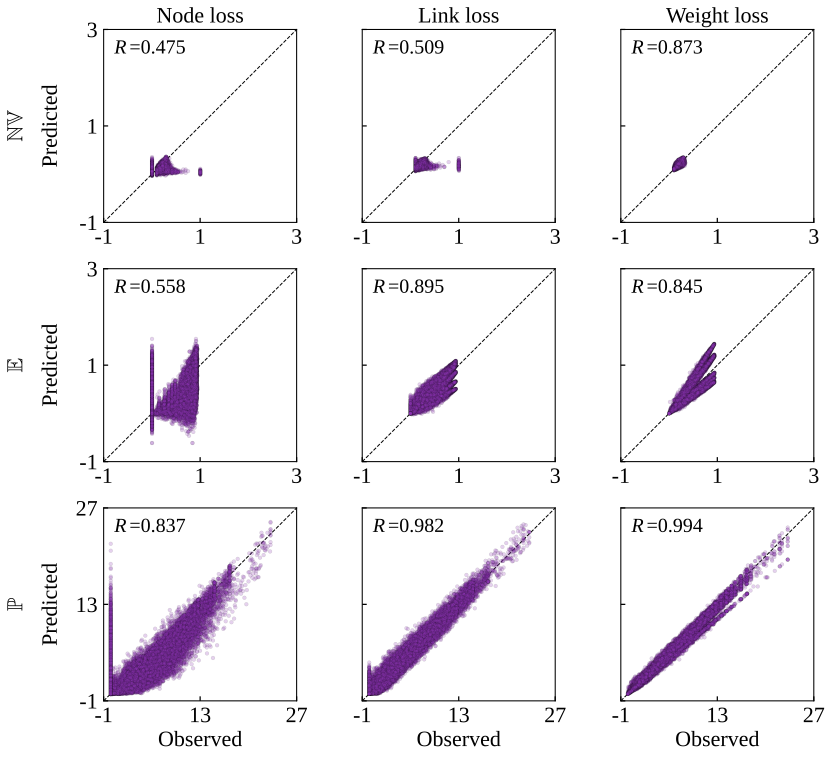

In [ ]:
#Figure SI2-SI3 
"""
Figure SI3: node-wise observed-vs-predicted validation
FINAL VERSION
-------------
- ONLY reads existing X_test.mat and X_p.mat.
- Does NOT recompute response matrices.
- Dynamics: NV, E, P, B, N, R, M.
- Columns: Node loss, Link loss, Weight loss.
- 7 x 3 panels.
- Purple node-level observed-vs-predicted scatter.
- Black dashed y=x reference line.
- Upper-left statistic:
      R = ...
- p-values are not displayed.
- x label "Observed" appears ONLY on the bottom row.
- "Predicted" is a figure-level vertical label aligned beside each row.
- Dynamics symbols use the same LaTeX rendering and aligned vertical-column style as Figure 3.
- Each axis has exactly THREE ticks:
      lower, middle, upper.
- Within each dynamics row, ALL three panels use the SAME x/y limits
  and the SAME three tick values, so the horizontal scales are aligned.
- Within each panel, x and y limits are identical, so y=x is a true
  45-degree line.
- Every panel starts from -1 on both x and y axes.
- All displayed axis tick labels are integers; no decimal ticks are used.
- Pearson R is calculated using ALL finite node-level pairs.
- Pearson R uses all finite node-level pairs, while scatter rendering is limited to at most 50,000 reproducibly sampled pairs per panel.
- The figure is saved as "Figure SI3.svg" and also displayed in the notebook.
"""
from __future__ import annotations
import itertools
import os
import warnings
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import pearsonr
from matplotlib.ticker import FuncFormatter
from IPython.display import SVG, display
# ============================================================
# 1. PATHS / CASES
# ============================================================
BASE_PATH = Path(r"F:\NP-real\1Coding\1Main function\compute data")
DYNAMICS = [
    (
        "Noisy voter",
        r"$\mathbb{NV}$",
        "4.noisy voter_Dolphin social network",
    ),
    (
        "Epidemics",
        r"$\mathbb{E}$",
        "2.Epidemics (SIS)_MIT Reality Mining",
    ),
    (
        "Population",
        r"$\mathbb{P}$",
        "6.Population_Little Rock Lake",
    ),
    (
        "Biochemical",
        r"$\mathbb{B}$",
        "8.Biochemical_Mycoplasma genitalium",
    ),
    (
        "Neuronal",
        r"$\mathbb{N}$",
        "7.Neuronal_C elegansCJ",
    ),
    (
        "Regulatory",
        r"$\mathbb{R}$",
        "5.Regulatory_ Escherichia coli25",
    ),
    (
        "Mutualistic",
        r"$\mathbb{M}$",
        "1.Mutualistic_Coral Reefs",
    ),
]
PERTURBATIONS = [
    ("_perturbation_type1", "Node loss"),
    ("_perturbation_type2", "Link loss"),
    ("_perturbation_type3", "Weight loss"),
]
# ============================================================
# 2. FIGURE STYLE
# ============================================================
TICK_FS = 22
AXIS_LABEL_FS = 22
TITLE_FS = 22
STAT_FS = 20
ROW_SYMBOL_FS = 22
PURPLE = (0.55, 0.20, 0.70)
SCATTER_SIZE = 14
SCATTER_ALPHA = 0.22
SCATTER_EDGEWIDTH = 0.28
IDENTITY_LINEWIDTH = 1.0
# Pearson R uses ALL finite node-level pairs.
# For rendering speed, each panel displays at most 50,000 randomly
# sampled finite node-level pairs. The random seed makes the displayed
# subset reproducible across runs.
MAX_SCATTER_POINTS = 50000
RNG = np.random.default_rng(20260910)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "axes.linewidth": 1.10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "svg.fonttype": "none",
})
# This follows the Figure SI4 symbol route. When MiKTeX is available, the
# requested blackboard-bold dynamics symbols render upright as \mathbb{NV},
# \mathbb{E}, \mathbb{P}, etc.; otherwise STIX mathtext is used as a fallback.
MIKTEX_BIN = Path(
    r"D:\Users\xuren\AppData\Local\Programs\MiKTeX\miktex\bin\x64"
)
LATEX_EXE = MIKTEX_BIN / "latex.exe"
USE_REAL_LATEX = LATEX_EXE.exists()
if USE_REAL_LATEX:
    os.environ["PATH"] = str(MIKTEX_BIN) + os.pathsep + os.environ.get("PATH", "")
    plt.rcParams["text.latex.preamble"] = r"\usepackage{amsmath,amssymb,bm}"
else:
    warnings.warn(
        "MiKTeX latex.exe was not found; using the STIX mathtext fallback "
        "for upright blackboard-bold dynamics symbols."
    )
    plt.rcParams["mathtext.fontset"] = "stix"
# ============================================================
# 3. MATLAB FILE READER
# ============================================================
def is_mat_v73(path: Path) -> bool:
    try:
        return h5py.is_hdf5(path)
    except Exception:
        return False
def _read_h5_numeric(dataset):
    """
    Read a MATLAB v7.3 numeric HDF5 dataset.
    MATLAB v7.3 stores dimensions in reverse order in HDF5, so
    reverse the axes to recover the MATLAB-like array orientation.
    """
    arr = np.asarray(dataset)
    if arr.dtype.fields is not None:
        names = arr.dtype.fields.keys()
        if "real" in names and "imag" in names:
            arr = arr["real"] + 1j * arr["imag"]
    if arr.ndim >= 2:
        arr = np.transpose(
            arr,
            axes=tuple(range(arr.ndim - 1, -1, -1)),
        )
    return np.asarray(arr)
def load_mat_variable(path: Path, variable: str):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"File not found:\n{path}")
    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            if variable not in f:
                raise KeyError(
                    f"Variable '{variable}' not found in:\n{path}\n"
                    f"Available variables: {list(f.keys())}"
                )
            obj = f[variable]
            if not isinstance(obj, h5py.Dataset):
                raise TypeError(
                    f"'{variable}' in {path} is not a numeric HDF5 dataset."
                )
            return _read_h5_numeric(obj)
    data = loadmat(path)
    if variable not in data:
        available = [
            key for key in data.keys()
            if not key.startswith("__")
        ]
        raise KeyError(
            f"Variable '{variable}' not found in:\n{path}\n"
            f"Available variables: {available}"
        )
    return np.asarray(data[variable])
def load_preferred_or_first(path: Path, preferred_variable: str):
    """
    Prefer a named variable; if absent, use the first usable variable.
    """
    try:
        return load_mat_variable(path, preferred_variable)
    except KeyError:
        if is_mat_v73(path):
            with h5py.File(path, "r") as f:
                keys = [
                    key for key in f.keys()
                    if not key.startswith("#")
                ]
                if not keys:
                    raise ValueError(f"No usable variable found in:\n{path}")
                warnings.warn(
                    f"'{preferred_variable}' not found in {path.name}; "
                    f"using '{keys[0]}' instead."
                )
                return _read_h5_numeric(f[keys[0]])
        data = loadmat(path)
        keys = [
            key for key in data.keys()
            if not key.startswith("__")
        ]
        if not keys:
            raise ValueError(f"No usable variable found in:\n{path}")
        warnings.warn(
            f"'{preferred_variable}' not found in {path.name}; "
            f"using '{keys[0]}' instead."
        )
        return np.asarray(data[keys[0]])
# ============================================================
# 4. SHAPE ALIGNMENT
# ============================================================
def orient_to_shape(array, target_shape, label):
    """
    Orient a 3D array to exactly target_shape by trying all axis
    permutations. This makes the script robust to MATLAB/Python
    dimension-order differences.
    No data are averaged or otherwise transformed.
    """
    arr = np.asarray(array).squeeze()
    if arr.ndim != 3:
        raise ValueError(
            f"{label} must be 3D after squeeze; got shape {arr.shape}"
        )
    if arr.shape == target_shape:
        return np.asarray(arr)
    matches = []
    for perm in itertools.permutations(range(3)):
        candidate = np.transpose(arr, perm)
        if candidate.shape == target_shape:
            matches.append(candidate)
    if len(matches) == 1:
        return np.asarray(matches[0])
    if len(matches) > 1:
        # Ambiguity can occur if two dimensions have equal lengths.
        # Use the first matching permutation and report it explicitly.
        warnings.warn(
            f"{label}: more than one axis permutation matches "
            f"target shape {target_shape}; using the first match."
        )
        return np.asarray(matches[0])
    raise ValueError(
        f"Cannot align {label} shape {arr.shape} "
        f"to target shape {target_shape}."
    )
# ============================================================
# 5. DIRECTLY READ X_test.mat AND X_p.mat
# ============================================================
def load_case(folder: Path, label: str):
    """
    Direct validation from existing files only.
    X_test.mat:
        [:, 0, :] = initial state x_0(0)
        [:, 1, :] = intact observed state at t
        [:, 2:, :] = perturbed observed states
    Therefore:
        observed = delete initial-state slice from X_test.
    X_p.mat:
        existing response-matrix predictions, expected to correspond
        directly to the observed array after deletion of the initial slice.
    """
    folder = Path(folder)
    print("\n" + "=" * 76)
    print(label)
    print(f"Folder: {folder}")
    print("=" * 76)
    x_test_file = folder / "X_test.mat"
    x_p_file = folder / "X_p.mat"
    if not x_test_file.exists():
        raise FileNotFoundError(f"Missing X_test.mat:\n{x_test_file}")
    if not x_p_file.exists():
        raise FileNotFoundError(f"Missing X_p.mat:\n{x_p_file}")
    X_test = np.real_if_close(
        np.asarray(
            load_preferred_or_first(
                x_test_file,
                "X_test",
            )
        )
    ).squeeze()
    if X_test.ndim != 3:
        raise ValueError(
            f"X_test must be 3D; got shape {X_test.shape} in:\n{x_test_file}"
        )
    # Delete the initial-state slice.
    observed = np.delete(
        X_test,
        0,
        axis=1,
    )
    X_p_raw = np.real_if_close(
        np.asarray(
            load_preferred_or_first(
                x_p_file,
                "X_p",
            )
        )
    ).squeeze()
    predicted = orient_to_shape(
        X_p_raw,
        observed.shape,
        label="X_p",
    )
    observed = np.asarray(observed, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    if observed.shape != predicted.shape:
        raise ValueError(
            f"Observed and predicted shapes differ:\n"
            f"Observed : {observed.shape}\n"
            f"Predicted: {predicted.shape}"
        )
    print(f"Observed shape : {observed.shape}")
    print(f"Predicted shape: {predicted.shape}")
    print("Source          : existing X_test.mat and X_p.mat only")
    print("R_p recomputed  : NO")
    return {
        "observed": observed,
        "predicted": predicted,
    }
# ============================================================
# 6. LOAD ALL 7 x 3 PANELS
# ============================================================
ALL_RESULTS = []
for dynamics_name, dynamics_symbol, folder_prefix in DYNAMICS:
    row_results = []
    for perturbation_suffix, perturbation_name in PERTURBATIONS:
        folder = BASE_PATH / (
            folder_prefix + perturbation_suffix
        )
        row_results.append(
            load_case(
                folder,
                f"{dynamics_name} | {perturbation_name}",
            )
        )
    ALL_RESULTS.append(row_results)
# ============================================================
# 7. PEARSON R
# ============================================================
def pearson_R(observed, predicted):
    """
    Pearson correlation coefficient R using ALL finite node-level pairs.
    """
    observed = np.asarray(observed, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)
    finite = (
        np.isfinite(observed)
        & np.isfinite(predicted)
    )
    observed = observed[finite]
    predicted = predicted[finite]
    if observed.size < 2:
        return np.nan
    return float(
        pearsonr(observed, predicted).statistic
    )
# ============================================================
# 8. AXIS LIMITS AND EXACTLY THREE ROW-WISE TICKS
# ============================================================
def row_common_limits_and_ticks(row_results):
    """
    Compute ONE common x/y scale for all three panels in the same row.
    Final rule:
        - every x and y axis starts at -1;
        - the upper bound is the smallest ODD integer >= the largest
          finite observed/predicted value in the whole row;
        - exactly three INTEGER ticks are displayed;
        - the middle tick is the exact geometric midpoint of the axis;
        - all three panels in the same dynamics row therefore use
          identical limits and perfectly aligned tick positions.
    Examples:
        -1,  1,  3
        -1, 13, 27
        -1,  3,  7
        -1, 26, 53
    Values below -1, if any, are intentionally clipped because the
    requested common lower bound is -1 for every panel.
    """
    all_values = []
    for result in row_results:
        observed = np.asarray(
            result["observed"],
            dtype=float,
        ).reshape(-1)
        predicted = np.asarray(
            result["predicted"],
            dtype=float,
        ).reshape(-1)
        finite_obs = observed[np.isfinite(observed)]
        finite_pred = predicted[np.isfinite(predicted)]
        if finite_obs.size:
            all_values.append(finite_obs)
        if finite_pred.size:
            all_values.append(finite_pred)
    low = -1
    if not all_values:
        high = 1
    else:
        values = np.concatenate(all_values)
        raw_high = float(np.max(values))
        # First integer that includes all data.
        high = int(np.ceil(raw_high))
        # With low = -1, an odd high guarantees an integer midpoint.
        if high % 2 == 0:
            high += 1
        if high <= low:
            high = 1
    # Exact geometric midpoint of [-1, high].
    midpoint = int((low + high) // 2)
    ticks = np.array(
        [low, midpoint, high],
        dtype=int,
    )
    return (
        (float(low), float(high)),
        ticks,
    )
def integer_formatter(value, pos=None):
    """Display every axis tick as an integer."""
    return f"{int(round(value))}"
TICK_FORMATTER = FuncFormatter(
    integer_formatter
)
# Precompute one common scale for each dynamics row.
ROW_SCALES = [
    row_common_limits_and_ticks(
        ALL_RESULTS[row]
    )
    for row in range(len(DYNAMICS))
]
# ============================================================
# ============================================================
# 9. COMMON AXIS STYLE
# ============================================================
def style_axis(ax):
    ax.grid(False)
    ax.minorticks_off()
    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=4.5,
        width=1.25,
        labelsize=TICK_FS,
        pad=6.0,
    )
    for label in ax.get_xticklabels()+ax.get_yticklabels():
        label.set_fontname("Times New Roman")
        label.set_fontsize(TICK_FS)
    for spine in ax.spines.values():
        spine.set_linewidth(1.05)
# ============================================================
# 10. DRAW ONE INDEPENDENT FIGURE
# ============================================================
def draw_figure(row_indices, output_svg, fig_height):
    n_rows=len(row_indices)
    n_cols=len(PERTURBATIONS)
    fig,axes=plt.subplots(
        nrows=n_rows,
        ncols=n_cols,
        figsize=(12.0,fig_height),
        facecolor="white",
        squeeze=False,
    )
    plt.subplots_adjust(
        left=0.145,
        right=0.985,
        top=0.965,
        bottom=0.085,
        wspace=0.24,
        hspace=0.24,
    )
    for local_row,global_row in enumerate(row_indices):
        dynamics_name,dynamics_symbol,_=DYNAMICS[global_row]
        (axis_low,axis_high),axis_ticks=ROW_SCALES[global_row]
        for col,(_,perturbation_name) in enumerate(PERTURBATIONS):
            ax=axes[local_row,col]
            result=ALL_RESULTS[global_row][col]
            observed=np.asarray(result["observed"],dtype=float).reshape(-1)
            predicted=np.asarray(result["predicted"],dtype=float).reshape(-1)
            finite=np.isfinite(observed)&np.isfinite(predicted)
            observed=observed[finite]
            predicted=predicted[finite]
            if observed.size==0:
                raise ValueError(
                    f"No finite node-level pairs for {dynamics_name} | {perturbation_name}"
                )
            R_value=pearson_R(observed,predicted)
            n_pairs=observed.size
            if n_pairs>MAX_SCATTER_POINTS:
                draw_idx=RNG.choice(
                    n_pairs,
                    size=MAX_SCATTER_POINTS,
                    replace=False,
                )
            else:
                draw_idx=np.arange(n_pairs)
            ax.scatter(
                observed[draw_idx],
                predicted[draw_idx],
                s=SCATTER_SIZE,
                color=PURPLE,
                edgecolors="black",
                linewidths=SCATTER_EDGEWIDTH,
                alpha=SCATTER_ALPHA,
                rasterized=True,
                zorder=3,
            )
            ax.plot(
                [axis_low,axis_high],
                [axis_low,axis_high],
                "k--",
                linewidth=IDENTITY_LINEWIDTH,
                zorder=2,
            )
            ax.set_xlim(axis_low,axis_high)
            ax.set_ylim(axis_low,axis_high)
            ax.set_xticks(axis_ticks)
            ax.set_yticks(axis_ticks)
            ax.xaxis.set_major_formatter(TICK_FORMATTER)
            ax.yaxis.set_major_formatter(TICK_FORMATTER)
            ax.set_aspect("equal",adjustable="box")
            style_axis(ax)
            ax.text(
                0.055,
                0.945,
                rf"$R={R_value:.3f}$",
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=STAT_FS,
                fontname="Times New Roman",
                zorder=10,
            )
            if local_row==0:
                ax.set_title(
                    perturbation_name,
                    fontsize=TITLE_FS,
                    pad=7.0,
                    fontname="Times New Roman",
                    fontweight="normal",
                )
            if local_row==n_rows-1:
                ax.set_xlabel(
                    "Observed",
                    fontsize=AXIS_LABEL_FS,
                    labelpad=4.0,
                    fontname="Times New Roman",
                )
            if col>0:
                ax.tick_params(axis="y",labelleft=False)
    # Determine aligned positions for dynamics symbols and "Predicted"
    # independently for this figure.
    fig.canvas.draw()
    renderer=fig.canvas.get_renderer()
    tick_left_edges=[]
    for local_row in range(n_rows):
        ax_left=axes[local_row,0]
        for tick_label in ax_left.get_yticklabels():
            if not tick_label.get_visible() or tick_label.get_text()=="":
                continue
            bbox_display=tick_label.get_window_extent(renderer=renderer)
            bbox_figure=bbox_display.transformed(fig.transFigure.inverted())
            tick_left_edges.append(bbox_figure.x0)
    if not tick_left_edges:
        raise RuntimeError("Could not determine the y-tick-label positions.")
    leftmost_ytick_x=min(tick_left_edges)
    predicted_label_x=leftmost_ytick_x-0.028
    dynamics_label_x=predicted_label_x-0.040
    for local_row,global_row in enumerate(row_indices):
        dynamics_symbol=DYNAMICS[global_row][1]
        pos=axes[local_row,0].get_position()
        center_y=pos.y0+pos.height/2.0
        fig.text(
            dynamics_label_x,
            center_y,
            dynamics_symbol,
            fontsize=ROW_SYMBOL_FS,
            ha="center",
            va="center",
            rotation=90,
            usetex=USE_REAL_LATEX,
            fontname="Times New Roman",
        )
        fig.text(
            predicted_label_x,
            center_y,
            "Predicted",
            fontsize=AXIS_LABEL_FS,
            ha="center",
            va="center",
            rotation=90,
            fontname="Times New Roman",
        )
    output_svg=Path(output_svg)
    fig.savefig(
        output_svg,
        format="svg",
        dpi=300,
        bbox_inches="tight",
        transparent=True,
        facecolor="none",
        edgecolor="none",
    )
    print(f"SVG saved to: {output_svg}")
    plt.close(fig)
    return output_svg
# ============================================================
# 11. DIRECTLY GENERATE TWO SVG FIGURES
# ============================================================
OUTPUT_SVG_1=draw_figure(
    row_indices=[0,1,2],
    output_svg=Path.cwd()/"Figure SI2.svg",
    fig_height=10.6,
)
OUTPUT_SVG_2=draw_figure(
    row_indices=[3,4,5,6],
    output_svg=Path.cwd()/"Figure SI3.svg",
    fig_height=14.0,
)
# ============================================================
# 12. DISPLAY BOTH SVGs IN NOTEBOOK
# ============================================================
display(SVG(filename=str(OUTPUT_SVG_1)))
display(SVG(filename=str(OUTPUT_SVG_2)))



Noisy voter
  0.noisy voter_Dolphin social network_perturbation_type1_test | L=  100 | error=0.524853 | 95% CI half-width=0.000964447
  0.noisy voter_Dolphin social network_perturbation_type1_test | L=  200 | error=0.486821 | 95% CI half-width=0.000879114
  0.noisy voter_Dolphin social network_perturbation_type1_test | L=  300 | error=0.470499 | 95% CI half-width=0.000869582
  0.noisy voter_Dolphin social network_perturbation_type1_test | L=  500 | error=0.456183 | 95% CI half-width=0.000871913
  0.noisy voter_Dolphin social network_perturbation_type1_test | L= 1000 | error=0.444148 | 95% CI half-width=0.000977894
  0.noisy voter_Dolphin social network_perturbation_type1_test | L= 1500 | error=0.440372 | 95% CI half-width=0.00104929
  0.noisy voter_Dolphin social network_perturbation_type1_test | L= 2000 | error=0.438654 | 95% CI half-width=0.00108754
  0.noisy voter_Dolphin social network_perturbation_type1_test | L= 2500 | error=0.437737 | 95% CI half-width=0.00112329
  0.noisy vote

C:\Users\xuren\AppData\Local\Temp\ipykernel_38324\3659603593.py:206: UserWarning: Near-singular C00: numerical rank 100/183.
  warnings.warn(


  0.Population_Little Rock Lake_perturbation_type1_test | L=  100 | error=0.510756 | 95% CI half-width=0.00110844
  0.Population_Little Rock Lake_perturbation_type1_test | L=  200 | error=0.478129 | 95% CI half-width=0.000814675
  0.Population_Little Rock Lake_perturbation_type1_test | L=  300 | error=0.46512 | 95% CI half-width=0.000713631
  0.Population_Little Rock Lake_perturbation_type1_test | L=  500 | error=0.452838 | 95% CI half-width=0.000624653
  0.Population_Little Rock Lake_perturbation_type1_test | L= 1000 | error=0.442178 | 95% CI half-width=0.000542362
  0.Population_Little Rock Lake_perturbation_type1_test | L= 1500 | error=0.438446 | 95% CI half-width=0.000521036
  0.Population_Little Rock Lake_perturbation_type1_test | L= 2000 | error=0.436431 | 95% CI half-width=0.000517436
  0.Population_Little Rock Lake_perturbation_type1_test | L= 2500 | error=0.435156 | 95% CI half-width=0.000518829
  0.Population_Little Rock Lake_perturbation_type1_test | L= 3000 | error=0.434109

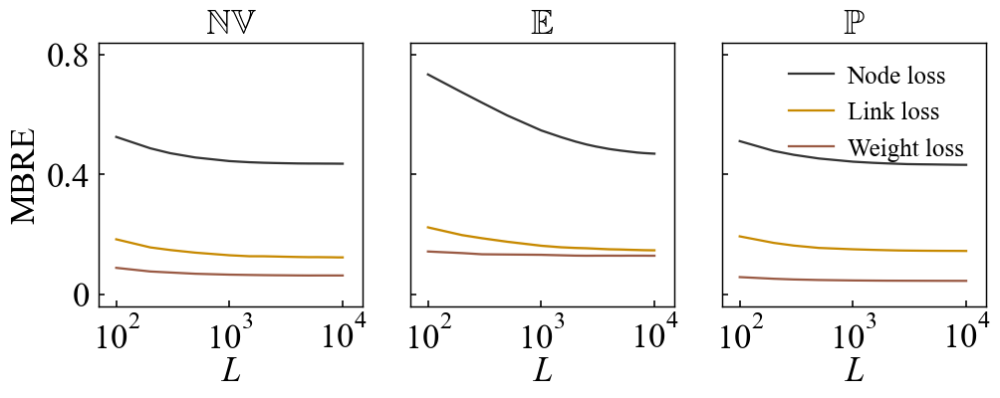

In [ ]:
# Figure SI4 
"""
Response-matrix learning curves for three dynamics

FINAL VERSION
- Dynamics: NV, E, P.
- Perturbations: Node loss, Link loss, Weight loss.
- Shows MBRE versus training-set size L.
- Uses x####.mat for training and X_test.mat for testing.
- Saves the figure as "Figure SI4.svg" and displays it.
"""

from __future__ import annotations

import itertools
import os
import re
import warnings
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import t as student_t


# ============================================================================
# 1. EDITABLE SETTINGS
# ============================================================================

BASE_PATH = Path(r"F:\NP-real\1Coding\1Main function\compute data")
OUTPUT_SVG = Path("Figure SI4.svg")  # Edit to choose another save location.

# Default three dynamics. Edit this list if a different trio is required.
DYNAMICS = [
    {
        "name": "Noisy voter",
        "symbol": r"$\mathbb{NV}$",
        "folder_prefix": "0.noisy voter_Dolphin social network",
    },
    {
        "name": "Epidemics",
        "symbol": r"$\mathbb{E}$",
        "folder_prefix": "0.Epidemics (SIS)_MIT Reality Mining",
    },
    {
        "name": "Population",
        "symbol": r"$\mathbb{P}$",
        "folder_prefix": "0.Population_Little Rock Lake",
    },
]

PERTURBATIONS = [
    ("Node loss", "_perturbation_type1_test", "#333333"),
    ("Link loss", "_perturbation_type2_test", "#C78900"),
    ("Weight loss", "_perturbation_type3_test", "#9A5A44"),
]

TRAIN_SIZES = np.array(
    [100, 200, 300, 500, 1000, 1500, 2000, 2500,
     3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000],
    dtype=int,
)

PINV_REL_TOL = 1e-10
MAX_Y = 0.8                   # Set to None for automatic common y limits.
TICK_FS = 25
AXIS_LABEL_FS = 25
TITLE_FS = 25
LEGEND_FS = 18
LINEWIDTH = 1.62

# Fixed Figure SI5 geometry: three square panels with inch-based margins.
PANEL_SIDE = 2.65
COL_GAP = 0.48
LEFT_MARGIN = 1.75
RIGHT_MARGIN = 0.30
TOP_MARGIN = 0.55
BOTTOM_MARGIN = 1.00
FIG_W = LEFT_MARGIN + len(DYNAMICS) * PANEL_SIDE + (len(DYNAMICS) - 1) * COL_GAP + RIGHT_MARGIN
FIG_H = BOTTOM_MARGIN + PANEL_SIDE + TOP_MARGIN

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "axes.linewidth": 1.10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "svg.fonttype": "none",
})

# This follows the Figure 3 symbol route. When MiKTeX is available, the
# requested blackboard-bold dynamics symbols render upright as \mathbb{NV},
# \mathbb{E}, and \mathbb{P}; otherwise STIX mathtext is used as a fallback.
MIKTEX_BIN = Path(r"D:\Users\xuren\AppData\Local\Programs\MiKTeX\miktex\bin\x64")
LATEX_EXE = MIKTEX_BIN / "latex.exe"
USE_REAL_LATEX = LATEX_EXE.exists()
if USE_REAL_LATEX:
    os.environ["PATH"] = str(MIKTEX_BIN) + os.pathsep + os.environ.get("PATH", "")
    plt.rcParams["text.latex.preamble"] = r"\usepackage{amsmath,amssymb,bm}"
else:
    warnings.warn(
        "MiKTeX latex.exe was not found; using the STIX mathtext fallback "
        "for upright blackboard-bold dynamics symbols."
    )
    plt.rcParams["mathtext.fontset"] = "stix"


# ============================================================================
# 2. MATLAB FILE HELPERS
# ============================================================================

def _read_hdf5_numeric(dataset):
    arr = np.asarray(dataset)
    if arr.dtype.fields is not None:
        fields = arr.dtype.fields
        if "real" in fields and "imag" in fields:
            arr = arr["real"] + 1j * arr["imag"]
    if arr.ndim >= 2:
        arr = np.transpose(arr, tuple(range(arr.ndim - 1, -1, -1)))
    return np.asarray(arr)


def load_mat_variable(path: Path, variable: str):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"File not found:\n{path}")
    if h5py.is_hdf5(path):
        with h5py.File(path, "r") as handle:
            if variable not in handle:
                raise KeyError(
                    f"Variable {variable!r} not found in {path}. "
                    f"Available: {list(handle.keys())}"
                )
            return _read_hdf5_numeric(handle[variable])
    data = loadmat(path)
    if variable not in data:
        raise KeyError(
            f"Variable {variable!r} not found in {path}. "
            f"Available: {[k for k in data if not k.startswith('__')]}"
        )
    return np.asarray(data[variable])


def load_preferred_or_first(path: Path, preferred: str):
    try:
        return load_mat_variable(path, preferred)
    except KeyError:
        if h5py.is_hdf5(path):
            with h5py.File(path, "r") as handle:
                keys = [k for k in handle if isinstance(handle[k], h5py.Dataset)]
                if not keys:
                    raise ValueError(f"No numeric dataset found in {path}")
                warnings.warn(f"Using {keys[0]!r} from {path.name}; {preferred!r} was absent.")
                return _read_hdf5_numeric(handle[keys[0]])
        data = loadmat(path)
        keys = [k for k in data if not k.startswith("__")]
        if not keys:
            raise ValueError(f"No usable variable found in {path}")
        warnings.warn(f"Using {keys[0]!r} from {path.name}; {preferred!r} was absent.")
        return np.asarray(data[keys[0]])


def orient_3d_with_nodes_last(array, n_nodes: int, label: str):
    arr = np.squeeze(np.asarray(array))
    if arr.ndim != 3:
        raise ValueError(f"{label} must be 3D after squeeze; got {arr.shape}")
    candidates = []
    for perm in itertools.permutations(range(3)):
        candidate = np.transpose(arr, perm)
        if candidate.shape[2] == n_nodes:
            candidates.append(candidate)
    if not candidates:
        raise ValueError(f"Cannot orient {label} with {n_nodes} nodes; shape={arr.shape}")
    # Prefer the MATLAB/Python convention [experiment/realization, state, node].
    return candidates[0]


def sorted_training_files(folder: Path):
    pattern = re.compile(r"^x(\d+)\.mat$", re.IGNORECASE)
    indexed = []
    for path in folder.glob("*.mat"):
        match = pattern.match(path.name)
        if match:
            indexed.append((int(match.group(1)), path))
    return [path for _, path in sorted(indexed)]


# ============================================================================
# 3. RESPONSE-MATRIX LEARNING CURVE
# ============================================================================

def pinv_truncated(matrix, rel_tol=PINV_REL_TOL):
    u, singular_values, vh = np.linalg.svd(matrix, full_matrices=False)
    threshold = rel_tol * (singular_values.max() + np.finfo(float).eps)
    inverse_values = np.zeros_like(singular_values)
    keep = singular_values > threshold
    inverse_values[keep] = 1.0 / singular_values[keep]
    if np.count_nonzero(keep) < min(matrix.shape):
        warnings.warn(
            f"Near-singular C00: numerical rank "
            f"{np.count_nonzero(keep)}/{min(matrix.shape)}."
        )
    return (vh.T * inverse_values) @ u.T


def prepare_test_data(folder: Path, n_nodes: int, expected_p: int):
    raw = load_preferred_or_first(folder / "X_test.mat", "X_test")
    data = orient_3d_with_nodes_last(raw, n_nodes, "X_test")

    # Original convention:
    # data[:,0,:] = initial state; data[:,1,:] = intact state;
    # data[:,2:,:] = perturbed states.
    # Prediction inputs remove the intact state, while observations remove x0.
    prediction_data = np.delete(data, 1, axis=1)
    x0_test = prediction_data[:, 0, :]
    observed = np.delete(data, 0, axis=1)

    if observed.shape[1] != expected_p:
        raise ValueError(
            f"{folder.name}: training has P={expected_p}, but prepared "
            f"test observations have P={observed.shape[1]}."
        )
    return np.asarray(x0_test, float), np.asarray(observed, float)


def symmetric_vector_auc(predicted, observed):
    difference_norm = np.linalg.norm(predicted - observed, axis=2)
    predicted_norm = np.linalg.norm(predicted, axis=2)
    observed_norm = np.linalg.norm(observed, axis=2)

    finite_scale = np.abs(observed[np.isfinite(observed)])
    eps0 = 1e-8 if finite_scale.size == 0 else 1e-8 * max(1.0, finite_scale.mean())
    error = difference_norm / (predicted_norm + observed_norm + eps0)
    error = np.clip(error, 0.0, 1.0)

    x_values = np.linspace(0.0, 1.0, error.shape[1])
    # Written as an explicit branch for compatibility with notebook parsers.
    # np.trapezoid replaces the deprecated np.trapz.
    if error.shape[1] == 1:
        auc_each_experiment = error[:, 0]
    else:
        auc_each_experiment = np.trapezoid(
            error, x_values, axis=1
        ) / (x_values[-1] - x_values[0])
    auc_each_experiment = auc_each_experiment[np.isfinite(auc_each_experiment)]
    if auc_each_experiment.size == 0:
        return np.nan, np.nan

    mean_error = float(np.mean(auc_each_experiment))
    if auc_each_experiment.size == 1:
        return mean_error, 0.0
    sem = np.std(auc_each_experiment, ddof=1) / np.sqrt(auc_each_experiment.size)
    ci_half_width = float(student_t.ppf(0.975, auc_each_experiment.size - 1) * sem)
    return mean_error, ci_half_width


def compute_case_learning_curve(folder: Path):
    files = sorted_training_files(folder)
    if not files:
        raise FileNotFoundError(f"No training files x####.mat found in:\n{folder}")

    first_x0 = np.asarray(load_mat_variable(files[0], "x0"), float).reshape(-1)
    n_nodes = first_x0.size
    first_outputs = orient_3d_with_nodes_last(
        load_mat_variable(files[0], "outputs"), n_nodes, "outputs"
    )
    realizations_per_file, n_perturbations, _ = first_outputs.shape
    max_realizations = len(files) * realizations_per_file
    valid_sizes = TRAIN_SIZES[TRAIN_SIZES <= max_realizations]
    if valid_sizes.size == 0:
        raise ValueError(
            f"{folder.name}: only {max_realizations} realizations are available; "
            f"the smallest requested size is {TRAIN_SIZES.min()}."
        )

    x0_test, observed = prepare_test_data(folder, n_nodes, n_perturbations)
    means, cis = [], []

    for training_size in valid_sizes:
        c00_sum = np.zeros((n_nodes, n_nodes), dtype=float)
        cp0_sum = np.zeros((n_perturbations, n_nodes, n_nodes), dtype=float)

        q_base, remainder = divmod(int(training_size), len(files))
        for file_index, path in enumerate(files):
            q_this_file = q_base + (1 if file_index < remainder else 0)
            if q_this_file == 0:
                continue

            x0 = np.asarray(load_mat_variable(path, "x0"), float).reshape(-1)
            outputs = orient_3d_with_nodes_last(
                load_mat_variable(path, "outputs"), n_nodes, f"{path.name}: outputs"
            )
            if q_this_file > outputs.shape[0]:
                raise ValueError(
                    f"{path.name}: requested {q_this_file} realizations, "
                    f"but only {outputs.shape[0]} are available."
                )

            c00_sum += q_this_file * np.outer(x0, x0)
            output_sum = np.sum(outputs[:q_this_file], axis=0)  # P x N
            cp0_sum += output_sum[:, :, None] * x0[None, None, :]

        c00_inverse = pinv_truncated(c00_sum / training_size)
        response_matrices = (cp0_sum / training_size) @ c00_inverse

        # predicted shape: experiments x perturbations x nodes
        predicted = np.einsum("pnm,em->epn", response_matrices, x0_test)
        mean_error, ci = symmetric_vector_auc(predicted, observed)
        means.append(mean_error)
        cis.append(ci)
        print(
            f"  {folder.name} | L={training_size:5d} | "
            f"error={mean_error:.6g} | 95% CI half-width={ci:.6g}"
        )

        del c00_sum, cp0_sum, c00_inverse, response_matrices, predicted

    return valid_sizes, np.asarray(means), np.asarray(cis)


# ============================================================================
# 4. COMPUTE IN MEMORY AND DISPLAY ONLY
# ============================================================================

all_results = []
for dynamics in DYNAMICS:
    dynamics_results = []
    print("\n" + "=" * 80)
    print(dynamics["name"])
    print("=" * 80)
    for perturbation_name, suffix, color in PERTURBATIONS:
        case_folder = BASE_PATH / f'{dynamics["folder_prefix"]}{suffix}'
        sizes, mean_error, ci = compute_case_learning_curve(case_folder)
        dynamics_results.append({
            "name": perturbation_name,
            "color": color,
            "sizes": sizes,
            "mean": mean_error,
            "ci": ci,
        })
    all_results.append(dynamics_results)


fig = plt.figure(figsize=(FIG_W, FIG_H), facecolor="none")


def inch_box(left_inches, bottom_inches, width_inches, height_inches):
    return [
        left_inches / FIG_W,
        bottom_inches / FIG_H,
        width_inches / FIG_W,
        height_inches / FIG_H,
    ]


axes = []
for column in range(len(DYNAMICS)):
    left = LEFT_MARGIN + column * (PANEL_SIDE + COL_GAP)
    axes.append(fig.add_axes(inch_box(left, BOTTOM_MARGIN, PANEL_SIDE, PANEL_SIDE)))

for axis, dynamics, results in zip(axes, DYNAMICS, all_results):
    axis.set_facecolor("none")
    for result in results:
        lower = np.clip(result["mean"] - result["ci"], 0, 1)
        upper = np.clip(result["mean"] + result["ci"], 0, 1)
        axis.fill_between(
            result["sizes"], lower, upper,
            color=result["color"], alpha=0.14, linewidth=0,
        )
        axis.plot(
            result["sizes"], result["mean"],
            color=result["color"], linewidth=LINEWIDTH,
            linestyle="-", marker=None,
            label=result["name"],
        )

    axis.set_xscale("log")
    # Visual whitespace is retained on both sides of the first/last tick.
    axis.set_xlim(70, 15000)
    axis.set_xticks([100, 1000, 10000])
    axis.set_xticklabels([r"$10^2$", r"$10^3$", r"$10^4$"], fontsize=TICK_FS)
    axis.set_xlabel(r"$L$", fontsize=AXIS_LABEL_FS, labelpad=1.0)
    axis.set_title(
        dynamics["symbol"],
        fontsize=TITLE_FS,
        pad=6.5,
        fontstyle="normal",
        fontweight="normal",
        usetex=USE_REAL_LATEX,
    )
    axis.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=4.5,
        width=1.15,
        labelsize=TICK_FS,
        pad=6.5,
    )
    axis.minorticks_off()
    axis.grid(False)
    for spine in axis.spines.values():
        spine.set_linewidth(1.05)
    axis.set_box_aspect(1)
    if MAX_Y is not None:
        y_ticks = np.linspace(0.0, MAX_Y, 3)
        y_margin = 0.05 * (y_ticks[-1] - y_ticks[0])
        axis.set_ylim(y_ticks[0] - y_margin, y_ticks[-1] + y_margin)
        axis.set_yticks(y_ticks)
        axis.set_yticklabels([f"{tick:g}" for tick in y_ticks], fontsize=TICK_FS)
    for label in axis.get_xticklabels() + axis.get_yticklabels():
        label.set_fontname("Times New Roman")
        label.set_fontsize(TICK_FS)

axes[0].set_ylabel("MBRE", fontsize=AXIS_LABEL_FS, labelpad=4.0)
for axis in axes[1:]:
    axis.tick_params(axis="y", labelleft=False)

axes[-1].legend(
    frameon=False,
    fontsize=LEGEND_FS,
    loc="upper right",
    handlelength=1.8,
    handletextpad=0.55,
)

fig.savefig(
    OUTPUT_SVG,
    format="svg",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
    facecolor="none",
    edgecolor="none",
)
print(f"Saved: {OUTPUT_SVG.resolve()}")
plt.show()


C:\Users\xuren\AppData\Local\Temp\ipykernel_15204\2938433252.py:198: UserWarning: Near-singular C00: numerical rank 100/183; using a truncated-SVD pseudoinverse.
  warnings.warn(


Environmental noise | Node loss: 100 training files, 100 test realizations, 46 perturbation levels
Environmental noise | Link loss: 100 training files, 100 test realizations, 51 perturbation levels
Environmental noise | Weight loss: 100 training files, 100 test realizations, 21 perturbation levels
Demographic noise | Node loss: 100 training files, 100 test realizations, 46 perturbation levels
Demographic noise | Link loss: 100 training files, 100 test realizations, 51 perturbation levels
Demographic noise | Weight loss: 100 training files, 100 test realizations, 21 perturbation levels

Figure SVG saved to:
  F:\NP-real\Figure SI5.svg


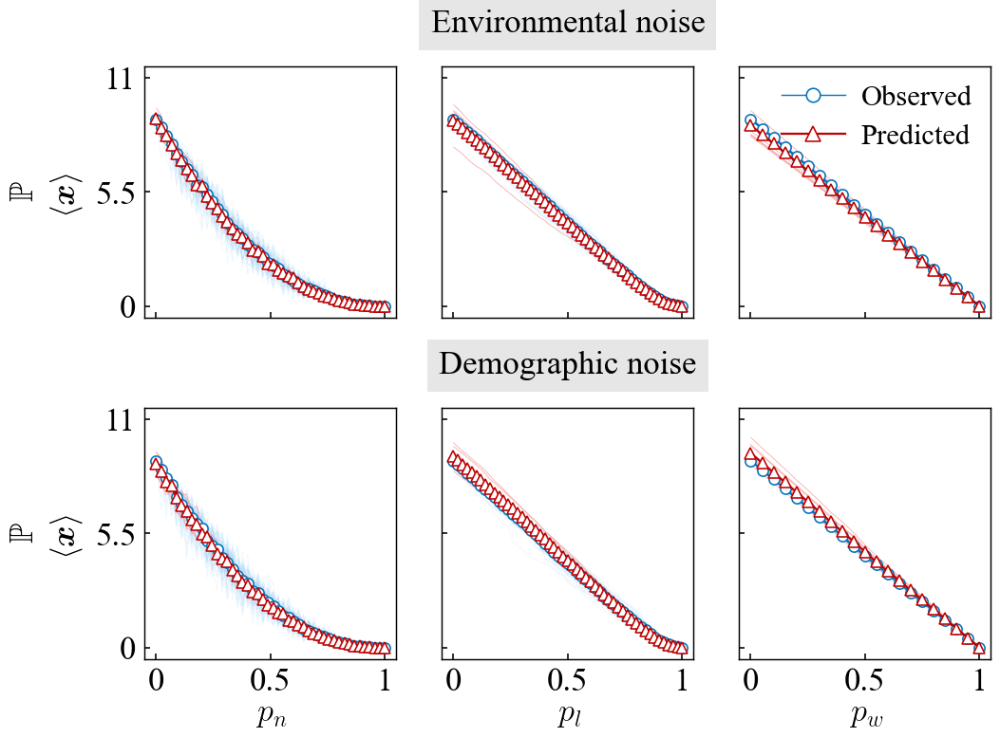

In [4]:
# Figure SI5 
"""
Population dynamics under environmental and demographic noise.

- Rows: Environmental noise and Demographic noise.
- Columns: Node loss, Link loss, and Weight loss.
- The response matrix is estimated from x0*.mat and tested with X_test.mat.
- The transparent-background figure is saved as "Figure SI5.svg" and displayed.
"""

from __future__ import annotations

import os
import warnings
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

from scipy.io import loadmat
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter


# ============================================================
# 1. EDITABLE PATHS / DATA SETTINGS
# ============================================================

BASE_PATH = Path(r"F:\NP-real\1Coding\1Main function")
OUTPUT_SVG = Path.cwd() / "Figure SI5.svg"

# Both folders and the Population folder names follow the supplied directory
# screenshots. Change only these strings if your local names differ.
NOISE_ROWS = [
    {
        "name": "Environmental noise",
        "folder": "compute data_Environmental noise",
    },
    {
        "name": "Demographic noise",
        "folder": "compute data_demographic noise",
    },
]

POPULATION_PREFIX = "6.Population_Little Rock Lake"

PERTURBATIONS = [
    {"suffix": "_perturbation_type1", "title": "Node loss", "xlabel": r"$p_n$"},
    {"suffix": "_perturbation_type2", "title": "Link loss", "xlabel": r"$p_l$"},
    {"suffix": "_perturbation_type3", "title": "Weight loss", "xlabel": r"$p_w$"},
]

# The requested three-tick y-axis style. Each row uses one shared scale for
# its three attack protocols. Set either value to None for automatic ticks.
ROW_TICK_OVERRIDES = {
    "Environmental noise": np.array([0.0, 5.5, 11.0]),
    "Demographic noise": np.array([0.0, 5.5, 11.0]),
}

PINV_REL_TOL = 1e-10


# ============================================================
# 2. FIGURE SI1 TYPOGRAPHY / LINE STYLE (UNCHANGED)
# ============================================================

TICK_FS = 25
AXIS_LABEL_FS = 25
TITLE_FS = 25
LEGEND_FS = 22
ROW_SYMBOL_FS = 25

BLUE = (0.00, 0.45, 0.74)
RED = (0.75, 0.00, 0.00)
BLUE_LIGHT = (0.55, 0.78, 0.95)
RED_LIGHT = (0.96, 0.64, 0.64)

REALIZATION_LINEWIDTH = 0.55
REALIZATION_ALPHA = 0.14
MEAN_LINEWIDTH = 1.62
MARKER_SIZE = 8.1
N_VISIBLE_MARKERS = 5

PANEL_SIDE = 2.65
COL_GAP = 0.48
ROW_GAP = 0.95
LEFT_MARGIN = 1.75
RIGHT_MARGIN = 0.30
TOP_MARGIN = 1.05
BOTTOM_MARGIN = 1.00
LINEAR_X_MARGIN = 0.05
Y_TICK_MARGIN_RATIO = 0.05

N_ROWS = len(NOISE_ROWS)
N_COLS = len(PERTURBATIONS)
FIG_W = LEFT_MARGIN + N_COLS * PANEL_SIDE + (N_COLS - 1) * COL_GAP + RIGHT_MARGIN
FIG_H = BOTTOM_MARGIN + N_ROWS * PANEL_SIDE + (N_ROWS - 1) * ROW_GAP + TOP_MARGIN

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "axes.linewidth": 1.10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "svg.fonttype": "none",
})

MIKTEX_BIN = Path(r"D:\Users\xuren\AppData\Local\Programs\MiKTeX\miktex\bin\x64")
USE_REAL_LATEX = (MIKTEX_BIN / "latex.exe").exists()
if USE_REAL_LATEX:
    os.environ["PATH"] = str(MIKTEX_BIN) + os.pathsep + os.environ.get("PATH", "")
    plt.rcParams["text.latex.preamble"] = r"\usepackage{amsmath,amssymb,bm}"
    MEAN_STATE_LABEL = r"$\langle \bm{x}\rangle$"
else:
    warnings.warn("MiKTeX latex.exe was not found; using Matplotlib mathtext.")
    plt.rcParams["mathtext.fontset"] = "stix"
    MEAN_STATE_LABEL = r"$\langle \mathbf{x}\rangle$"


# ============================================================
# 3. FORMATTERS / MATLAB FILE HELPERS
# ============================================================

def clean_number(value, _position=None):
    if abs(value - round(value)) < 1e-10:
        return f"{int(round(value))}"
    return f"{value:g}"


CLEAN_FORMATTER = FuncFormatter(clean_number)


def is_mat_v73(path: Path) -> bool:
    return h5py.is_hdf5(path)


def _decode_hdf5_numeric_dataset(dataset):
    array = np.asarray(dataset)
    if array.dtype.fields is not None and {"real", "imag"}.issubset(array.dtype.fields):
        array = array["real"] + 1j * array["imag"]
    if array.ndim >= 2:
        array = np.transpose(array, tuple(range(array.ndim - 1, -1, -1)))
    return np.asarray(array)


def load_mat_variable(path: Path, variable: str):
    if not path.exists():
        raise FileNotFoundError(f"File not found:\n{path}")
    if is_mat_v73(path):
        with h5py.File(path, "r") as handle:
            if variable not in handle:
                raise KeyError(f"{variable!r} was not found in {path}; available: {list(handle.keys())}")
            return _decode_hdf5_numeric_dataset(handle[variable])
    data = loadmat(path)
    if variable not in data:
        available = [key for key in data if not key.startswith("__")]
        raise KeyError(f"{variable!r} was not found in {path}; available: {available}")
    return np.asarray(data[variable])


def load_preferred_or_first(path: Path, preferred: str):
    try:
        return load_mat_variable(path, preferred)
    except KeyError:
        if is_mat_v73(path):
            with h5py.File(path, "r") as handle:
                keys = [key for key in handle.keys() if not key.startswith("#")]
                if not keys:
                    raise ValueError(f"No numeric variable found in {path}")
                warnings.warn(f"Using {keys[0]!r} from {path.name}; {preferred!r} is absent.")
                return _decode_hdf5_numeric_dataset(handle[keys[0]])
        data = loadmat(path)
        keys = [key for key in data if not key.startswith("__")]
        if not keys:
            raise ValueError(f"No numeric variable found in {path}")
        warnings.warn(f"Using {keys[0]!r} from {path.name}; {preferred!r} is absent.")
        return np.asarray(data[keys[0]])


# ============================================================
# 4. RESPONSE-MATRIX PREDICTION (IN MEMORY ONLY)
# ============================================================

def pinv_truncated(matrix, relative_tolerance=PINV_REL_TOL):
    u, singular_values, vh = np.linalg.svd(matrix, full_matrices=False)
    threshold = relative_tolerance * (singular_values.max() + np.finfo(float).eps)
    reciprocal = np.zeros_like(singular_values)
    keep = singular_values > threshold
    reciprocal[keep] = 1.0 / singular_values[keep]
    if np.count_nonzero(keep) < min(matrix.shape):
        warnings.warn(
            f"Near-singular C00: numerical rank {np.count_nonzero(keep)}/{min(matrix.shape)}; "
            "using a truncated-SVD pseudoinverse."
        )
    return (vh.T * reciprocal) @ u.T


def process_case(folder: Path, case_name: str):
    """Compute observed and RM-predicted global states without saving R_p/X_p."""
    if not folder.exists():
        raise FileNotFoundError(f"Folder not found:\n{folder}")

    training_files = sorted(folder.glob("x0*.mat"), key=lambda path: path.name)
    if not training_files:
        raise FileNotFoundError(f"No x0*.mat training files found in:\n{folder}")

    first_outputs = np.asarray(load_mat_variable(training_files[0], "outputs"))
    if first_outputs.ndim != 3:
        raise ValueError(f"{training_files[0].name}: outputs must be 3D, not {first_outputs.shape}")
    _, n_perturbations, n_nodes = first_outputs.shape

    n_training = len(training_files)
    initial_states = np.empty((n_training, n_nodes), dtype=float)
    mean_training_outputs = np.empty((n_training, n_perturbations, n_nodes), dtype=float)

    for index, path in enumerate(training_files):
        outputs = np.asarray(load_mat_variable(path, "outputs"), dtype=float)
        initial_state = np.asarray(load_mat_variable(path, "x0"), dtype=float).reshape(-1)
        if outputs.ndim != 3 or outputs.shape[1:] != (n_perturbations, n_nodes):
            raise ValueError(f"Unexpected outputs shape in {path.name}: {outputs.shape}")
        if initial_state.size != n_nodes:
            raise ValueError(f"Unexpected x0 length in {path.name}: {initial_state.size}; expected {n_nodes}")
        initial_states[index] = initial_state
        mean_training_outputs[index] = outputs.mean(axis=0)

    covariance_00 = initial_states.T @ initial_states / n_training
    covariance_00_inverse = pinv_truncated(covariance_00)
    response_matrices = np.empty((n_perturbations, n_nodes, n_nodes), dtype=float)
    for perturbation_index in range(n_perturbations):
        covariance_p0 = (
            mean_training_outputs[:, perturbation_index, :].T @ initial_states / n_training
        )
        response_matrices[perturbation_index] = covariance_p0 @ covariance_00_inverse

    test_data = np.asarray(
        load_preferred_or_first(folder / "X_test.mat", "X_test"), dtype=float
    )
    if test_data.ndim != 3:
        raise ValueError(f"{case_name}: X_test must be 3D, not {test_data.shape}")

    # X_test convention: [x0, intact state, perturbation levels] along axis 1.
    prediction_data = np.delete(test_data, 1, axis=1)
    initial_test_states = prediction_data[:, 0, :]
    observed_states = np.delete(test_data, 0, axis=1)
    if observed_states.shape[1:] != (n_perturbations, n_nodes):
        raise ValueError(
            f"{case_name}: test shape after preparation is {observed_states.shape}; "
            f"expected (*, {n_perturbations}, {n_nodes})."
        )

    predicted_states = np.einsum("pnm,em->epn", response_matrices, initial_test_states)
    observed_by_realization = observed_states.mean(axis=2)
    predicted_by_realization = predicted_states.mean(axis=2)
    x_values = np.linspace(0.0, 1.0, n_perturbations)

    print(
        f"{case_name}: {n_training} training files, "
        f"{observed_states.shape[0]} test realizations, {n_perturbations} perturbation levels"
    )
    return {
        "x": x_values,
        "observed_by_realization": observed_by_realization,
        "predicted_by_realization": predicted_by_realization,
        "observed_mean": observed_by_realization.mean(axis=0),
        "predicted_mean": predicted_by_realization.mean(axis=0),
    }


# ============================================================
# 5. LOAD / COMPUTE SIX CASES
# ============================================================

all_data = []
for noise_row in NOISE_ROWS:
    row_data = []
    for perturbation in PERTURBATIONS:
        case_folder = BASE_PATH / noise_row["folder"] / (POPULATION_PREFIX + perturbation["suffix"])
        case_name = f"{noise_row['name']} | {perturbation['title']}"
        row_data.append(process_case(case_folder, case_name))
    all_data.append(row_data)


# ============================================================
# 6. ONE SHARED THREE-TICK Y SCALE WITHIN EACH NOISE ROW
# ============================================================

def automatic_three_ticks(values):
    finite = np.asarray(values, dtype=float)
    finite = finite[np.isfinite(finite)]
    if finite.size == 0:
        return np.array([0.0, 0.5, 1.0])
    upper = float(np.max(finite))
    upper = max(upper, np.finfo(float).eps)
    return np.array([0.0, 0.5 * upper, upper])


row_y_settings = []
for noise_row, row_data in zip(NOISE_ROWS, all_data):
    values = np.concatenate([
        np.ravel(case["observed_by_realization"]) for case in row_data
    ] + [
        np.ravel(case["predicted_by_realization"]) for case in row_data
    ])
    ticks = ROW_TICK_OVERRIDES.get(noise_row["name"])
    ticks = automatic_three_ticks(values) if ticks is None else np.asarray(ticks, dtype=float)
    if ticks.size != 3 or np.any(~np.isfinite(ticks)) or not np.all(np.diff(ticks) > 0):
        raise ValueError(f"{noise_row['name']}: y ticks must be three increasing finite values.")
    y_padding = Y_TICK_MARGIN_RATIO * (ticks[-1] - ticks[0])
    row_y_settings.append({"ticks": ticks, "ylim": (ticks[0] - y_padding, ticks[-1] + y_padding)})


# ============================================================
# 7. PLOT: FIGURE SI1 AXIS / LEGEND / LINE SETTINGS
# ============================================================

def inch_box(left_inches, bottom_inches, width_inches, height_inches):
    return [
        left_inches / FIG_W,
        bottom_inches / FIG_H,
        width_inches / FIG_W,
        height_inches / FIG_H,
    ]


def style_axis(axis):
    axis.tick_params(
        axis="both", which="major", direction="in", length=4.5, width=1.15,
        labelsize=TICK_FS, pad=6.5,
    )
    axis.minorticks_off()
    for label in axis.get_xticklabels() + axis.get_yticklabels():
        label.set_fontname("Times New Roman")
        label.set_fontsize(TICK_FS)
    for spine in axis.spines.values():
        spine.set_linewidth(1.05)
    axis.set_box_aspect(1)


fig = plt.figure(figsize=(FIG_W, FIG_H), facecolor="none")
axes = [[None for _ in range(N_COLS)] for _ in range(N_ROWS)]
for row in range(N_ROWS):
    bottom = BOTTOM_MARGIN + (N_ROWS - 1 - row) * (PANEL_SIDE + ROW_GAP)
    for col in range(N_COLS):
        left = LEFT_MARGIN + col * (PANEL_SIDE + COL_GAP)
        axes[row][col] = fig.add_axes(inch_box(left, bottom, PANEL_SIDE, PANEL_SIDE))

for row, (noise_row, row_data, y_setting) in enumerate(zip(NOISE_ROWS, all_data, row_y_settings)):
    for col, (perturbation, data) in enumerate(zip(PERTURBATIONS, row_data)):
        axis = axes[row][col]
        axis.set_facecolor("none")
        x_values = data["x"]
        observed_each = data["observed_by_realization"]
        predicted_each = data["predicted_by_realization"]

        axis.add_collection(LineCollection(
            [np.column_stack((x_values, values)) for values in observed_each],
            colors=[BLUE_LIGHT], linewidths=REALIZATION_LINEWIDTH,
            alpha=REALIZATION_ALPHA, zorder=1, rasterized=True,
        ))
        axis.add_collection(LineCollection(
            [np.column_stack((x_values, values)) for values in predicted_each],
            colors=[RED_LIGHT], linewidths=REALIZATION_LINEWIDTH,
            alpha=REALIZATION_ALPHA, zorder=1, rasterized=True,
        ))

        marker_indices = sorted({
            int(np.argmin(np.abs(x_values - target)))
            for target in np.linspace(0.0, 1.0, N_VISIBLE_MARKERS)
        })
        axis.plot(
            x_values, data["observed_mean"], color=BLUE, linestyle="-",
            linewidth=MEAN_LINEWIDTH, marker="o", markevery=1,
            markersize=MARKER_SIZE, markerfacecolor="white", markeredgecolor=BLUE,
            markeredgewidth=1.15, zorder=4,
        )
        axis.plot(
            x_values, data["predicted_mean"], color=RED, linestyle="-",
            linewidth=MEAN_LINEWIDTH, marker="^", markevery=1,
            markersize=MARKER_SIZE, markerfacecolor="white", markeredgecolor=RED,
            markeredgewidth=1.15, zorder=5,
        )

        axis.set_xlim(-LINEAR_X_MARGIN, 1.0 + LINEAR_X_MARGIN)
        axis.set_xticks([0.0, 0.5, 1.0])
        axis.xaxis.set_major_formatter(CLEAN_FORMATTER)
        if row == 0:
            # The upper row intentionally retains x tick marks only.
            axis.tick_params(axis="x", labelbottom=False)
        else:
            axis.set_xlabel(
                perturbation["xlabel"],
                fontsize=AXIS_LABEL_FS,
                labelpad=1.0,
                usetex=USE_REAL_LATEX,
            )

        axis.set_ylim(y_setting["ylim"])
        axis.set_yticks(y_setting["ticks"])
        axis.yaxis.set_major_formatter(CLEAN_FORMATTER)
        style_axis(axis)
        if col > 0:
            axis.tick_params(axis="y", labelleft=False)


# ============================================================
# 8. FIGURE-LEVEL LABELS, ROW HEADERS, AND LEGENDS
# ============================================================

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
left_edges = []
for axis in (axes[0][0], axes[1][0]):
    for tick_label in axis.get_yticklabels():
        if tick_label.get_visible() and tick_label.get_text():
            left_edges.append(tick_label.get_window_extent(renderer=renderer).transformed(fig.transFigure.inverted()).x0)

if not left_edges:
    raise RuntimeError("Could not determine left-side y-tick-label positions.")

mean_label_x = min(left_edges) - 0.028
symbol_label_x = mean_label_x - 0.040

# Centre row headers across the three panels themselves, rather than across
# the full canvas (whose left margin is intentionally wider for y labels).
panel_group_left = axes[0][0].get_position().x0
panel_group_right = axes[0][-1].get_position().x1
panel_group_center_x = 0.5 * (panel_group_left + panel_group_right)

for row, noise_row in enumerate(NOISE_ROWS):
    position = axes[row][0].get_position()
    center_y = position.y0 + position.height / 2.0
    fig.text(symbol_label_x, center_y, r"$\mathbb{P}$", fontsize=ROW_SYMBOL_FS,
             ha="center", va="center", rotation=90, usetex=USE_REAL_LATEX,
             fontname="Times New Roman")
    fig.text(mean_label_x, center_y, MEAN_STATE_LABEL, fontsize=AXIS_LABEL_FS,
             ha="center", va="center", rotation=90, usetex=USE_REAL_LATEX,
             fontname="Times New Roman")

    # Grey row title strips follow the supplied two-row reference image.
    top_y = position.y1 + 0.035
    fig.text(
        panel_group_center_x, top_y, noise_row["name"], fontsize=TITLE_FS,
        ha="center", va="bottom", fontname="Times New Roman",
        bbox={"boxstyle": "square,pad=0.35", "facecolor": "#E6E6E6", "edgecolor": "none"},
    )

legend_handles = [
    Line2D([0], [0], color=BLUE, linestyle="-", linewidth=1,
           marker="o", markerfacecolor="white", markeredgecolor=BLUE,
           markeredgewidth=1.15, markersize=10.5),
    Line2D([0], [0], color=RED, linestyle="-", linewidth=MEAN_LINEWIDTH,
           marker="^", markerfacecolor="white", markeredgecolor=RED,
           markeredgewidth=1.15, markersize=10.9),
]
legend = axes[0][-1].legend(
    legend_handles, ["Observed", "Predicted"], loc="upper right",
    frameon=False, fontsize=LEGEND_FS, handlelength=2.20,
    handletextpad=0.55, labelspacing=0.42, borderpad=0.15,
)
for text in legend.get_texts():
    text.set_fontname("Times New Roman")
    text.set_fontsize(LEGEND_FS)


# ============================================================
# 9. SAVE TRANSPARENT SVG + SHOW
# ============================================================

fig.savefig(
    OUTPUT_SVG,
    format="svg",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
    facecolor="none",
    edgecolor="none",
)
print(f"\nFigure SVG saved to:\n  {OUTPUT_SVG.resolve()}")
plt.show()



Noisy voter | Node loss
Folder: F:\NP-real\1Coding\1Main function\compute data\4.noisy voter_Dolphin social network_perturbation_type1
Training realizations M = 100
Perturbation levels P   = 62
Nodes N                 = 62
GR mean coefficients: a = -0.166662, b = 0.176748

Noisy voter | Link loss
Folder: F:\NP-real\1Coding\1Main function\compute data\4.noisy voter_Dolphin social network_perturbation_type2
Training realizations M = 100
Perturbation levels P   = 41
Nodes N                 = 62
GR mean coefficients: a = -0.0446953, b = 0.181714

Noisy voter | Weight loss
Folder: F:\NP-real\1Coding\1Main function\compute data\4.noisy voter_Dolphin social network_perturbation_type3
Training realizations M = 100
Perturbation levels P   = 21
Nodes N                 = 62
GR mean coefficients: a = -0.034265, b = 0.185257

Epidemics | Node loss
Folder: F:\NP-real\1Coding\1Main function\compute data\2.Epidemics (SIS)_MIT Reality Mining_perturbation_type1
Training realizations M = 100
Perturbatio

C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\2110869513.py:715: UserWarning: Epidemics: some plotted values lie outside the fixed y-range [-0.07, 1.47]. Data range is [-0.0724073, 1.3365].
  warnings.warn(
C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\2110869513.py:715: UserWarning: Population: some plotted values lie outside the fixed y-range [-0.55, 11.55]. Data range is [-1.5944, 9.9077].
  warnings.warn(
C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\2110869513.py:715: UserWarning: Neuronal: some plotted values lie outside the fixed y-range [-0.4, 8.4]. Data range is [-1.32901, 8.36315].
  warnings.warn(
C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\2110869513.py:715: UserWarning: Regulatory: some plotted values lie outside the fixed y-range [-0.0008, 0.0168]. Data range is [-0.00305379, 0.0137607].
  warnings.warn(
C:\Users\xuren\AppData\Local\Temp\ipykernel_32044\2110869513.py:715: UserWarning: Mutualistic: some plotted values lie outside the fixed y-range [-0.8, 

SVG saved to: f:\NP-real\Figure SI6.svg
SVG saved to: f:\NP-real\Figure SI7.svg

Finished all 21 panels.
Dynamics: NV, E, P, B, N, R, M
Displayed: Observed + GR + DM + full response-matrix prediction
Individual realizations = light solid lines
Mean curves = dark solid lines
All curves are solid; the full response-matrix prediction is red.
SVG saved to: f:\NP-real\Figure SI6.svg
SVG saved to: f:\NP-real\Figure SI7.svg


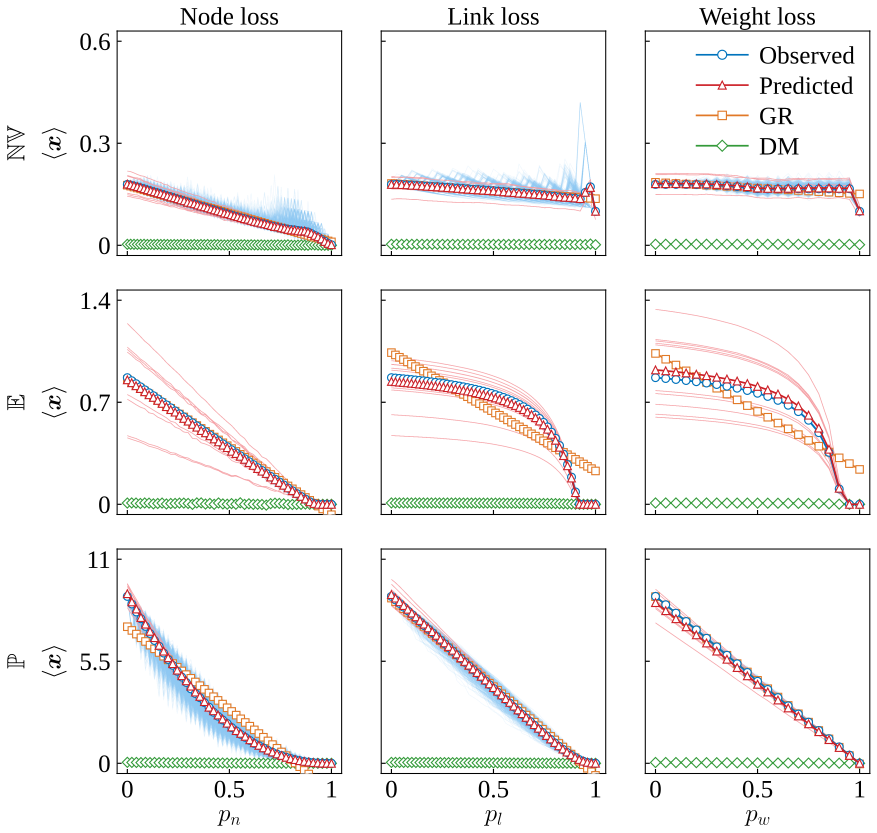

In [1]:
# Figure SI6-7
"""
Benchmark figure: Observed + GR + DM + full response-matrix prediction for 7 dynamics.

Rows: Noisy voter (NV), Epidemics (E), Population (P), Biochemical (B), Neuronal (N), Regulatory (R), Mutualistic (M).
Columns: Node loss, Link loss, Weight loss.

Each panel shows observed test outcomes, global regression (GR), diagonal map (DM), and the full response-matrix prediction (Predicted).
Individual realizations are shown as light-colored thin solid lines; mean curves are shown as corresponding dark solid lines. All curves are solid.

GR is the regression of the global observable on perturbation level. DM uses only the diagonal elements of the response matrix. The full response-matrix prediction uses all matrix elements.

The same x0*.mat training files are used as in the original response-matrix code. X_test.mat is used only for independent testing. The figures are saved as Figure SI6.svg and Figure SI7.svg and displayed in the notebook.
"""
from __future__ import annotations
import os
import warnings
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from matplotlib.ticker import FuncFormatter
from IPython.display import SVG, display
# ============================================================
# 1. PATH
# ============================================================
BASE_PATH = Path(r"F:\NP-real\1Coding\1Main function\compute data")
# ============================================================
# 2. DYNAMICS / PERTURBATIONS
# ============================================================
DYNAMICS = [
    {
        "name": "Noisy voter",
        "symbol": r"$\mathbb{NV}$",
        "folder_prefix": "4.noisy voter_Dolphin social network",
        "yticks": [0.0, 0.30, 0.60],
        "scale_power": None,
    },
    {
        "name": "Epidemics",
        "symbol": r"$\mathbb{E}$",
        "folder_prefix": "2.Epidemics (SIS)_MIT Reality Mining",
        "yticks": [0.0, 0.70, 1.40],
        "scale_power": None,
    },
    {
        "name": "Population",
        "symbol": r"$\mathbb{P}$",
        "folder_prefix": "6.Population_Little Rock Lake",
        "yticks": [0.0, 5.5, 11.0],
        "scale_power": None,
    },
    {
        "name": "Biochemical",
        "symbol": r"$\mathbb{B}$",
        "folder_prefix": "8.Biochemical_Mycoplasma genitalium",
        "yticks": [0.0, 3.0, 6.0],
        "scale_power": None,
    },
    {
        "name": "Neuronal",
        "symbol": r"$\mathbb{N}$",
        "folder_prefix": "7.Neuronal_C elegansCJ",
        "yticks": [0.0, 4.0, 8.0],
        "scale_power": None,
    },
    {
        "name": "Regulatory",
        "symbol": r"$\mathbb{R}$",
        "folder_prefix": "5.Regulatory_ Escherichia coli25",
        # Actual numerical values are 0, 0.008, 0.016.
        # They are displayed as 0, 8, 16 with x10^-3.
        "yticks": [0.0, 8.0e-3, 16.0e-3],
        "scale_power": -3,
    },
    {
        "name": "Mutualistic",
        "symbol": r"$\mathbb{M}$",
        "folder_prefix": "1.Mutualistic_Coral Reefs",
        "yticks": [0.0, 8.0, 16.0],
        "scale_power": None,
    },
]
PERTURBATIONS = [
    {
        "suffix": "_perturbation_type1",
        "title": "Node loss",
        "xlabel": r"$p_n$",
    },
    {
        "suffix": "_perturbation_type2",
        "title": "Link loss",
        "xlabel": r"$p_l$",
    },
    {
        "suffix": "_perturbation_type3",
        "title": "Weight loss",
        "xlabel": r"$p_w$",
    },
]
# ============================================================
# 3. NUMERICAL SETTINGS
# ============================================================
PINV_REL_TOL = 1e-10
# ============================================================
# 4. FONT / STYLE
# ============================================================
TICK_FS = 25
AXIS_LABEL_FS = 25
TITLE_FS = 25
LEGEND_FS = 25
ROW_SYMBOL_FS = 25
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "axes.linewidth": 1.10,
    "xtick.direction": "in",
    "ytick.direction": "in",
})
plt.rcParams["svg.fonttype"] = "none"
MIKTEX_BIN = Path(
    r"D:\Users\xuren\AppData\Local\Programs\MiKTeX\miktex\bin\x64"
)
LATEX_EXE = MIKTEX_BIN / "latex.exe"
USE_REAL_LATEX = LATEX_EXE.exists()
if USE_REAL_LATEX:
    os.environ["PATH"] = (
        str(MIKTEX_BIN)
        + os.pathsep
        + os.environ.get("PATH", "")
    )
    plt.rcParams["text.latex.preamble"] = (
        r"\usepackage{amsmath,amssymb,bm}"
    )
    MEAN_STATE_LABEL = r"$\langle \bm{x}\rangle$"
else:
    MEAN_STATE_LABEL = r"$\langle \mathbf{x}\rangle$"
# ============================================================
# 5. COLORS / LINES / MARKERS
#    FULL RESPONSE MATRIX PREDICTION IS RED; ALL LINES ARE SOLID
# ============================================================
# Observed: blue
OBS_DARK = (0.00, 0.45, 0.74)
OBS_LIGHT = (0.55, 0.78, 0.95)
# Global regression: gray
GR_DARK = "#e17927"
GR_LIGHT = "#f3c9a9"
# Diagonal map: purple
DM_DARK = "#339a39"
DM_LIGHT = "#accc8a"
# Full response-matrix prediction: red
RM_DARK = (0.80, 0.12, 0.15)
RM_LIGHT = (0.96, 0.62, 0.64)
REALIZATION_LW = 0.55
REALIZATION_ALPHA = 0.15
MEAN_LW = 1.70
MARKER_SIZE = 7.8
N_VISIBLE_MARKERS = 5
# ============================================================
# 6. FIGURE GEOMETRY
# ============================================================
PANEL_SIDE = 3.12
COL_GAP = 0.55
ROW_GAP = 0.48
LEFT_MARGIN = 1.70
RIGHT_MARGIN = 0.32
TOP_MARGIN = 0.58
BOTTOM_MARGIN = 0.95
LINEAR_X_MARGIN = 0.05
Y_TICK_MARGIN_RATIO = 0.05
# ============================================================
# 7. FORMATTERS
# ============================================================
def clean_number(x, pos=None):
    if abs(x - round(x)) < 1e-10:
        return f"{int(round(x))}"
    return f"{x:g}"
CLEAN_FORMATTER = FuncFormatter(clean_number)
def use_inside_scientific(
    ax,
    axis="y",
    power=-3,
    position="upper left",
):
    """Scientific-notation formatting copied from Figure SI1."""
    scale = 10.0 ** power
    formatter = FuncFormatter(
        lambda value, pos: clean_number(value / scale)
    )
    if axis == "x":
        ax.xaxis.set_major_formatter(formatter)
    elif axis == "y":
        ax.yaxis.set_major_formatter(formatter)
    else:
        raise ValueError("axis must be 'x' or 'y'")
    positions = {
        "upper left":  (0.035, 0.955, "left",  "top"),
        "upper right": (0.965, 0.955, "right", "top"),
        "lower left":  (0.035, 0.045, "left",  "bottom"),
        "lower right": (0.965, 0.045, "right", "bottom"),
    }
    x_text, y_text, ha, va = positions[position]
    ax.text(
        x_text,
        y_text,
        rf"$\times 10^{{{power}}}$",
        transform=ax.transAxes,
        ha=ha,
        va=va,
        fontsize=TICK_FS - 2,
        fontname="Times New Roman",
        zorder=20,
    )
# ============================================================
# 8. MATLAB FILE HELPERS
# ============================================================
def is_mat_v73(path: Path) -> bool:
    try:
        return h5py.is_hdf5(path)
    except Exception:
        return False
def _decode_hdf5_numeric_dataset(dataset):
    arr = np.asarray(dataset)
    if arr.dtype.fields is not None:
        fields = arr.dtype.fields.keys()
        if "real" in fields and "imag" in fields:
            arr = arr["real"] + 1j * arr["imag"]
    if arr.ndim >= 2:
        arr = np.transpose(
            arr,
            axes=tuple(range(arr.ndim - 1, -1, -1)),
        )
    return np.asarray(arr)
def load_mat_variable(path: Path, variable: str):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"File not found:\n{path}")
    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            if variable not in f:
                raise KeyError(
                    f"Variable '{variable}' not found in:\n{path}\n"
                    f"Available variables: {list(f.keys())}"
                )
            obj = f[variable]
            if not isinstance(obj, h5py.Dataset):
                raise TypeError(
                    f"Variable '{variable}' in {path} "
                    "is not a simple numeric HDF5 dataset."
                )
            return _decode_hdf5_numeric_dataset(obj)
    data = loadmat(path)
    if variable not in data:
        available = [
            k for k in data.keys()
            if not k.startswith("__")
        ]
        raise KeyError(
            f"Variable '{variable}' not found in:\n{path}\n"
            f"Available variables: {available}"
        )
    return np.asarray(data[variable])
def load_first_data_variable(path: Path):
    path = Path(path)
    if is_mat_v73(path):
        with h5py.File(path, "r") as f:
            keys = [
                k for k in f.keys()
                if not k.startswith("#")
            ]
            if not keys:
                raise ValueError(
                    f"No usable variables found in:\n{path}"
                )
            return _decode_hdf5_numeric_dataset(
                f[keys[0]]
            )
    data = loadmat(path)
    keys = [
        k for k in data.keys()
        if not k.startswith("__")
    ]
    if not keys:
        raise ValueError(
            f"No usable variables found in:\n{path}"
        )
    return np.asarray(
        data[keys[0]]
    )
# ============================================================
# 9. TRUNCATED-SVD PSEUDOINVERSE
# ============================================================
def pinv_trunc(A, rel_tol=PINV_REL_TOL):
    A = np.asarray(A, dtype=float)
    U, s, Vh = np.linalg.svd(
        A,
        full_matrices=False,
    )
    if s.size == 0:
        return np.zeros_like(A.T)
    tau = rel_tol * (
        float(np.max(s))
        + np.finfo(float).eps
    )
    keep = s > tau
    s_inv = np.zeros_like(s)
    s_inv[keep] = 1.0 / s[keep]
    return (
        Vh.T
        * s_inv
    ) @ U.T
# ============================================================
# 10. PROCESS ONE CASE
# ============================================================
def process_one_case(folder: Path, case_name: str):
    folder = Path(folder)
    print("\n" + "=" * 84)
    print(case_name)
    print(f"Folder: {folder}")
    print("=" * 84)
    if not folder.exists():
        raise FileNotFoundError(
            f"Folder not found:\n{folder}"
        )
    # --------------------------------------------------------
    # 10.1 Training data
    # --------------------------------------------------------
    files = sorted(
        folder.glob("x0*.mat"),
        key=lambda p: p.name,
    )
    M = len(files)
    if M == 0:
        raise FileNotFoundError(
            f"No x0*.mat training files found in:\n{folder}"
        )
    first_outputs = load_mat_variable(
        files[0],
        "outputs",
    )
    if first_outputs.ndim != 3:
        raise ValueError(
            "'outputs' must be a 3D array.\n"
            f"File: {files[0]}\n"
            f"Shape: {first_outputs.shape}"
        )
    _, P, N = first_outputs.shape
    print(f"Training realizations M = {M}")
    print(f"Perturbation levels P   = {P}")
    print(f"Nodes N                 = {N}")
    X0 = np.zeros(
        (M, N),
        dtype=float,
    )
    Xbar = np.zeros(
        (M, P, N),
        dtype=float,
    )
    for m, mat_file in enumerate(files):
        outputs = np.asarray(
            load_mat_variable(
                mat_file,
                "outputs",
            ),
            dtype=float,
        )
        x0 = np.asarray(
            load_mat_variable(
                mat_file,
                "x0",
            ),
            dtype=float,
        ).reshape(-1)
        if outputs.ndim != 3:
            raise ValueError(
                f"'outputs' in {mat_file.name} must be 3D; "
                f"got {outputs.shape}"
            )
        if outputs.shape[1:] != (P, N):
            raise ValueError(
                f"Unexpected outputs shape in {mat_file.name}: "
                f"{outputs.shape}; expected (*, {P}, {N})"
            )
        if x0.size != N:
            raise ValueError(
                f"Unexpected x0 size in {mat_file.name}: "
                f"{x0.size}; expected {N}"
            )
        X0[m, :] = x0
        # Same treatment as the original code:
        # average internal output realizations first.
        Xbar[m, :, :] = np.mean(
            outputs,
            axis=0,
        )
    p_values = np.linspace(
        0.0,
        1.0,
        P,
    )
    # --------------------------------------------------------
    # 10.2 GLOBAL REGRESSION (GR)
    #
    # \\\\\\\<x_p> = a p + b
    #
    # Light curves:
    # one fitted regression for each training realization.
    #
    # Dark curve:
    # mean of the realization-level regression curves.
    # --------------------------------------------------------
    train_global_by_exp = np.mean(
        Xbar,
        axis=2,
    )  # M x P
    gr_by_exp = np.zeros(
        (M, P),
        dtype=float,
    )
    slopes = np.zeros(
        M,
        dtype=float,
    )
    intercepts = np.zeros(
        M,
        dtype=float,
    )
    for m in range(M):
        a_m, b_m = np.polyfit(
            p_values,
            train_global_by_exp[m, :],
            1,
        )
        slopes[m] = a_m
        intercepts[m] = b_m
        gr_by_exp[m, :] = (
            a_m * p_values
            + b_m
        )
    gr_mean = np.mean(
        gr_by_exp,
        axis=0,
    )
    print(
        "GR mean coefficients: "
        f"a = {np.mean(slopes):.6g}, "
        f"b = {np.mean(intercepts):.6g}"
    )
    # --------------------------------------------------------
    # 10.3 FULL RESPONSE MATRICES
    #
    # Used to construct both DM and the full response-matrix prediction.
    # --------------------------------------------------------
    C00 = (
        X0.T @ X0
    ) / M
    C00_pinv = pinv_trunc(
        C00
    )
    R_full = []
    for p_idx in range(P):
        Xp = Xbar[:, p_idx, :]
        Cp0 = (
            Xp.T @ X0
        ) / M
        R_current = (
            Cp0 @ C00_pinv
        )
        R_full.append(
            R_current
        )
    # --------------------------------------------------------
    # 10.4 Construct DM
    # --------------------------------------------------------
    D_maps = []
    for R_current in R_full:
        # DM:
        # retain ONLY the diagonal elements of the full R_p.
        D_current = np.diag(
            np.diag(R_current)
        )
        D_maps.append(
            D_current
        )
    # --------------------------------------------------------
    # 10.5 Independent test data
    # --------------------------------------------------------
    test_file = (
        folder
        / "X_test.mat"
    )
    if not test_file.exists():
        raise FileNotFoundError(
            f"X_test.mat was not found in:\n{folder}"
        )
    try:
        data3D = load_mat_variable(
            test_file,
            "X_test",
        )
    except KeyError:
        data3D = load_first_data_variable(
            test_file
        )
        warnings.warn(
            'Variable "X_test" was not found. '
            "Using the first available variable instead."
        )
    data3D = np.asarray(
        data3D,
        dtype=float,
    )
    if data3D.ndim != 3:
        raise ValueError(
            f"X_test must be 3D. Shape: {data3D.shape}"
        )
    # Original convention:
    # data3D[:, 0, :] = initial state x_0(0)
    # data3D[:, 1, :] = intact state at t
    # data3D[:, 2:, :] = perturbed states
    X0_test = (
        data3D[:, 0, :]
    )
    observed_full = np.delete(
        data3D,
        0,
        axis=1,
    )
    n_test, P_test, N_test = (
        observed_full.shape
    )
    if P_test != P:
        raise ValueError(
            "Perturbation-number mismatch:\n"
            f"training P = {P}\n"
            f"testing P  = {P_test}"
        )
    if N_test != N:
        raise ValueError(
            "Node-number mismatch:\n"
            f"training N = {N}\n"
            f"testing N  = {N_test}"
        )
    # --------------------------------------------------------
    # 10.6 Observed realization curves
    # --------------------------------------------------------
    observed_by_exp = np.mean(
        observed_full,
        axis=2,
    )
    observed_mean = np.mean(
        observed_by_exp,
        axis=0,
    )
    # --------------------------------------------------------
    # 10.7 DM predictions for each independent test realization
    # --------------------------------------------------------
    dm_by_exp = np.zeros(
        (n_test, P),
        dtype=float,
    )
    for p_idx in range(P):
        predicted_nodes = (
            X0_test
            @ D_maps[p_idx].T
        )
        dm_by_exp[:, p_idx] = np.mean(
            predicted_nodes,
            axis=1,
        )
    dm_mean = np.mean(
        dm_by_exp,
        axis=0,
    )
    # Full response-matrix predictions for each independent test realization.
    rm_by_exp = np.zeros(
        (n_test, P),
        dtype=float,
    )
    for p_idx in range(P):
        predicted_nodes = X0_test @ R_full[p_idx].T
        rm_by_exp[:, p_idx] = np.mean(
            predicted_nodes,
            axis=1,
        )
    rm_mean = np.mean(
        rm_by_exp,
        axis=0,
    )
    return {
        "x": p_values,
        "observed_by_exp": np.real_if_close(
            observed_by_exp
        ),
        "observed_mean": np.real_if_close(
            observed_mean
        ),
        "gr_by_exp": np.real_if_close(
            gr_by_exp
        ),
        "gr_mean": np.real_if_close(
            gr_mean
        ),
        "dm_by_exp": np.real_if_close(
            dm_by_exp
        ),
        "dm_mean": np.real_if_close(
            dm_mean
        ),
        "rm_by_exp": np.real_if_close(
            rm_by_exp
        ),
        "rm_mean": np.real_if_close(
            rm_mean
        ),
    }
# ============================================================
# 11. COMPUTE ALL 21 CASES
# ============================================================
ALL_DATA = []
for dynamics in DYNAMICS:
    row_data = []
    for perturbation in PERTURBATIONS:
        folder = (
            BASE_PATH
            / (
                dynamics["folder_prefix"]
                + perturbation["suffix"]
            )
        )
        case_name = (
            f"{dynamics['name']} | "
            f"{perturbation['title']}"
        )
        row_data.append(
            process_one_case(
                folder,
                case_name,
            )
        )
    ALL_DATA.append(
        row_data
    )
# ============================================================
# 12. FIXED Y SETTINGS
# ============================================================
ROW_Y_SETTINGS = []
for row, dynamics in enumerate(DYNAMICS):
    ticks = np.asarray(
        dynamics["yticks"],
        dtype=float,
    )
    tick_min = float(
        np.min(ticks)
    )
    tick_max = float(
        np.max(ticks)
    )
    tick_span = (
        tick_max
        - tick_min
    )
    if tick_span <= 0:
        raise ValueError(
            f"Invalid y ticks for {dynamics['name']}: "
            f"{dynamics['yticks']}"
        )
    y_pad = (
        Y_TICK_MARGIN_RATIO
        * tick_span
    )
    common_ymin = (
        tick_min
        - y_pad
    )
    common_ymax = (
        tick_max
        + y_pad
    )
    # Warn if any plotted values are outside the fixed range.
    all_values = []
    for col in range(len(PERTURBATIONS)):
        data = ALL_DATA[row][col]
        all_values.extend([
            np.asarray(data["observed_by_exp"]).reshape(-1),
            np.asarray(data["gr_by_exp"]).reshape(-1),
            np.asarray(data["dm_by_exp"]).reshape(-1),
            np.asarray(data["rm_by_exp"]).reshape(-1),
        ])
    all_values = np.concatenate(
        all_values
    )
    all_values = all_values[
        np.isfinite(all_values)
    ]
    if all_values.size > 0:
        data_min = float(
            np.min(all_values)
        )
        data_max = float(
            np.max(all_values)
        )
        if (
            data_min < common_ymin
            or data_max > common_ymax
        ):
            warnings.warn(
                f"{dynamics['name']}: some plotted values lie outside "
                f"the fixed y-range [{common_ymin:g}, {common_ymax:g}]. "
                f"Data range is [{data_min:g}, {data_max:g}]."
            )
    ROW_Y_SETTINGS.append({
        "ylim": (
            common_ymin,
            common_ymax,
        ),
        "yticks": ticks,
    })
# ============================================================
# ============================================================
# 13. COMMON AXIS STYLE
# ============================================================
def style_axis(ax):
    ax.tick_params(
        axis="both",
        which="major",
        direction="in",
        length=4.5,
        width=1.15,
        labelsize=TICK_FS,
        pad=6.5,
    )
    ax.minorticks_off()
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontname("Times New Roman")
        label.set_fontsize(TICK_FS)
    for spine in ax.spines.values():
        spine.set_linewidth(1.05)
    ax.set_box_aspect(1)
# ============================================================
# 14. LEGEND HANDLES
# ============================================================
legend_handles = [
    Line2D([0], [0], color=OBS_DARK, linestyle="-", linewidth=MEAN_LW,
           marker="o", markerfacecolor="white", markeredgecolor=OBS_DARK,
           markeredgewidth=1.15, markersize=9.0, label="Observed"),
    Line2D([0], [0], color=RM_DARK, linestyle="-", linewidth=MEAN_LW,
           marker="^", markerfacecolor="white", markeredgecolor=RM_DARK,
           markeredgewidth=1.10, markersize=8.0, label="Predicted"),
    Line2D([0], [0], color=GR_DARK, linestyle="-", linewidth=MEAN_LW,
           marker="s", markerfacecolor="white", markeredgecolor=GR_DARK,
           markeredgewidth=1.10, markersize=8.4, label="GR"),
    Line2D([0], [0], color=DM_DARK, linestyle="-", linewidth=MEAN_LW,
           marker="D", markerfacecolor="white", markeredgecolor=DM_DARK,
           markeredgewidth=1.10, markersize=7.8, label="DM"),
]
# ============================================================
# 15. DRAW ONE INDEPENDENT FIGURE
# ============================================================
def draw_figure(row_indices, output_svg):
    n_rows = len(row_indices)
    n_cols = len(PERTURBATIONS)
    fig_w = (
        LEFT_MARGIN
        + n_cols * PANEL_SIDE
        + (n_cols - 1) * COL_GAP
        + RIGHT_MARGIN
    )
    fig_h = (
        BOTTOM_MARGIN
        + n_rows * PANEL_SIDE
        + (n_rows - 1) * ROW_GAP
        + TOP_MARGIN
    )
    fig = plt.figure(
        figsize=(fig_w, fig_h),
        facecolor="white",
    )
    def inch_box(left_in, bottom_in, width_in, height_in):
        return [
            left_in / fig_w,
            bottom_in / fig_h,
            width_in / fig_w,
            height_in / fig_h,
        ]
    axes = [
        [None for _ in range(n_cols)]
        for _ in range(n_rows)
    ]
    for local_row in range(n_rows):
        bottom = (
            BOTTOM_MARGIN
            + (n_rows - 1 - local_row) * (PANEL_SIDE + ROW_GAP)
        )
        for col in range(n_cols):
            left = (
                LEFT_MARGIN
                + col * (PANEL_SIDE + COL_GAP)
            )
            axes[local_row][col] = fig.add_axes(
                inch_box(
                    left,
                    bottom,
                    PANEL_SIDE,
                    PANEL_SIDE,
                )
            )
    for local_row, global_row in enumerate(row_indices):
        dynamics = DYNAMICS[global_row]
        common_ylim = ROW_Y_SETTINGS[global_row]["ylim"]
        common_yticks = ROW_Y_SETTINGS[global_row]["yticks"]
        scale_power = dynamics["scale_power"]
        for col, perturbation in enumerate(PERTURBATIONS):
            ax = axes[local_row][col]
            data = ALL_DATA[global_row][col]
            x = np.asarray(data["x"])
            realization_sets = [
                (data["observed_by_exp"], OBS_LIGHT),
                (data["rm_by_exp"], RM_LIGHT),
                (data["gr_by_exp"], GR_LIGHT),
                (data["dm_by_exp"], DM_LIGHT),
            ]
            for curves, light_color in realization_sets:
                curves = np.asarray(curves)
                segments = [
                    np.column_stack((x, y))
                    for y in curves
                ]
                ax.add_collection(
                    LineCollection(
                        segments,
                        colors=[light_color],
                        linewidths=REALIZATION_LW,
                        linestyles="solid",
                        alpha=REALIZATION_ALPHA,
                        zorder=2 if light_color == RM_LIGHT else 1,
                        rasterized=True,
                    )
                )
            marker_idx = sorted(
                set(
                    int(
                        np.argmin(
                            np.abs(x - target)
                        )
                    )
                    for target in np.linspace(
                        0.0,
                        1.0,
                        N_VISIBLE_MARKERS,
                    )
                )
            )
            ax.plot(
                x,
                data["observed_mean"],
                color=OBS_DARK,
                linestyle="-",
                linewidth=MEAN_LW,
                marker="o",
                markevery=1,
                markersize=MARKER_SIZE,
                markerfacecolor="white",
                markeredgecolor=OBS_DARK,
                markeredgewidth=1.15,
                zorder=6,
            )
            ax.plot(
                x,
                data["rm_mean"],
                color=RM_DARK,
                linestyle="-",
                linewidth=MEAN_LW,
                marker="^",
                markevery=1,
                markersize=MARKER_SIZE,
                markerfacecolor="white",
                markeredgecolor=RM_DARK,
                markeredgewidth=1.10,
                zorder=20,
            )
            ax.plot(
                x,
                data["gr_mean"],
                color=GR_DARK,
                linestyle="-",
                linewidth=MEAN_LW,
                marker="s",
                markevery=1,
                markersize=MARKER_SIZE - 0.3,
                markerfacecolor="white",
                markeredgecolor=GR_DARK,
                markeredgewidth=1.10,
                zorder=4,
            )
            ax.plot(
                x,
                data["dm_mean"],
                color=DM_DARK,
                linestyle="-",
                linewidth=MEAN_LW,
                marker="D",
                markevery=1,
                markersize=MARKER_SIZE - 0.7,
                markerfacecolor="white",
                markeredgecolor=DM_DARK,
                markeredgewidth=1.10,
                zorder=3,
            )
            ax.set_xlim(
                -LINEAR_X_MARGIN,
                1.0 + LINEAR_X_MARGIN,
            )
            ax.set_xticks([
                0.0,
                0.5,
                1.0,
            ])
            ax.xaxis.set_major_formatter(
                CLEAN_FORMATTER
            )
            if local_row < n_rows - 1:
                ax.tick_params(
                    axis="x",
                    labelbottom=False,
                )
            if local_row == n_rows - 1:
                ax.set_xlabel(
                    perturbation["xlabel"],
                    fontsize=AXIS_LABEL_FS,
                    labelpad=1.0,
                    usetex=USE_REAL_LATEX,
                )
            ax.set_ylim(
                common_ylim
            )
            ax.set_yticks(
                common_yticks
            )
            if scale_power is None:
                ax.yaxis.set_major_formatter(
                    CLEAN_FORMATTER
                )
            else:
                scale = 10.0 ** scale_power
                ax.yaxis.set_major_formatter(
                    FuncFormatter(
                        lambda value, pos, s=scale:
                        clean_number(value / s)
                    )
                )
            style_axis(ax)
            if scale_power is not None and col == 0:
                use_inside_scientific(
                    ax,
                    axis="y",
                    power=scale_power,
                    position="upper left",
                )
            if col > 0:
                ax.tick_params(
                    axis="y",
                    labelleft=False,
                )
            if local_row == 0:
                ax.set_title(
                    perturbation["title"],
                    fontsize=TITLE_FS,
                    pad=6.5,
                    fontname="Times New Roman",
                )
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    tick_left_edges = []
    for local_row in range(n_rows):
        ax_left = axes[local_row][0]
        for tick_label in ax_left.get_yticklabels():
            if not tick_label.get_visible():
                continue
            if tick_label.get_text() == "":
                continue
            bbox_display = tick_label.get_window_extent(
                renderer=renderer
            )
            bbox_figure = bbox_display.transformed(
                fig.transFigure.inverted()
            )
            tick_left_edges.append(
                bbox_figure.x0
            )
    if not tick_left_edges:
        raise RuntimeError(
            "Could not determine the y-tick-label positions."
        )
    leftmost_ytick_x = min(
        tick_left_edges
    )
    mean_state_label_x = (
        leftmost_ytick_x
        - 0.028
    )
    dynamics_label_x = (
        mean_state_label_x
        - 0.040
    )
    for local_row, global_row in enumerate(row_indices):
        dynamics = DYNAMICS[global_row]
        pos = axes[local_row][0].get_position()
        center_y = (
            pos.y0
            + pos.height / 2.0
        )
        fig.text(
            dynamics_label_x,
            center_y,
            dynamics["symbol"],
            fontsize=ROW_SYMBOL_FS,
            ha="center",
            va="center",
            rotation=90,
            usetex=USE_REAL_LATEX,
            fontname="Times New Roman",
        )
        fig.text(
            mean_state_label_x,
            center_y,
            MEAN_STATE_LABEL,
            fontsize=AXIS_LABEL_FS,
            ha="center",
            va="center",
            rotation=90,
            usetex=USE_REAL_LATEX,
            fontname="Times New Roman",
        )
    legend = axes[0][2].legend(
        handles=legend_handles,
        loc="upper right",
        frameon=False,
        fontsize=LEGEND_FS,
        handlelength=2.05,
        handletextpad=0.45,
        labelspacing=0.30,
        borderpad=0.10,
    )
    for text in legend.get_texts():
        text.set_fontname("Times New Roman")
        text.set_fontsize(LEGEND_FS)
    output_svg = Path(output_svg)
    fig.savefig(
        output_svg,
        format="svg",
        dpi=300,
        bbox_inches="tight",
        transparent=True,
        facecolor="none",
        edgecolor="none",
    )
    print(f"SVG saved to: {output_svg}")
    plt.close(fig)
    return output_svg
# ============================================================
# 16. DIRECTLY GENERATE TWO SVG FIGURES
# ============================================================
OUTPUT_SVG_1 = draw_figure(
    row_indices=[0, 1, 2],
    output_svg=Path.cwd() / "Figure SI6.svg",
)
OUTPUT_SVG_2 = draw_figure(
    row_indices=[3, 4, 5, 6],
    output_svg=Path.cwd() / "Figure SI7.svg",
)
print("\nFinished all 21 panels.")
print("Dynamics: NV, E, P, B, N, R, M")
print("Displayed: Observed + GR + DM + full response-matrix prediction")
print("Individual realizations = light solid lines")
print("Mean curves = dark solid lines")
print("All curves are solid; the full response-matrix prediction is red.")
print(f"SVG saved to: {OUTPUT_SVG_1}")
print(f"SVG saved to: {OUTPUT_SVG_2}")
# ============================================================
# 17. DISPLAY BOTH SVGs IN NOTEBOOK
# ============================================================
display(SVG(filename=str(OUTPUT_SVG_1)))
display(SVG(filename=str(OUTPUT_SVG_2)))
